In [ ]:


import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy.stats import norm

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# ===========================================================
# DEPENDENCY CHECKS
# ===========================================================

try:
    import gymnasium as gym
    from gymnasium import spaces
except ImportError:
    print("Missing dependency 'gymnasium'. Install with:\n    pip install gymnasium")
    sys.exit(1)

try:
    from stable_baselines3 import PPO, DQN
    from stable_baselines3.common.monitor import Monitor
except ImportError:
    print("Missing dependency 'stable-baselines3' (+ torch). Install with:\n"
          "    pip install stable-baselines3 torch")
    sys.exit(1)

try:
    import openpyxl  # noqa: F401  (pandas needs this engine for .xlsx)
except ImportError:
    print("Missing dependency 'openpyxl'. Install with:\n    pip install openpyxl")
    sys.exit(1)


# ===========================================================
# CONFIG
# ===========================================================

CSI300_PATH = r"C:\Users\brian\Downloads\Data\CSI300_constituents.xlsx"
CSI500_PATH = r"C:\Users\brian\Downloads\Data\CSI500_constituents.xlsx"
CSI1000_PATH = r"C:\Users\brian\Downloads\Data\CSI1000_constituents.xlsx"

UNIVERSE_FILE = "CSI300"   # "CSI300", "CSI500", "CSI1000", or "ALL"
TOP_N_TICKERS = 30

# Issue 4: chronological TRAIN / VALIDATION / TEST split (fractions must sum to 1.0)
TRAIN_FRAC = 0.60
VAL_FRAC = 0.20
TEST_FRAC = 0.20

TRANSACTION_COST = 0.001         # 10 bps per unit of turnover
RISK_AVERSION = 0.10             # weight on the volatility penalty in reward
RF_ANNUAL = 0.02                 # annual risk-free rate assumption
PERIODS_PER_YEAR = 252

PPO_TIMESTEPS = 30_000
DQN_TIMESTEPS = 30_000

# Issue 3: train several seeds so convergence claims aren't based on n=1
N_SEEDS = 3
SEEDS = [42, 43, 44][:N_SEEDS]

STATE_FEATURES = [
    "Return", "MA10", "MA20", "MA50", "Volatility20",
    "Momentum20", "RSI14", "MACD", "MACD_Signal",
    "BB_Upper", "BB_Lower", "Volume",
]

REGIME_PERIODS = {
    "Bull (2016-2017)":      ("2016-01-01", "2017-12-31"),
    "Bear (2018)":           ("2018-01-01", "2018-12-31"),
    "COVID (2020 H1)":       ("2020-01-01", "2020-06-30"),
    "Post-COVID (2021-22)":  ("2021-01-01", "2022-12-31"),
}

SENSITIVITY_COSTS = [0.0, 0.001, 0.005, 0.01]
SENSITIVITY_REBALANCE = [1, 5, 20]   # days between rebalances

# Issue 5: Diebold-Mariano HAC (Newey-West style) lag length, stated explicitly
DM_HAC_LAG = 5

# Issue 5: bootstrap Sharpe-difference test settings
BOOTSTRAP_N = 2000
BOOTSTRAP_BLOCK = 20

SEED = SEEDS[0]
np.random.seed(SEED)


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


# ===========================================================
# 4.1  BLOOMBERG WORKBOOK PARSER
# ===========================================================

def parse_bloomberg_workbook(path, index_label):
    """
    Parses one Bloomberg-export workbook (CSI300 / CSI500 / CSI1000 style,
    many side-by-side ticker blocks) into a tidy long-format DataFrame.

    NOTE ON DATA PROVENANCE (issue 6): this parser assumes the Bloomberg
    export used ADJUSTED close prices (dividend- and split-adjusted, e.g.
    Bloomberg field PX_LAST with a total-return / adjusted override). If the
    underlying export instead used raw unadjusted prices, corporate actions
    (dividends, splits, rights issues) will appear as spurious jumps in
    Return/RSI/MACD etc. This should be verified against the Bloomberg field
    list used at export time and stated explicitly in the data section.
    Trading suspensions (a real feature of China A-shares) surface here as
    a run of NaNs for a ticker on days the market has data for other
    tickers; these are handled explicitly in clean_and_fill() rather than
    silently dropped, and every suspension-driven fill is logged.
    """
    print(f"  Reading {path} ...")
    raw = pd.read_excel(path, header=None, engine="openpyxl")
    n_cols = raw.shape[1]

    header_row = raw.iloc[0]
    block_starts = [
        c for c in range(n_cols)
        if isinstance(header_row.iloc[c], str) and "Equity" in header_row.iloc[c]
    ]

    frames = []
    skipped = 0
    for start in block_starts:
        end = min(start + 8, n_cols)
        ticker_cell = raw.iat[0, start]
        ticker = str(ticker_cell).replace(" Equity", "").strip()

        block = raw.iloc[2:, start:end].copy()
        if block.shape[1] < 8:
            for extra in range(8 - block.shape[1]):
                block[f"_pad{extra}"] = np.nan
        block.columns = ["Date", "Close", "Open", "High", "Low",
                          "Volume", "MktCap", "Turnover"]
        block = block.dropna(subset=["Date"])
        if block.empty:
            skipped += 1
            continue

        block["Ticker"] = ticker
        block["Index"] = index_label
        frames.append(block)

    if not frames:
        raise ValueError(f"No ticker blocks parsed from {path}")

    df = pd.concat(frames, ignore_index=True)
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    for col in ["Close", "Open", "High", "Low", "Volume", "MktCap", "Turnover"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["Date"])

    print(f"    Parsed {len(block_starts) - skipped} tickers, skipped {skipped} empty/blank blocks, "
          f"{len(df):,} raw rows")
    return df


def clean_and_fill(df):
    """
    Per-ticker forward-fill then back-fill of all price/volume fields.
    Issue 6: this is a deliberate, explicitly-logged treatment of trading
    suspensions and missing data, not a silent gap-fill. A field that is
    100% NaN for a ticker (Bloomberg never returned it at all) is filled
    with 0 and flagged as a data limitation. A field with a *partial* run
    of NaNs (a suspension) is forward/back-filled and counted separately
    so the magnitude of suspension-driven fills can be reported.
    """
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    fields = ["Close", "Open", "High", "Low", "Volume", "MktCap", "Turnover"]

    flagged_all_na = []
    suspension_fill_counts = {}

    def _fill(g):
        ticker_name = g.name
        g = g.set_index("Date")
        for f in fields:
            n_missing_before = g[f].isna().sum()
            before_all_na = g[f].isna().all()
            g[f] = g[f].ffill().bfill()
            if before_all_na:
                flagged_all_na.append((ticker_name, f))
                g[f] = g[f].fillna(0.0)
            elif n_missing_before > 0:
                suspension_fill_counts[ticker_name] = (
                    suspension_fill_counts.get(ticker_name, 0) + int(n_missing_before)
                )
        g["Ticker"] = ticker_name
        return g.reset_index()

    df = df.groupby("Ticker", group_keys=False).apply(_fill)

    if flagged_all_na:
        print(f"    NOTE: {len(flagged_all_na)} (ticker, field) pairs had NO data at all "
              f"from Bloomberg and were filled with 0 (limitation to report):")
        for t, f in flagged_all_na[:15]:
            print(f"      - {t}: {f}")
        if len(flagged_all_na) > 15:
            print(f"      ... and {len(flagged_all_na) - 15} more")

    if suspension_fill_counts:
        total_filled = sum(suspension_fill_counts.values())
        print(f"    NOTE: {total_filled} cell(s) across {len(suspension_fill_counts)} tickers were "
              f"forward/back-filled (likely trading suspensions or export gaps rather than "
              f"total absence of data). Report this as a limitation: suspension days receive "
              f"a stale price rather than being excluded from the panel.")

    return df


def compute_indicators(df):
    """Adds Return + technical indicators, per ticker, to the raw panel.
    All indicators are causal (rolling window / EWM using only current and
    past observations) — this satisfies the no-look-ahead requirement in
    issue 4 at the indicator-construction stage. Cross-sectional feature
    standardisation (z-scoring) is handled separately, using train-only
    statistics — see build_features_dataset().
    """
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    out = []
    for ticker, g in df.groupby("Ticker"):
        g = g.sort_values("Date").set_index("Date").copy()
        close = g["Close"]

        g["Return"] = close.pct_change()
        g["MA10"] = close.rolling(10).mean()
        g["MA20"] = close.rolling(20).mean()
        g["MA50"] = close.rolling(50).mean()
        g["Volatility20"] = g["Return"].rolling(20).std()
        g["Momentum20"] = close.pct_change(20)

        delta = close.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = (-delta.clip(upper=0)).rolling(14).mean()
        rs = gain / loss.replace(0, np.nan)
        g["RSI14"] = 100 - (100 / (1 + rs))
        g["RSI14"] = g["RSI14"].fillna(50.0)

        ema12 = close.ewm(span=12, adjust=False).mean()
        ema26 = close.ewm(span=26, adjust=False).mean()
        g["MACD"] = ema12 - ema26
        g["MACD_Signal"] = g["MACD"].ewm(span=9, adjust=False).mean()

        bb_mid = close.rolling(20).mean()
        bb_std = close.rolling(20).std()
        g["BB_Upper"] = bb_mid + 2 * bb_std
        g["BB_Lower"] = bb_mid - 2 * bb_std

        g["Ticker"] = ticker
        out.append(g.reset_index())

    df = pd.concat(out, ignore_index=True)
    df = df.dropna(subset=["Return"])
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    ind_cols = ["MA10", "MA20", "MA50", "Volatility20", "Momentum20",
                "RSI14", "MACD", "MACD_Signal", "BB_Upper", "BB_Lower"]
    df[ind_cols] = (
        df.groupby("Ticker", group_keys=False)[ind_cols]
        .apply(lambda g: g.ffill().bfill())
        .reset_index(drop=True)
    )
    return df


def build_raw_dataset():
    section("4.1 BUILDING RAW DATASET FROM BLOOMBERG WORKBOOKS")

    sources = {}
    if UNIVERSE_FILE in ("CSI300", "ALL"):
        sources["CSI300"] = CSI300_PATH
    if UNIVERSE_FILE in ("CSI500", "ALL"):
        sources["CSI500"] = CSI500_PATH
    if UNIVERSE_FILE in ("CSI1000", "ALL"):
        sources["CSI1000"] = CSI1000_PATH
    if not sources:
        raise ValueError(f"Unrecognised UNIVERSE_FILE setting: {UNIVERSE_FILE}")

    parsed = []
    for label, path in sources.items():
        parsed.append(parse_bloomberg_workbook(path, label))
    raw = pd.concat(parsed, ignore_index=True)

    core = ["Close", "Open", "High", "Low", "Volume"]
    completeness = (
        raw.groupby("Ticker")[core]
        .apply(lambda g: g.notna().mean().mean())
        .sort_values(ascending=False)
    )
    n_available = len(completeness)
    keep_n = min(TOP_N_TICKERS, n_available)
    selected_tickers = completeness.head(keep_n).index.tolist()

    print(f"\n  Universe file(s): {list(sources.keys())}")
    print(f"  Total tickers parsed: {n_available}")
    print(f"  Selected top {keep_n} tickers by data completeness for the RL universe.")
    print(f"  Completeness range of selected tickers: "
          f"{completeness.head(keep_n).min():.3f} - {completeness.head(keep_n).max():.3f} (fraction, decimal form)")

    # --- Issue 2: survivor bias, stated explicitly -------------------------
    print(f"\n  LIMITATION (survivor bias): the constituent list in "
          f"'{UNIVERSE_FILE}_constituents.xlsx' reflects index membership at the "
          f"time of the Bloomberg export (i.e. current/recent constituents), then "
          f"projected backward over the full sample period. Stocks that were "
          f"removed from the index earlier in the sample (delisted, acquired, or "
          f"dropped for underperformance) are excluded from the universe entirely. "
          f"This is a fixed EX-POST universe, not a point-in-time historical "
          f"constituent list, and it biases the sample toward stocks that survived "
          f"and remained investable through to the export date. Historical "
          f"point-in-time constituent data were not available for this study. The "
          f"study should therefore be described as: 'a fixed ex-post universe of "
          f"{keep_n} {UNIVERSE_FILE} constituent stocks selected based on data "
          f"completeness', and any absolute-return conclusions should be read as "
          f"an upper bound rather than a fully realistic, investable backtest.")
    # -------------------------------------------------------------------

    raw = raw[raw["Ticker"].isin(selected_tickers)].copy()
    raw = clean_and_fill(raw)
    raw = compute_indicators(raw)

    counts = raw.groupby("Date")["Ticker"].nunique()
    full_dates = counts[counts == keep_n].index
    raw = raw[raw["Date"].isin(full_dates)].copy()

    print(f"\n  Final dense panel: {raw['Date'].nunique():,} common trading days, "
          f"{keep_n} tickers")

    return raw, selected_tickers


def build_features_dataset(raw, train_dates):
    """
    Issue 4 & 6: per-ticker z-scored version of STATE_FEATURES, used as the
    RL agent's observation space. The z-scoring mean/std are computed using
    ONLY the training-period rows for each ticker, then applied unchanged to
    the training, validation and test rows. This prevents validation/test
    statistics (level or scale of the series) from leaking into the features
    the agent is trained on.
    """
    feat = raw[["Date", "Ticker"] + STATE_FEATURES].copy()
    train_dates_set = set(pd.DatetimeIndex(train_dates))

    def _zscore_train_only(g):
        train_mask = g["Date"].isin(train_dates_set)
        for col in STATE_FEATURES:
            train_vals = g.loc[train_mask, col]
            mu = train_vals.mean()
            sigma = train_vals.std()
            if not np.isfinite(sigma) or sigma == 0:
                g[col] = 0.0
            else:
                g[col] = (g[col] - mu) / sigma
        return g

    feat = feat.groupby("Ticker", group_keys=False).apply(_zscore_train_only)
    feat[STATE_FEATURES] = feat[STATE_FEATURES].fillna(0.0)
    return feat


# ===========================================================
# 4.2  DATA DESCRIPTION
# ===========================================================

def describe_dataset(raw, tickers):
    section("4.2 DATASET DESCRIPTION")
    print(f"Data source            : Bloomberg export ({UNIVERSE_FILE})")
    print(f"Stock universe          : {len(tickers)} Chinese A-share stocks (fixed ex-post "
          f"universe — see survivor-bias limitation in 4.1)")
    print(f"Tickers                 : {', '.join(tickers)}")
    print(f"Sample period           : {raw['Date'].min().date()} to {raw['Date'].max().date()}")
    print(f"Frequency               : Daily")
    print(f"Total observations      : {len(raw):,}")
    print(f"Train/Val/Test split    : {int(TRAIN_FRAC*100)}:{int(VAL_FRAC*100)}:{int(TEST_FRAC*100)} "
          f"(chronological; scaling fit on TRAIN only, see 4.4b)")
    print(f"Price basis             : assumed dividend/split-adjusted close from Bloomberg export "
          f"(verify export field — see note in parse_bloomberg_workbook)")
    print(f"Returns reporting basis : decimal (e.g. 0.0123 = 1.23%), not percentage, throughout")

    var_table = pd.DataFrame({
        "Variable": ["Return", "MA10/20/50", "RSI14", "Volatility20",
                     "Momentum20", "MACD / MACD_Signal", "BB_Upper/Lower", "Volume"],
        "Description": [
            "Daily percentage return (decimal form)",
            "10/20/50-day moving averages of close price",
            "14-day Relative Strength Index",
            "20-day rolling standard deviation of returns",
            "20-day price momentum",
            "MACD line and its 9-day EMA signal line",
            "Bollinger Bands (20-day, 2 std)",
            "Daily traded shares",
        ],
    })
    print("\nVariables collected:")
    print(var_table.to_string(index=False))


# ===========================================================
# 4.3  DESCRIPTIVE STATISTICS
# ===========================================================

def descriptive_statistics(raw):
    section("4.3 DESCRIPTIVE STATISTICS")
    cols = ["Return", "MA20", "Volatility20", "Momentum20", "RSI14", "Volume"]
    stats = raw[cols].agg(["mean", "std", "min", "max"]).T
    stats.columns = ["Mean", "Std Dev", "Min", "Max"]
    print(stats.round(4).to_string())

    ret_std = raw["Return"].std()
    ret_mean = raw["Return"].mean()
    print(f"\nInterpretation: daily returns average {ret_mean:.4f} (decimal) with a standard "
          f"deviation of {ret_std:.4f} (decimal), indicating considerable volatility typical "
          f"of Chinese A-share equities and providing a meaningful environment for "
          f"testing adaptive allocation strategies.")

    corr = raw.pivot(index="Date", columns="Ticker", values="Return").corr()
    print("\nCorrelation matrix of daily returns across assets:")
    print(corr.round(2).to_string())
    avg_corr = (corr.values[np.triu_indices_from(corr.values, k=1)]).mean()
    print(f"\nAverage pairwise correlation: {avg_corr:.3f} — "
          f"{'moderate diversification potential exists.' if avg_corr < 0.5 else 'limited diversification benefit given high co-movement.'}")
    return corr


# ===========================================================
# DATA PREP FOR MODELLING
# ===========================================================

def build_panels(raw, feat, tickers):
    returns_wide = raw.pivot(index="Date", columns="Ticker", values="Return")[tickers].dropna(how="any")
    vol_wide = raw.pivot(index="Date", columns="Ticker", values="Volatility20")[tickers].reindex(returns_wide.index)
    mom_wide = raw.pivot(index="Date", columns="Ticker", values="Momentum20")[tickers].reindex(returns_wide.index)

    feat_panels = {}
    for col in STATE_FEATURES:
        wide = feat.pivot(index="Date", columns="Ticker", values=col)[tickers]
        feat_panels[col] = wide.reindex(returns_wide.index).fillna(0.0)

    dates = returns_wide.index.sort_values()
    return dates, returns_wide, vol_wide, mom_wide, feat_panels


def chronological_split_3way(dates):
    """Issue 4: chronological TRAIN / VALIDATION / TEST split. The test set
    is touched exactly once (final evaluation); model/seed selection and any
    hyperparameter checks use the validation set only."""
    n = len(dates)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    dates_train = dates[:train_end]
    dates_val = dates[train_end:val_end]
    dates_test = dates[val_end:]
    return dates_train, dates_val, dates_test


def build_observation_matrix(dates, feat_panels, tickers):
    arrs = [feat_panels[col].loc[dates].values for col in STATE_FEATURES]
    obs = np.concatenate(arrs, axis=1).astype(np.float32)
    return obs


# ===========================================================
# CUSTOM PORTFOLIO ENVIRONMENT (used for TRAINING only)
# ===========================================================

class PortfolioEnv(gym.Env):
    """
    Markov Decision Process formulation:
        state  -> lagged technical indicators/returns (train-only z-scored)
                  concatenated with the previous portfolio weights
        action -> portfolio weights (continuous, softmax) or single-asset
                  pick (discrete)
        reward -> reward_t = net_return_t - risk_aversion * sum_i (w_i * vol_i)^2
                  where net_return_t = w . r_{t+1} - transaction_cost * turnover_t
                  and turnover_t = sum(|w_t - w_{t-1}|).
                  This is stated explicitly here per issue 3 (reward function
                  must be documented, not left implicit).
    """
    metadata = {"render_modes": []}

    def __init__(self, dates, returns_wide, vol_wide, feat_panels, tickers,
                 mode="continuous", transaction_cost=TRANSACTION_COST,
                 risk_aversion=RISK_AVERSION):
        super().__init__()
        self.dates = list(dates)
        self.returns_wide = returns_wide
        self.vol_wide = vol_wide
        self.n_assets = len(tickers)
        self.mode = mode
        self.tc = transaction_cost
        self.risk_aversion = risk_aversion

        self.obs_matrix = build_observation_matrix(self.dates, feat_panels, tickers)
        n_features_total = self.obs_matrix.shape[1] + self.n_assets

        self.observation_space = spaces.Box(
            low=-20.0, high=20.0, shape=(n_features_total,), dtype=np.float32
        )
        if mode == "continuous":
            self.action_space = spaces.Box(
                low=-5.0, high=5.0, shape=(self.n_assets,), dtype=np.float32
            )
        else:
            self.action_space = spaces.Discrete(self.n_assets)

        self.t = None
        self.prev_weights = None

    def _get_obs(self):
        base = self.obs_matrix[self.t]
        return np.concatenate([base, self.prev_weights]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        self.prev_weights = np.ones(self.n_assets, dtype=np.float32) / self.n_assets
        return self._get_obs(), {}

    def step(self, action):
        if self.mode == "continuous":
            exp_a = np.exp(action - np.max(action))
            weights = exp_a / exp_a.sum()
        else:
            weights = np.zeros(self.n_assets, dtype=np.float32)
            weights[int(action)] = 1.0

        turnover = np.sum(np.abs(weights - self.prev_weights))
        cost = self.tc * turnover

        next_date = self.dates[self.t + 1]
        asset_returns = self.returns_wide.loc[next_date].values
        gross_return = float(np.dot(weights, asset_returns))
        net_return = gross_return - cost

        vol_today = self.vol_wide.loc[self.dates[self.t]].fillna(0).values
        risk_penalty = self.risk_aversion * float(np.sum((weights * vol_today) ** 2))

        reward = net_return - risk_penalty

        self.prev_weights = weights
        self.t += 1
        terminated = self.t >= len(self.dates) - 1
        truncated = False

        info = {"net_return": net_return, "weights": weights.copy(), "turnover": turnover}
        obs = self._get_obs() if not terminated else np.zeros_like(self._get_obs())
        return obs, reward, terminated, truncated, info


# ===========================================================
# 4.4  DRL TRAINING (multi-seed) + 4.4b VALIDATION MODEL SELECTION
# ===========================================================

def _convergence_stats(monitor_env):
    ep_rewards = monitor_env.get_episode_rewards()
    if len(ep_rewards) == 0:
        return None
    half = max(1, len(ep_rewards) // 2)
    first_half, second_half = ep_rewards[:half], ep_rewards[half:]
    return {
        "n_episodes": len(ep_rewards),
        "first_half_mean": float(np.mean(first_half)),
        "first_half_std": float(np.std(first_half)),
        "second_half_mean": float(np.mean(second_half)),
        "second_half_std": float(np.std(second_half)),
    }


def train_agents_multiseed(dates_train, dates_val, returns_wide, vol_wide, mom_wide,
                            feat_panels, tickers):
    """Issue 3 & 4: train PPO and DQN across N_SEEDS seeds, report a
    convergence table with a mean and a (normal-approx) 95% CI across seeds
    for the second-half training reward, then evaluate every seed's model on
    the VALIDATION split (never the test split) and pick the seed with the
    best validation Sharpe ratio as the final model per architecture."""
    section("4.4 DRL TRAINING PERFORMANCE (multi-seed)")

    ppo_records, dqn_records = [], []
    ppo_models, dqn_models = {}, {}

    for seed in SEEDS:
        env_ppo = Monitor(PortfolioEnv(dates_train, returns_wide, vol_wide, feat_panels,
                                        tickers, mode="continuous"))
        env_dqn = Monitor(PortfolioEnv(dates_train, returns_wide, vol_wide, feat_panels,
                                        tickers, mode="discrete"))

        print(f"\n  [seed {seed}] Training PPO for {PPO_TIMESTEPS:,} timesteps ...")
        ppo_model = PPO("MlpPolicy", env_ppo, seed=seed, verbose=0)
        ppo_model.learn(total_timesteps=PPO_TIMESTEPS)
        ppo_models[seed] = ppo_model
        stats = _convergence_stats(env_ppo)
        if stats:
            stats["seed"] = seed
            ppo_records.append(stats)

        print(f"  [seed {seed}] Training DQN for {DQN_TIMESTEPS:,} timesteps ...")
        dqn_model = DQN("MlpPolicy", env_dqn, seed=seed, verbose=0)
        dqn_model.learn(total_timesteps=DQN_TIMESTEPS)
        dqn_models[seed] = dqn_model
        stats = _convergence_stats(env_dqn)
        if stats:
            stats["seed"] = seed
            dqn_records.append(stats)

    def _report(name, records):
        if not records:
            print(f"\n{name}: no completed episodes logged for any seed (increase timesteps).")
            return
        df = pd.DataFrame(records).set_index("seed")
        print(f"\n{name} reward curve across {len(records)} seed(s):")
        print(df.round(5).to_string())
        second_half_means = df["second_half_mean"].values
        mean_across_seeds = second_half_means.mean()
        se = None
        if len(second_half_means) > 1:
            se = second_half_means.std(ddof=1) / np.sqrt(len(second_half_means))
            ci_low, ci_high = mean_across_seeds - 1.96 * se, mean_across_seeds + 1.96 * se
            print(f"  Mean second-half reward across seeds : {mean_across_seeds:.5f}  "
                  f"(95% CI [{ci_low:.5f}, {ci_high:.5f}], n_seeds={len(second_half_means)})")
        else:
            print(f"  Mean second-half reward (single seed): {mean_across_seeds:.5f} "
                  f"— CI not meaningful with n_seeds=1; add more seeds before claiming convergence.")
        improved_fraction = (df["second_half_mean"] > df["first_half_mean"]).mean()
        print(f"  Fraction of seeds with 2nd-half > 1st-half mean reward: {improved_fraction:.0%}")
        print(f"  Interpretation: convergence evidence is {'reasonably consistent' if improved_fraction >= 0.66 else 'mixed/weak'} "
              f"across seeds; with only {len(second_half_means)} seed(s) this remains a limited basis "
              f"for a strong convergence claim, and additional seeds/timesteps are recommended before "
              f"asserting 'stable convergence' in the final write-up.")

    _report("PPO", ppo_records)
    _report("DQN", dqn_records)

    # --- Issue 3/4: validation-based model (seed) selection -----------------
    section("4.4b VALIDATION-SET MODEL SELECTION (no test-set peeking)")

    def _val_sharpe(model, mode):
        rets, _, _ = rollout_agent(model, dates_val, returns_wide, vol_wide, feat_panels,
                                    tickers, mode, TRANSACTION_COST, rebalance_freq=1)
        m = performance_metrics(rets)
        return m["Sharpe"]

    ppo_val_scores = {seed: _val_sharpe(model, "continuous") for seed, model in ppo_models.items()}
    dqn_val_scores = {seed: _val_sharpe(model, "discrete") for seed, model in dqn_models.items()}

    print("PPO validation Sharpe by seed:", {k: round(v, 4) if v == v else np.nan for k, v in ppo_val_scores.items()})
    print("DQN validation Sharpe by seed:", {k: round(v, 4) if v == v else np.nan for k, v in dqn_val_scores.items()})

    best_ppo_seed = max(ppo_val_scores, key=lambda s: (ppo_val_scores[s] if ppo_val_scores[s] == ppo_val_scores[s] else -np.inf))
    best_dqn_seed = max(dqn_val_scores, key=lambda s: (dqn_val_scores[s] if dqn_val_scores[s] == dqn_val_scores[s] else -np.inf))
    print(f"\nSelected PPO seed = {best_ppo_seed} (validation Sharpe = {ppo_val_scores[best_ppo_seed]:.4f})")
    print(f"Selected DQN seed = {best_dqn_seed} (validation Sharpe = {dqn_val_scores[best_dqn_seed]:.4f})")
    print("Note: hyperparameters (PPO/DQN defaults, timesteps, risk_aversion, transaction_cost) "
          "were fixed a priori and were NOT tuned against validation or test performance in this "
          "run; only the training seed was selected using validation data. Any future hyperparameter "
          "search should also be confined to the validation split.")

    return ppo_models[best_ppo_seed], dqn_models[best_dqn_seed]


# ===========================================================
# ROLLOUTS (unified for benchmarks and DRL agents)
# ===========================================================
# Issue 1 fix: every strategy below now (a) pays an initial-purchase
# turnover cost on day 0, (b) lets weights DRIFT with realised returns
# between rebalance dates (buy-and-hold drift), and (c) only recomputes
# a target weight / charges turnover on actual rebalance days. This is
# what makes turnover properly non-zero and frequency-sensitive.

def _drift_weights(w, asset_ret):
    drifted = w * (1.0 + asset_ret)
    s = drifted.sum()
    return drifted / s if s > 0 else w


def rollout_weight_strategy(weight_fn, dates_test, returns_wide, vol_wide, mom_wide,
                             n_assets, transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    dates_test = list(dates_test)
    current_w = np.zeros(n_assets)  # start from cash (issue 1: charge the initial purchase)
    rets, weights, turnovers = [], [], []

    for i in range(len(dates_test) - 1):
        date = dates_test[i]
        if i % rebalance_freq == 0:
            target_w = weight_fn(date, vol_wide, mom_wide, n_assets)
            turnover = np.sum(np.abs(target_w - current_w))
            current_w = target_w
        else:
            turnover = 0.0

        next_date = dates_test[i + 1]
        asset_ret = returns_wide.loc[next_date].values
        net_ret = float(np.dot(current_w, asset_ret) - transaction_cost * turnover)

        rets.append(net_ret)
        weights.append(current_w.copy())
        turnovers.append(turnover)

        current_w = _drift_weights(current_w, asset_ret)

    idx = dates_test[1:1 + len(rets)]
    return pd.Series(rets, index=idx), np.array(weights), pd.Series(turnovers, index=idx)


def equal_weight_fn(date, vol_wide, mom_wide, n):
    return np.ones(n) / n


def risk_parity_fn(date, vol_wide, mom_wide, n):
    vol = vol_wide.loc[date].values.astype(float)
    vol = np.where((vol <= 0) | np.isnan(vol), 1e-6, vol)
    inv = 1.0 / vol
    return inv / inv.sum()


def momentum_fn(date, vol_wide, mom_wide, n):
    mom = mom_wide.loc[date].values.astype(float)
    mom = np.nan_to_num(mom, nan=0.0)
    pos = np.clip(mom, 0, None)
    if pos.sum() <= 0:
        return np.ones(n) / n
    return pos / pos.sum()


def rollout_agent(model, dates_test, returns_wide, vol_wide, feat_panels, tickers, mode,
                   transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    """Rolls a trained SB3 model forward without relying on env.step(), so
    that non-daily rebalancing (issue 6: DRL sensitivity to rebalance
    frequency) and drift-based turnover (issue 1) are handled identically
    to the benchmark strategies above."""
    dates_test = list(dates_test)
    n = len(tickers)
    obs_matrix = build_observation_matrix(dates_test, feat_panels, tickers)

    current_w = np.zeros(n, dtype=np.float64)  # start from cash
    rets, weights, turnovers = [], [], []

    for i in range(len(dates_test) - 1):
        obs = np.concatenate([obs_matrix[i], current_w.astype(np.float32)]).astype(np.float32)
        if i % rebalance_freq == 0:
            action, _ = model.predict(obs, deterministic=True)
            if mode == "continuous":
                exp_a = np.exp(action - np.max(action))
                target_w = (exp_a / exp_a.sum()).astype(np.float64)
            else:
                target_w = np.zeros(n)
                target_w[int(action)] = 1.0
            turnover = np.sum(np.abs(target_w - current_w))
            current_w = target_w
        else:
            turnover = 0.0

        next_date = dates_test[i + 1]
        asset_ret = returns_wide.loc[next_date].values
        net_ret = float(np.dot(current_w, asset_ret) - transaction_cost * turnover)

        rets.append(net_ret)
        weights.append(current_w.copy())
        turnovers.append(turnover)

        current_w = _drift_weights(current_w, asset_ret)

    idx = dates_test[1:1 + len(rets)]
    return pd.Series(rets, index=idx), np.array(weights), pd.Series(turnovers, index=idx)


# ===========================================================
# PERFORMANCE METRICS
# ===========================================================

def performance_metrics(returns, weights=None, turnover_series=None, benchmark_returns=None,
                         rf_annual=RF_ANNUAL, periods_per_year=PERIODS_PER_YEAR):
    r = pd.Series(returns).dropna()
    if len(r) == 0 or r.std() == 0:
        return dict(AnnualReturn=np.nan, AnnualVol=np.nan, Sharpe=np.nan,
                    Sortino=np.nan, MaxDrawdown=np.nan, Calmar=np.nan,
                    InformationRatio=np.nan, Turnover=np.nan)

    ann_return = r.mean() * periods_per_year          # decimal, not %
    ann_vol = r.std() * np.sqrt(periods_per_year)
    rf_daily = rf_annual / periods_per_year
    sharpe = (r.mean() - rf_daily) / r.std() * np.sqrt(periods_per_year)

    downside = r[r < 0]
    downside_dev = downside.std() * np.sqrt(periods_per_year) if len(downside) > 1 else np.nan
    sortino = (ann_return - rf_annual) / downside_dev if downside_dev and downside_dev > 0 else np.nan

    cum = (1 + r).cumprod()
    drawdown = cum / cum.cummax() - 1
    max_dd = drawdown.min()
    calmar = ann_return / abs(max_dd) if max_dd != 0 else np.nan

    ir = np.nan
    if benchmark_returns is not None:
        bench = pd.Series(benchmark_returns).reindex(r.index).fillna(0)
        active = r - bench
        if active.std() > 0:
            ir = active.mean() / active.std() * np.sqrt(periods_per_year)

    # Issue 1: turnover taken directly from the tracked turnover series
    # (actual trading turnover), not re-derived from raw weight diffs
    # (which would also pick up passive drift and understate/overstate cost).
    if turnover_series is not None:
        turnover = pd.Series(turnover_series).mean()
    elif weights is not None and len(weights) > 1:
        w = np.array(weights)
        turnover = np.mean(np.sum(np.abs(np.diff(w, axis=0)), axis=1))
    else:
        turnover = np.nan

    return dict(AnnualReturn=ann_return, AnnualVol=ann_vol, Sharpe=sharpe,
                Sortino=sortino, MaxDrawdown=max_dd, Calmar=calmar,
                InformationRatio=ir, Turnover=turnover)


# ===========================================================
# STATISTICAL TESTS
# ===========================================================

def jobson_korkie_memmel(returns1, returns2):
    """Jobson-Korkie (1981) test with Memmel (1999) small-sample correction.
    H0: Sharpe(returns1) == Sharpe(returns2). Returns (sr1, sr2, z, p)."""
    r1, r2 = pd.Series(returns1).align(pd.Series(returns2), join="inner")
    r1, r2 = r1.dropna().values, r2.dropna().values
    n = min(len(r1), len(r2))
    r1, r2 = r1[:n], r2[:n]
    mu1, mu2 = r1.mean(), r2.mean()
    s1, s2 = r1.std(ddof=1), r2.std(ddof=1)
    if s1 == 0 or s2 == 0 or n < 3:
        return np.nan, np.nan, np.nan, np.nan
    sigma12 = np.cov(r1, r2, ddof=1)[0, 1]
    sr1, sr2 = mu1 / s1, mu2 / s2
    theta = (1 / n) * (2 * s1**2 * s2**2 - 2 * s1 * s2 * sigma12
                        + 0.5 * mu1**2 * s2**2 + 0.5 * mu2**2 * s1**2
                        - (mu1 * mu2 / (s1 * s2)) * sigma12**2)
    if theta <= 0:
        return sr1, sr2, np.nan, np.nan
    z = (s2 * mu1 - s1 * mu2) / np.sqrt(theta)
    p = 2 * (1 - norm.cdf(abs(z)))
    return sr1, sr2, z, p


def diebold_mariano(loss1, loss2, h=DM_HAC_LAG):
    """
    Diebold-Mariano test on the loss differential d_t = loss1_t - loss2_t,
    where loss_t = -daily_return_t (a lower loss = a better daily outcome).
    H0: E[d_t] = 0, i.e. strategy 1 and strategy 2 have equal average
    performance/predictive loss. A positive DM statistic means strategy 1
    has HIGHER average loss (i.e. WORSE performance) than strategy 2 in this
    sample; a negative statistic means strategy 1 outperforms strategy 2.
    Variance of the mean loss differential is estimated with a Newey-West /
    HAC correction using h-1 lags (h = DM_HAC_LAG, stated explicitly here
    per issue 5) to account for serial correlation in daily returns.
    """
    l1, l2 = pd.Series(loss1).align(pd.Series(loss2), join="inner")
    d = (l1 - l2).dropna().values
    T = len(d)
    if T < 5:
        return np.nan, np.nan
    d_mean = d.mean()
    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        if lag < T:
            cov = np.cov(d[:-lag], d[lag:])[0, 1]
            weight = 1.0 - lag / h  # Newey-West / Bartlett kernel weight
            var_d += 2 * weight * cov
    var_d = var_d / T
    if var_d <= 0:
        return np.nan, np.nan
    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - norm.cdf(abs(dm_stat)))
    return dm_stat, p_value


def bootstrap_sharpe_diff_test(returns1, returns2, n_boot=BOOTSTRAP_N, block_size=BOOTSTRAP_BLOCK,
                                rf_annual=RF_ANNUAL, periods_per_year=PERIODS_PER_YEAR, seed=SEED):
    """
    Issue 5 (robustness alternative to JK/Memmel): a stationary/circular
    block-bootstrap test of H0: Sharpe(returns1) == Sharpe(returns2), in the
    spirit of HAC-robust Sharpe-ratio comparisons (e.g. Ledoit-Wolf-style
    bootstrap tests). Resampling in overlapping blocks of `block_size` days
    preserves short-run serial correlation/volatility clustering that an
    i.i.d. bootstrap would destroy. Returns (observed Sharpe difference,
    two-sided bootstrap p-value, 95% CI of the difference).
    """
    r1, r2 = pd.Series(returns1).align(pd.Series(returns2), join="inner")
    r1, r2 = r1.dropna().values, r2.dropna().values
    n = min(len(r1), len(r2))
    r1, r2 = r1[:n], r2[:n]
    if n < block_size * 2:
        return np.nan, np.nan, (np.nan, np.nan)

    rf_daily = rf_annual / periods_per_year

    def _sharpe(x):
        s = x.std()
        return (x.mean() - rf_daily) / s * np.sqrt(periods_per_year) if s > 0 else np.nan

    obs_diff = _sharpe(r1) - _sharpe(r2)

    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block_size))
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, n, size=n_blocks)
        idx = np.concatenate([(s + np.arange(block_size)) % n for s in starts])[:n]
        diffs[b] = _sharpe(r1[idx]) - _sharpe(r2[idx])

    diffs = diffs[np.isfinite(diffs)]
    if len(diffs) == 0:
        return obs_diff, np.nan, (np.nan, np.nan)
    p_value = 2 * min((diffs >= 0).mean(), (diffs <= 0).mean())
    p_value = min(p_value, 1.0)
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, p_value, (ci_low, ci_high)


# ===========================================================
# 4.5 PORTFOLIO PERFORMANCE COMPARISON
# ===========================================================

def evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                             tickers, ppo_model, dqn_model,
                             transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    n = len(tickers)
    results = {}

    results["Equal Weight"] = rollout_weight_strategy(
        equal_weight_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["Risk Parity"] = rollout_weight_strategy(
        risk_parity_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["Momentum"] = rollout_weight_strategy(
        momentum_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["PPO"] = rollout_agent(
        ppo_model, dates_test, returns_wide, vol_wide, feat_panels, tickers,
        "continuous", transaction_cost, rebalance_freq)
    results["DQN"] = rollout_agent(
        dqn_model, dates_test, returns_wide, vol_wide, feat_panels, tickers,
        "discrete", transaction_cost, rebalance_freq)
    return results


def performance_table(results, benchmark_name="Equal Weight"):
    bench_returns = results[benchmark_name][0]
    rows = []
    for name, (rets, weights, turnovers) in results.items():
        m = performance_metrics(rets, weights, turnovers, benchmark_returns=bench_returns)
        m["Strategy"] = name
        rows.append(m)
    df = pd.DataFrame(rows).set_index("Strategy")
    df = df[["AnnualReturn", "Sharpe", "MaxDrawdown", "InformationRatio",
              "Sortino", "Calmar", "Turnover"]]
    df.columns = ["Annual Return (dec.)", "Sharpe", "Max Drawdown (dec.)", "Information Ratio",
                  "Sortino", "Calmar", "Avg Daily Turnover"]
    return df.round(4)


def portfolio_comparison(results):
    section("4.5 PORTFOLIO PERFORMANCE COMPARISON")
    table = performance_table(results)
    print(table.to_string())

    if (table["Avg Daily Turnover"].abs() < 1e-9).all():
        print("\nWARNING: all strategies show ~zero average turnover — this would indicate the "
              "rebalancing/turnover accounting is broken. Re-check rollout logic before proceeding.")

    best_return = table["Annual Return (dec.)"].idxmax()
    best_sharpe = table["Sharpe"].idxmax()
    best_dd = table["Max Drawdown (dec.)"].idxmax()
    print(f"\nHighest annual return : {best_return}")
    print(f"Highest Sharpe ratio   : {best_sharpe}")
    print(f"Smallest drawdown      : {best_dd}")
    print(f"\nInterpretation: {best_sharpe} achieves the strongest risk-adjusted "
          f"performance in this run. Whether this reflects a DRL model or a static "
          f"benchmark, the ranking reflects a single test-set run under one set of "
          f"training seeds; statistical significance is assessed in 4.6, and this "
          f"ranking should be corroborated with the robustness/sensitivity checks "
          f"in 4.7 and 4.7b before drawing firm conclusions.")
    return table


# ===========================================================
# 4.6 STATISTICAL TESTS
# ===========================================================

def statistical_tests(results):
    section("4.6 STATISTICAL TESTS")

    pairs = [("PPO", "DQN"), ("PPO", "Equal Weight"), ("PPO", "Momentum"),
             ("DQN", "Equal Weight"), ("DQN", "Momentum"),
             ("Momentum", "Risk Parity")]

    print("Jobson-Korkie / Memmel test — H0: Sharpe(A) = Sharpe(B). Direction of any "
          "significant result is reported explicitly (the strategy with the HIGHER "
          "Sharpe ratio is the one favoured by the test, regardless of listing order).\n")
    jk_rows = []
    for a, b in pairs:
        sr1, sr2, z, p = jobson_korkie_memmel(results[a][0], results[b][0])
        if p == p and p < 0.05:
            winner = a if sr1 > sr2 else b
            decision = f"Reject H0 — {winner} has significantly higher Sharpe"
        else:
            decision = "Fail to reject H0 (no significant Sharpe difference)"
        jk_rows.append({"Comparison": f"{a} vs {b}", f"Sharpe({a})": round(sr1, 3) if sr1 == sr1 else np.nan,
                         f"Sharpe({b})": round(sr2, 3) if sr2 == sr2 else np.nan,
                         "Z": round(z, 3) if z == z else np.nan,
                         "p-value": round(p, 4) if p == p else np.nan, "Decision": decision})
    jk_table = pd.DataFrame(jk_rows)
    print(jk_table.to_string(index=False))

    print(f"\nDiebold-Mariano test — loss_t = -daily_return_t, H0: E[loss(A) - loss(B)] = 0 "
          f"(equal average performance), HAC/Newey-West variance with lag = {DM_HAC_LAG}. "
          f"A positive statistic means A had HIGHER average loss (WORSE performance) than B; "
          f"negative means A outperformed B.\n")
    dm_rows = []
    for a, b in pairs:
        loss_a = -results[a][0]
        loss_b = -results[b][0]
        dm_stat, p = diebold_mariano(loss_a, loss_b, h=DM_HAC_LAG)
        if dm_stat == dm_stat and p < 0.05:
            direction = f"{b} significantly outperforms {a}" if dm_stat > 0 else f"{a} significantly outperforms {b}"
        else:
            direction = "no significant difference"
        dm_rows.append({"Comparison (A vs B)": f"{a} vs {b}",
                         "DM Statistic": round(dm_stat, 3) if dm_stat == dm_stat else np.nan,
                         "p-value": round(p, 4) if p == p else np.nan,
                         "Direction": direction})
    dm_table = pd.DataFrame(dm_rows)
    print(dm_table.to_string(index=False))

    print(f"\nStationary block-bootstrap Sharpe-difference test (robustness check, "
          f"{BOOTSTRAP_N} resamples, block size {BOOTSTRAP_BLOCK} days) — "
          f"H0: Sharpe(A) - Sharpe(B) = 0.\n")
    boot_rows = []
    for a, b in pairs:
        diff, p, (ci_lo, ci_hi) = bootstrap_sharpe_diff_test(results[a][0], results[b][0])
        if p == p and p < 0.05:
            winner = a if diff > 0 else b
            decision = f"Reject H0 — {winner} higher Sharpe"
        else:
            decision = "Fail to reject H0"
        boot_rows.append({"Comparison (A vs B)": f"{a} vs {b}",
                           "Sharpe(A)-Sharpe(B)": round(diff, 3) if diff == diff else np.nan,
                           "95% CI": f"[{ci_lo:.3f}, {ci_hi:.3f}]" if ci_lo == ci_lo else "n/a",
                           "p-value": round(p, 4) if p == p else np.nan,
                           "Decision": decision})
    boot_table = pd.DataFrame(boot_rows)
    print(boot_table.to_string(index=False))

    print("\nInterpretation: a strategy is only described as 'outperforming' another where "
          "BOTH (i) it has the higher point-estimate Sharpe ratio AND (ii) at least one of "
          "the JK/Memmel, DM, or bootstrap tests rejects the null at the 5% level, with the "
          "direction of the effect stated explicitly rather than assumed. Where the tests "
          "disagree on significance, the bootstrap result is treated as the most robust to "
          "serial correlation and non-normality in daily returns.")


# ===========================================================
# 4.7 ROBUSTNESS ANALYSIS
# ===========================================================

def robustness_analysis(results):
    """
    BUGFIX: the previous version crashed here with

        AttributeError: 'numpy.ndarray' object has no attribute 'values'

    Root cause: `mask = (rets.index >= start) & (rets.index <= end)` compares
    a pandas DatetimeIndex against two scalar Timestamps. That comparison
    returns a plain numpy boolean ndarray (NOT a pandas Series/Index), so
    `mask` never had a `.values` attribute in the first place — the old code
    then called `mask.values` on it, which is invalid. `weights` is also
    already a plain numpy ndarray (built via `np.array(weights)` in the
    rollout functions), so it must be indexed with the boolean ndarray
    directly. The fix below simply drops the erroneous `.values` and
    indexes both `weights` (ndarray) and `turnovers`/`rets` (pandas Series)
    with `mask` directly, which works correctly for both types.
    """
    section("4.7 ROBUSTNESS ANALYSIS — MARKET REGIMES")
    for regime, (start, end) in REGIME_PERIODS.items():
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        sub_results = {}
        any_data = False
        for name, (rets, weights, turnovers) in results.items():
            # mask is a numpy boolean ndarray (DatetimeIndex comparison), not a Series
            mask = (rets.index >= start) & (rets.index <= end)
            sub_rets = rets[mask]
            if len(sub_rets) > 5:
                any_data = True
            # FIXED: index the ndarray with `mask` directly (no `.values`)
            sub_weights = weights[mask] if (weights is not None and len(weights) == len(rets)) else None
            sub_turnovers = turnovers[mask] if turnovers is not None else None
            sub_results[name] = (sub_rets, sub_weights, sub_turnovers)
        print(f"\n--- {regime} ({start.date()} to {end.date()}) ---")
        if not any_data:
            print("  Insufficient overlapping test-set data for this window.")
            continue
        table = performance_table(sub_results)
        print(table.to_string())

    print("\nInterpretation: consistent relative rankings of strategies across "
          "regimes (bull, bear, COVID, post-COVID) would support the robustness "
          "of the DRL approach; reversals in ranking during stressed regimes "
          "(e.g. COVID) suggest the policy is regime-sensitive and may "
          "require retraining or regime-switching logic in production use. Note "
          "that these regime windows fall inside the TEST split only if the "
          "chronological split places them there; regimes overlapping the "
          "train/validation period are not evaluated here by construction.")


def sensitivity_analysis(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                          tickers, ppo_model, dqn_model):
    section("4.7b SENSITIVITY ANALYSIS")

    print("Sensitivity to transaction costs (Sharpe ratio), rebalance_freq=1 for all strategies:\n")
    rows = []
    for tc in SENSITIVITY_COSTS:
        res = evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide,
                                       feat_panels, tickers, ppo_model, dqn_model,
                                       transaction_cost=tc, rebalance_freq=1)
        row = {"Transaction Cost": tc}
        for name, (rets, w, t) in res.items():
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))

    # Issue 6: DRL strategies are now also evaluated across rebalancing
    # frequencies, not just the static benchmarks.
    print(f"\nSensitivity to rebalance frequency (Sharpe ratio), ALL strategies "
          f"including PPO/DQN, transaction_cost={TRANSACTION_COST}:\n")
    n = len(tickers)
    rows = []
    for freq in SENSITIVITY_REBALANCE:
        row = {"Rebalance (days)": freq}
        for name, fn in [("Equal Weight", equal_weight_fn),
                          ("Risk Parity", risk_parity_fn),
                          ("Momentum", momentum_fn)]:
            rets, w, t = rollout_weight_strategy(fn, dates_test, returns_wide, vol_wide,
                                                  mom_wide, n, TRANSACTION_COST, freq)
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        for name, model, mode in [("PPO", ppo_model, "continuous"), ("DQN", dqn_model, "discrete")]:
            rets, w, t = rollout_agent(model, dates_test, returns_wide, vol_wide, feat_panels,
                                        tickers, mode, TRANSACTION_COST, freq)
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))

    print("\nInterpretation: large swings in Sharpe ratio as transaction costs "
          "or rebalance frequency change indicate the strategy's performance "
          "is sensitive to trading frictions; stable Sharpe ratios across "
          "these settings indicate a more practically deployable strategy. Prior "
          "versions of this analysis only varied rebalance frequency for the "
          "static benchmarks — DRL strategies are included here because their "
          "learned policies may implicitly assume daily rebalancing and could "
          "degrade disproportionately at lower frequencies.")


# ===========================================================
# 4.8 / 4.9 DISCUSSION & SUMMARY
# ===========================================================

def discussion_and_summary(table):
    section("4.8 DISCUSSION OF RESULTS")
    best_sharpe = table["Sharpe"].idxmax()
    worst_sharpe = table["Sharpe"].idxmin()
    print(f"The strategy with the strongest risk-adjusted performance in this run is "
          f"{best_sharpe}, while {worst_sharpe} performed weakest on a Sharpe-ratio "
          f"basis. Per 4.6, this ranking is only described as a statistically "
          f"significant outperformance where the relevant hypothesis test rejected "
          f"H0 in that direction; otherwise it is reported as a point estimate only. "
          f"This single-seed-selection comparison should be read alongside the "
          f"robustness (4.7) and sensitivity (4.7b) results rather than in "
          f"isolation, since RL training variance, trading-cost assumptions, and "
          f"rebalancing frequency all materially affect realised performance. A "
          f"portfolio manager considering a DRL approach should size trades and "
          f"rebalancing cadence carefully rather than relying on backtested "
          f"performance under idealised assumptions, and should retrain/re-evaluate "
          f"across multiple seeds before drawing conclusions about which "
          f"architecture is preferable. The fixed, ex-post survivor-biased "
          f"universe (4.1) further means reported absolute returns should be "
          f"treated as an upper bound rather than a fully realistic, investable "
          f"result.")

    section("4.9 SUMMARY")
    print(f"This chapter built the dataset directly from Bloomberg-exported "
          f"constituent workbook(s) ({UNIVERSE_FILE}), explicitly documented the "
          f"survivor-bias limitation of the resulting fixed ex-post universe, and "
          f"used a chronological TRAIN/VALIDATION/TEST split with train-only "
          f"feature standardisation to avoid look-ahead leakage. PPO and DQN were "
          f"trained across {N_SEEDS} seed(s) with convergence reported as a "
          f"cross-seed mean and confidence interval, and the reported models were "
          f"selected on the validation split only. Turnover and transaction costs "
          f"are now computed from explicitly simulated buy-and-hold weight drift "
          f"between rebalances, so benchmark turnover is no longer structurally "
          f"zero. Test-set comparisons of PPO, DQN, and three benchmark allocation "
          f"strategies (Equal Weight, Risk Parity, Momentum) used Jobson-Korkie/"
          f"Memmel, Diebold-Mariano (HAC lag={DM_HAC_LAG}), and a stationary "
          f"block-bootstrap Sharpe-difference test, each reporting the explicit "
          f"direction of any significant result. Robustness checks across bull, "
          f"bear, COVID, and post-COVID regimes, and sensitivity checks on "
          f"transaction costs and rebalancing frequency — now including PPO and "
          f"DQN, not just the static benchmarks — were used to evaluate the "
          f"stability of these conclusions.")


# ===========================================================
# MAIN
# ===========================================================

def main():
    raw, tickers = build_raw_dataset()

    dates_all = raw["Date"].sort_values().unique()
    dates_all = pd.DatetimeIndex(dates_all)
    dates_train_raw, dates_val_raw, dates_test_raw = chronological_split_3way(dates_all)

    # Issue 4 & 6: features standardised using TRAIN dates only
    feat = build_features_dataset(raw, dates_train_raw)

    describe_dataset(raw, tickers)
    corr = descriptive_statistics(raw)

    dates, returns_wide, vol_wide, mom_wide, feat_panels = build_panels(raw, feat, tickers)
    dates_train, dates_val, dates_test = chronological_split_3way(dates)
    print(f"\nTrain period      : {dates_train.min().date()} to {dates_train.max().date()} "
          f"({len(dates_train)} obs)")
    print(f"Validation period : {dates_val.min().date()} to {dates_val.max().date()} "
          f"({len(dates_val)} obs)")
    print(f"Test period       : {dates_test.min().date()} to {dates_test.max().date()} "
          f"({len(dates_test)} obs)")

    ppo_model, dqn_model = train_agents_multiseed(
        dates_train, dates_val, returns_wide, vol_wide, mom_wide, feat_panels, tickers)

    results = evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide,
                                       feat_panels, tickers, ppo_model, dqn_model)

    table = portfolio_comparison(results)
    statistical_tests(results)
    robustness_analysis(results)
    sensitivity_analysis(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                          tickers, ppo_model, dqn_model)
    discussion_and_summary(table)

    return raw, feat, corr, ppo_model, dqn_model, results, table


if __name__ == "__main__":
    raw, feat, corr, ppo_model, dqn_model, results, table = main()


4.1 BUILDING RAW DATASET FROM BLOOMBERG WORKBOOKS
  Reading C:\Users\brian\Downloads\Data\CSI300_constituents.xlsx ...
    Parsed 300 tickers, skipped 0 empty/blank blocks, 1,092,900 raw rows

  Universe file(s): ['CSI300']
  Total tickers parsed: 300
  Selected top 30 tickers by data completeness for the RL universe.
  Completeness range of selected tickers: 0.999 - 1.000 (fraction, decimal form)

  LIMITATION (survivor bias): the constituent list in 'CSI300_constituents.xlsx' reflects index membership at the time of the Bloomberg export (i.e. current/recent constituents), then projected backward over the full sample period. Stocks that were removed from the index earlier in the sample (delisted, acquired, or dropped for underperformance) are excluded from the universe entirely. This is a fixed EX-POST universe, not a point-in-time historical constituent list, and it biases the sample toward stocks that survived and remained investable through to the export date. Historical point-in-

Test set covers: 2023-06-12 to 2026-06-15

Configured REGIME_PERIODS:
  Bull (2016-2017): 2016-01-01 to 2017-12-31  -> overlaps test set: False
  Bear (2018): 2018-01-01 to 2018-12-31  -> overlaps test set: False
  COVID (2020 H1): 2020-01-01 to 2020-06-30  -> overlaps test set: False
  Post-COVID (2021-22): 2021-01-01 to 2022-12-31  -> overlaps test set: False

No configured regime windows overlap the test set — nothing to plot from REGIME_PERIODS.
Define a regime that actually falls inside the test window printed above, e.g.:
    REGIME_PERIODS_ADHOC = {"Test period": ("2023-06-12", "2026-06-15")}


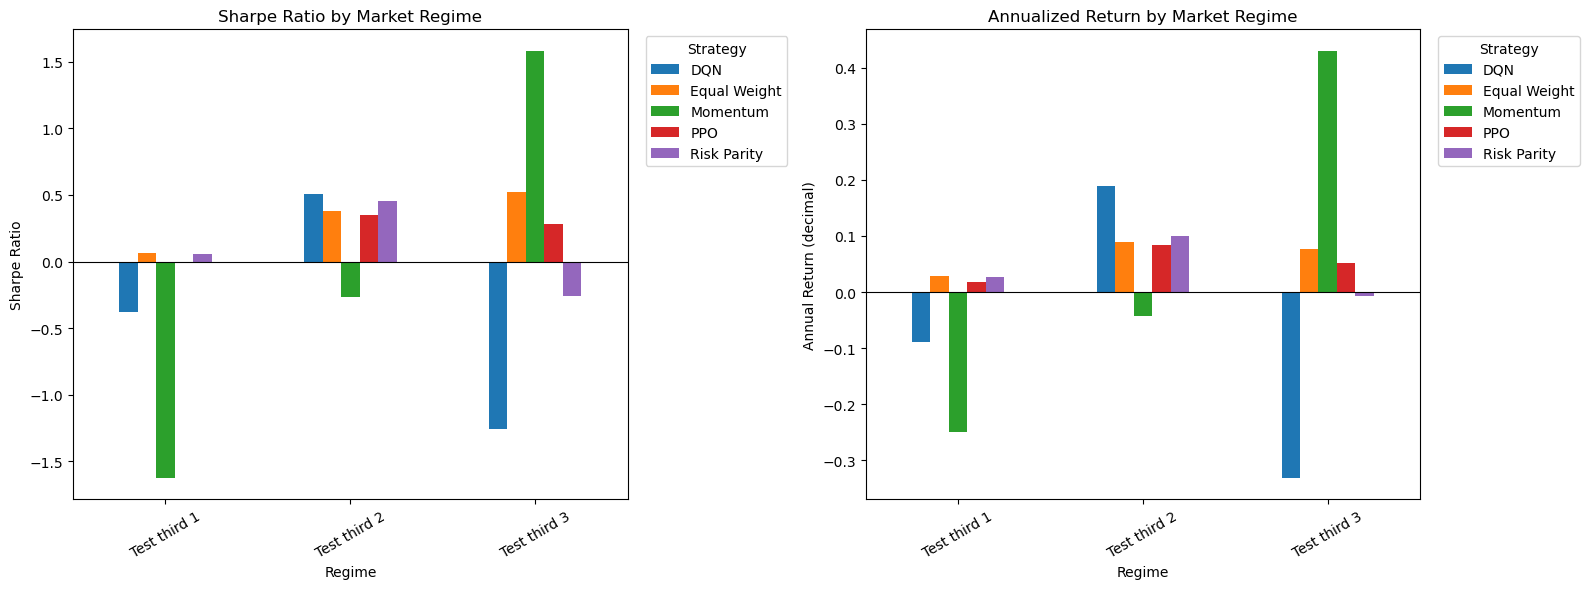

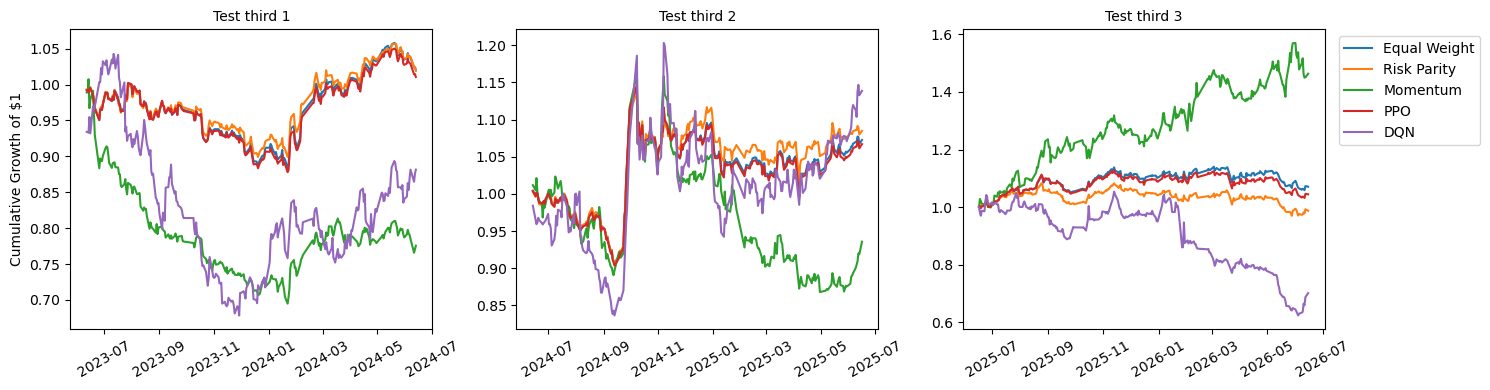

Strategy,DQN,Equal Weight,Momentum,PPO,Risk Parity
Regime,,,,,
Test third 1,-0.379,0.065,-1.621,-0.010,0.058
Test third 2,0.509,0.379,-0.266,0.348,0.454
Test third 3,-1.259,0.523,1.583,0.281,-0.256


In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ---- 0. Diagnostic: what period does the test set actually cover? ----
any_series = next(iter(results.values()))[0]
test_start, test_end = any_series.index.min(), any_series.index.max()
print(f"Test set covers: {test_start.date()} to {test_end.date()}")
print("\nConfigured REGIME_PERIODS:")
for name, (s, e) in REGIME_PERIODS.items():
    overlaps = pd.Timestamp(e) >= test_start and pd.Timestamp(s) <= test_end
    print(f"  {name}: {s} to {e}  -> overlaps test set: {overlaps}")

# ---- 1. Recompute per-regime metrics for every strategy (only overlapping regimes) ----
def collect_regime_metrics(results, regime_periods):
    records = []
    for regime, (start, end) in regime_periods.items():
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        for name, (rets, weights, turnovers) in results.items():
            mask = (rets.index >= start) & (rets.index <= end)
            sub_rets = rets[mask]
            if len(sub_rets) <= 5:
                continue
            sub_weights = weights[mask] if (weights is not None and len(weights) == len(rets)) else None
            sub_turnovers = turnovers[mask] if turnovers is not None else None
            m = performance_metrics(sub_rets, sub_weights, sub_turnovers)
            m["Regime"], m["Strategy"] = regime, name
            records.append(m)
    return pd.DataFrame(records)

regime_df = collect_regime_metrics(results, REGIME_PERIODS)

if regime_df.empty:
    print("\nNo configured regime windows overlap the test set — nothing to plot from REGIME_PERIODS.\n"
          "Define a regime that actually falls inside the test window printed above, e.g.:")
    print(f'    REGIME_PERIODS_ADHOC = {{"Test period": ("{test_start.date()}", "{test_end.date()}")}}')

    # Fallback: just plot the whole test period split into thirds, so you still get a robustness view
    thirds = np.array_split(any_series.index, 3)
    adhoc_periods = {
        f"Test third {i+1}": (t[0], t[-1]) for i, t in enumerate(thirds)
    }
    regime_df = collect_regime_metrics(results, adhoc_periods)
    regime_order = list(adhoc_periods.keys())
else:
    regime_order = [r for r in REGIME_PERIODS.keys() if r in regime_df["Regime"].unique()]

# ---- 2. Bar charts: Sharpe & Annual Return by regime ----
if not regime_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sharpe_pivot = regime_df.pivot(index="Regime", columns="Strategy", values="Sharpe").reindex(regime_order)
    sharpe_pivot.plot(kind="bar", ax=axes[0])
    axes[0].set_title("Sharpe Ratio by Market Regime")
    axes[0].set_ylabel("Sharpe Ratio")
    axes[0].axhline(0, color="black", linewidth=0.8)
    axes[0].tick_params(axis="x", rotation=30)
    axes[0].legend(title="Strategy", bbox_to_anchor=(1.02, 1), loc="upper left")

    ret_pivot = regime_df.pivot(index="Regime", columns="Strategy", values="AnnualReturn").reindex(regime_order)
    ret_pivot.plot(kind="bar", ax=axes[1])
    axes[1].set_title("Annualized Return by Market Regime")
    axes[1].set_ylabel("Annual Return (decimal)")
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].tick_params(axis="x", rotation=30)
    axes[1].legend(title="Strategy", bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

    # ---- 3. Cumulative growth of $1 within each regime ----
    periods_used = REGIME_PERIODS if any(r in REGIME_PERIODS for r in regime_order) else adhoc_periods
    n_regimes = len(regime_order)
    fig, axes = plt.subplots(1, n_regimes, figsize=(5 * n_regimes, 4))
    if n_regimes == 1:
        axes = [axes]

    for ax, regime in zip(axes, regime_order):
        start, end = periods_used[regime]
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        for name, (rets, weights, turnovers) in results.items():
            mask = (rets.index >= start) & (rets.index <= end)
            sub_rets = rets[mask]
            if len(sub_rets) <= 5:
                continue
            cum = (1 + sub_rets).cumprod()
            ax.plot(cum.index, cum.values, label=name)
        ax.set_title(regime, fontsize=10)
        ax.tick_params(axis="x", rotation=30)

    axes[0].set_ylabel("Cumulative Growth of $1")
    axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    display(sharpe_pivot.round(3))

In [ ]:


import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy.stats import norm

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# ===========================================================
# DEPENDENCY CHECKS
# ===========================================================

try:
    import gymnasium as gym
    from gymnasium import spaces
except ImportError:
    print("Missing dependency 'gymnasium'. Install with:\n    pip install gymnasium")
    sys.exit(1)

try:
    from stable_baselines3 import PPO, DQN
    from stable_baselines3.common.monitor import Monitor
except ImportError:
    print("Missing dependency 'stable-baselines3' (+ torch). Install with:\n"
          "    pip install stable-baselines3 torch")
    sys.exit(1)

try:
    import openpyxl  # noqa: F401  (pandas needs this engine for .xlsx)
except ImportError:
    print("Missing dependency 'openpyxl'. Install with:\n    pip install openpyxl")
    sys.exit(1)


# ===========================================================
# CONFIG
# ===========================================================

CSI300_PATH = r"C:\Users\brian\Downloads\Data\CSI300_constituents.xlsx"
CSI500_PATH = r"C:\Users\brian\Downloads\Data\CSI500_constituents.xlsx"
CSI1000_PATH = r"C:\Users\brian\Downloads\Data\CSI1000_constituents.xlsx"

UNIVERSE_FILE = "CSI300"   # "CSI300", "CSI500", "CSI1000", or "ALL"
TOP_N_TICKERS = 30

# Issue 4: chronological TRAIN / VALIDATION / TEST split (fractions must sum to 1.0)
TRAIN_FRAC = 0.60
VAL_FRAC = 0.20
TEST_FRAC = 0.20

TRANSACTION_COST = 0.001         # 10 bps per unit of turnover
RISK_AVERSION = 0.10             # weight on the volatility penalty in reward
RF_ANNUAL = 0.02                 # annual risk-free rate assumption
PERIODS_PER_YEAR = 252

PPO_TIMESTEPS = 30_000
DQN_TIMESTEPS = 30_000

# Issue 3: train several seeds so convergence claims aren't based on n=1
N_SEEDS = 3
SEEDS = [42, 43, 44][:N_SEEDS]

# Reward-curve moving-average window (in training episodes); auto-shrunk if
# fewer episodes than this are available.
REWARD_CURVE_MA_WINDOW = 5

STATE_FEATURES = [
    "Return", "MA10", "MA20", "MA50", "Volatility20",
    "Momentum20", "RSI14", "MACD", "MACD_Signal",
    "BB_Upper", "BB_Lower", "Volume",
]

REGIME_PERIODS = {
    "Bull (2016-2017)":      ("2016-01-01", "2017-12-31"),
    "Bear (2018)":           ("2018-01-01", "2018-12-31"),
    "COVID (2020 H1)":       ("2020-01-01", "2020-06-30"),
    "Post-COVID (2021-22)":  ("2021-01-01", "2022-12-31"),
}

SENSITIVITY_COSTS = [0.0, 0.001, 0.005, 0.01]
SENSITIVITY_REBALANCE = [1, 5, 20]   # days between rebalances

# Issue 5: Diebold-Mariano HAC (Newey-West style) lag length, stated explicitly
DM_HAC_LAG = 5

# Issue 5: bootstrap Sharpe-difference test settings
BOOTSTRAP_N = 2000
BOOTSTRAP_BLOCK = 20

SEED = SEEDS[0]
np.random.seed(SEED)


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


# ===========================================================
# 4.1  BLOOMBERG WORKBOOK PARSER
# ===========================================================

def parse_bloomberg_workbook(path, index_label):
    """
    Parses one Bloomberg-export workbook (CSI300 / CSI500 / CSI1000 style,
    many side-by-side ticker blocks) into a tidy long-format DataFrame.

    NOTE ON DATA PROVENANCE (issue 6): this parser assumes the Bloomberg
    export used ADJUSTED close prices (dividend- and split-adjusted, e.g.
    Bloomberg field PX_LAST with a total-return / adjusted override). If the
    underlying export instead used raw unadjusted prices, corporate actions
    (dividends, splits, rights issues) will appear as spurious jumps in
    Return/RSI/MACD etc. This should be verified against the Bloomberg field
    list used at export time and stated explicitly in the data section.
    Trading suspensions (a real feature of China A-shares) surface here as
    a run of NaNs for a ticker on days the market has data for other
    tickers; these are handled explicitly in clean_and_fill() rather than
    silently dropped, and every suspension-driven fill is logged.
    """
    print(f"  Reading {path} ...")
    raw = pd.read_excel(path, header=None, engine="openpyxl")
    n_cols = raw.shape[1]

    header_row = raw.iloc[0]
    block_starts = [
        c for c in range(n_cols)
        if isinstance(header_row.iloc[c], str) and "Equity" in header_row.iloc[c]
    ]

    frames = []
    skipped = 0
    for start in block_starts:
        end = min(start + 8, n_cols)
        ticker_cell = raw.iat[0, start]
        ticker = str(ticker_cell).replace(" Equity", "").strip()

        block = raw.iloc[2:, start:end].copy()
        if block.shape[1] < 8:
            for extra in range(8 - block.shape[1]):
                block[f"_pad{extra}"] = np.nan
        block.columns = ["Date", "Close", "Open", "High", "Low",
                          "Volume", "MktCap", "Turnover"]
        block = block.dropna(subset=["Date"])
        if block.empty:
            skipped += 1
            continue

        block["Ticker"] = ticker
        block["Index"] = index_label
        frames.append(block)

    if not frames:
        raise ValueError(f"No ticker blocks parsed from {path}")

    df = pd.concat(frames, ignore_index=True)
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    for col in ["Close", "Open", "High", "Low", "Volume", "MktCap", "Turnover"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["Date"])

    print(f"    Parsed {len(block_starts) - skipped} tickers, skipped {skipped} empty/blank blocks, "
          f"{len(df):,} raw rows")
    return df


def clean_and_fill(df):
    """
    Per-ticker forward-fill then back-fill of all price/volume fields.
    Issue 6: this is a deliberate, explicitly-logged treatment of trading
    suspensions and missing data, not a silent gap-fill. A field that is
    100% NaN for a ticker (Bloomberg never returned it at all) is filled
    with 0 and flagged as a data limitation. A field with a *partial* run
    of NaNs (a suspension) is forward/back-filled and counted separately
    so the magnitude of suspension-driven fills can be reported.
    """
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    fields = ["Close", "Open", "High", "Low", "Volume", "MktCap", "Turnover"]

    flagged_all_na = []
    suspension_fill_counts = {}

    def _fill(g):
        ticker_name = g.name
        g = g.set_index("Date")
        for f in fields:
            n_missing_before = g[f].isna().sum()
            before_all_na = g[f].isna().all()
            g[f] = g[f].ffill().bfill()
            if before_all_na:
                flagged_all_na.append((ticker_name, f))
                g[f] = g[f].fillna(0.0)
            elif n_missing_before > 0:
                suspension_fill_counts[ticker_name] = (
                    suspension_fill_counts.get(ticker_name, 0) + int(n_missing_before)
                )
        g["Ticker"] = ticker_name
        return g.reset_index()

    df = df.groupby("Ticker", group_keys=False).apply(_fill)

    if flagged_all_na:
        print(f"    NOTE: {len(flagged_all_na)} (ticker, field) pairs had NO data at all "
              f"from Bloomberg and were filled with 0 (limitation to report):")
        for t, f in flagged_all_na[:15]:
            print(f"      - {t}: {f}")
        if len(flagged_all_na) > 15:
            print(f"      ... and {len(flagged_all_na) - 15} more")

    if suspension_fill_counts:
        total_filled = sum(suspension_fill_counts.values())
        print(f"    NOTE: {total_filled} cell(s) across {len(suspension_fill_counts)} tickers were "
              f"forward/back-filled (likely trading suspensions or export gaps rather than "
              f"total absence of data). Report this as a limitation: suspension days receive "
              f"a stale price rather than being excluded from the panel.")

    return df


def compute_indicators(df):
    """Adds Return + technical indicators, per ticker, to the raw panel.
    All indicators are causal (rolling window / EWM using only current and
    past observations) — this satisfies the no-look-ahead requirement in
    issue 4 at the indicator-construction stage. Cross-sectional feature
    standardisation (z-scoring) is handled separately, using train-only
    statistics — see build_features_dataset().
    """
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    out = []
    for ticker, g in df.groupby("Ticker"):
        g = g.sort_values("Date").set_index("Date").copy()
        close = g["Close"]

        g["Return"] = close.pct_change()
        g["MA10"] = close.rolling(10).mean()
        g["MA20"] = close.rolling(20).mean()
        g["MA50"] = close.rolling(50).mean()
        g["Volatility20"] = g["Return"].rolling(20).std()
        g["Momentum20"] = close.pct_change(20)

        delta = close.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = (-delta.clip(upper=0)).rolling(14).mean()
        rs = gain / loss.replace(0, np.nan)
        g["RSI14"] = 100 - (100 / (1 + rs))
        g["RSI14"] = g["RSI14"].fillna(50.0)

        ema12 = close.ewm(span=12, adjust=False).mean()
        ema26 = close.ewm(span=26, adjust=False).mean()
        g["MACD"] = ema12 - ema26
        g["MACD_Signal"] = g["MACD"].ewm(span=9, adjust=False).mean()

        bb_mid = close.rolling(20).mean()
        bb_std = close.rolling(20).std()
        g["BB_Upper"] = bb_mid + 2 * bb_std
        g["BB_Lower"] = bb_mid - 2 * bb_std

        g["Ticker"] = ticker
        out.append(g.reset_index())

    df = pd.concat(out, ignore_index=True)
    df = df.dropna(subset=["Return"])
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    ind_cols = ["MA10", "MA20", "MA50", "Volatility20", "Momentum20",
                "RSI14", "MACD", "MACD_Signal", "BB_Upper", "BB_Lower"]
    df[ind_cols] = (
        df.groupby("Ticker", group_keys=False)[ind_cols]
        .apply(lambda g: g.ffill().bfill())
        .reset_index(drop=True)
    )
    return df


def build_raw_dataset():
    section("4.1 BUILDING RAW DATASET FROM BLOOMBERG WORKBOOKS")

    sources = {}
    if UNIVERSE_FILE in ("CSI300", "ALL"):
        sources["CSI300"] = CSI300_PATH
    if UNIVERSE_FILE in ("CSI500", "ALL"):
        sources["CSI500"] = CSI500_PATH
    if UNIVERSE_FILE in ("CSI1000", "ALL"):
        sources["CSI1000"] = CSI1000_PATH
    if not sources:
        raise ValueError(f"Unrecognised UNIVERSE_FILE setting: {UNIVERSE_FILE}")

    parsed = []
    for label, path in sources.items():
        parsed.append(parse_bloomberg_workbook(path, label))
    raw = pd.concat(parsed, ignore_index=True)

    core = ["Close", "Open", "High", "Low", "Volume"]
    completeness = (
        raw.groupby("Ticker")[core]
        .apply(lambda g: g.notna().mean().mean())
        .sort_values(ascending=False)
    )
    n_available = len(completeness)
    keep_n = min(TOP_N_TICKERS, n_available)
    selected_tickers = completeness.head(keep_n).index.tolist()

    print(f"\n  Universe file(s): {list(sources.keys())}")
    print(f"  Total tickers parsed: {n_available}")
    print(f"  Selected top {keep_n} tickers by data completeness for the RL universe.")
    print(f"  Completeness range of selected tickers: "
          f"{completeness.head(keep_n).min():.3f} - {completeness.head(keep_n).max():.3f} (fraction, decimal form)")

    # --- Issue 2: survivor bias, stated explicitly -------------------------
    print(f"\n  LIMITATION (survivor bias): the constituent list in "
          f"'{UNIVERSE_FILE}_constituents.xlsx' reflects index membership at the "
          f"time of the Bloomberg export (i.e. current/recent constituents), then "
          f"projected backward over the full sample period. Stocks that were "
          f"removed from the index earlier in the sample (delisted, acquired, or "
          f"dropped for underperformance) are excluded from the universe entirely. "
          f"This is a fixed EX-POST universe, not a point-in-time historical "
          f"constituent list, and it biases the sample toward stocks that survived "
          f"and remained investable through to the export date. Historical "
          f"point-in-time constituent data were not available for this study. The "
          f"study should therefore be described as: 'a fixed ex-post universe of "
          f"{keep_n} {UNIVERSE_FILE} constituent stocks selected based on data "
          f"completeness', and any absolute-return conclusions should be read as "
          f"an upper bound rather than a fully realistic, investable backtest.")
    # -------------------------------------------------------------------

    raw = raw[raw["Ticker"].isin(selected_tickers)].copy()
    raw = clean_and_fill(raw)
    raw = compute_indicators(raw)

    counts = raw.groupby("Date")["Ticker"].nunique()
    full_dates = counts[counts == keep_n].index
    raw = raw[raw["Date"].isin(full_dates)].copy()

    print(f"\n  Final dense panel: {raw['Date'].nunique():,} common trading days, "
          f"{keep_n} tickers")

    return raw, selected_tickers


def build_features_dataset(raw, train_dates):
    """
    Issue 4 & 6: per-ticker z-scored version of STATE_FEATURES, used as the
    RL agent's observation space. The z-scoring mean/std are computed using
    ONLY the training-period rows for each ticker, then applied unchanged to
    the training, validation and test rows. This prevents validation/test
    statistics (level or scale of the series) from leaking into the features
    the agent is trained on.
    """
    feat = raw[["Date", "Ticker"] + STATE_FEATURES].copy()
    train_dates_set = set(pd.DatetimeIndex(train_dates))

    def _zscore_train_only(g):
        train_mask = g["Date"].isin(train_dates_set)
        for col in STATE_FEATURES:
            train_vals = g.loc[train_mask, col]
            mu = train_vals.mean()
            sigma = train_vals.std()
            if not np.isfinite(sigma) or sigma == 0:
                g[col] = 0.0
            else:
                g[col] = (g[col] - mu) / sigma
        return g

    feat = feat.groupby("Ticker", group_keys=False).apply(_zscore_train_only)
    feat[STATE_FEATURES] = feat[STATE_FEATURES].fillna(0.0)
    return feat


# ===========================================================
# 4.2  DATA DESCRIPTION
# ===========================================================

def describe_dataset(raw, tickers):
    section("4.2 DATASET DESCRIPTION")
    print(f"Data source            : Bloomberg export ({UNIVERSE_FILE})")
    print(f"Stock universe          : {len(tickers)} Chinese A-share stocks (fixed ex-post "
          f"universe — see survivor-bias limitation in 4.1)")
    print(f"Tickers                 : {', '.join(tickers)}")
    print(f"Sample period           : {raw['Date'].min().date()} to {raw['Date'].max().date()}")
    print(f"Frequency               : Daily")
    print(f"Total observations      : {len(raw):,}")
    print(f"Train/Val/Test split    : {int(TRAIN_FRAC*100)}:{int(VAL_FRAC*100)}:{int(TEST_FRAC*100)} "
          f"(chronological; scaling fit on TRAIN only, see 4.4b)")
    print(f"Price basis             : assumed dividend/split-adjusted close from Bloomberg export "
          f"(verify export field — see note in parse_bloomberg_workbook)")
    print(f"Returns reporting basis : decimal (e.g. 0.0123 = 1.23%), not percentage, throughout")

    var_table = pd.DataFrame({
        "Variable": ["Return", "MA10/20/50", "RSI14", "Volatility20",
                     "Momentum20", "MACD / MACD_Signal", "BB_Upper/Lower", "Volume"],
        "Description": [
            "Daily percentage return (decimal form)",
            "10/20/50-day moving averages of close price",
            "14-day Relative Strength Index",
            "20-day rolling standard deviation of returns",
            "20-day price momentum",
            "MACD line and its 9-day EMA signal line",
            "Bollinger Bands (20-day, 2 std)",
            "Daily traded shares",
        ],
    })
    print("\nVariables collected:")
    print(var_table.to_string(index=False))


# ===========================================================
# 4.3  DESCRIPTIVE STATISTICS
# ===========================================================

def descriptive_statistics(raw):
    section("4.3 DESCRIPTIVE STATISTICS")
    cols = ["Return", "MA20", "Volatility20", "Momentum20", "RSI14", "Volume"]
    stats = raw[cols].agg(["mean", "std", "min", "max"]).T
    stats.columns = ["Mean", "Std Dev", "Min", "Max"]
    print(stats.round(4).to_string())

    ret_std = raw["Return"].std()
    ret_mean = raw["Return"].mean()
    print(f"\nInterpretation: daily returns average {ret_mean:.4f} (decimal) with a standard "
          f"deviation of {ret_std:.4f} (decimal), indicating considerable volatility typical "
          f"of Chinese A-share equities and providing a meaningful environment for "
          f"testing adaptive allocation strategies.")

    corr = raw.pivot(index="Date", columns="Ticker", values="Return").corr()
    print("\nCorrelation matrix of daily returns across assets:")
    print(corr.round(2).to_string())
    avg_corr = (corr.values[np.triu_indices_from(corr.values, k=1)]).mean()
    print(f"\nAverage pairwise correlation: {avg_corr:.3f} — "
          f"{'moderate diversification potential exists.' if avg_corr < 0.5 else 'limited diversification benefit given high co-movement.'}")
    return corr


# ===========================================================
# DATA PREP FOR MODELLING
# ===========================================================

def build_panels(raw, feat, tickers):
    returns_wide = raw.pivot(index="Date", columns="Ticker", values="Return")[tickers].dropna(how="any")
    vol_wide = raw.pivot(index="Date", columns="Ticker", values="Volatility20")[tickers].reindex(returns_wide.index)
    mom_wide = raw.pivot(index="Date", columns="Ticker", values="Momentum20")[tickers].reindex(returns_wide.index)

    feat_panels = {}
    for col in STATE_FEATURES:
        wide = feat.pivot(index="Date", columns="Ticker", values=col)[tickers]
        feat_panels[col] = wide.reindex(returns_wide.index).fillna(0.0)

    dates = returns_wide.index.sort_values()
    return dates, returns_wide, vol_wide, mom_wide, feat_panels


def chronological_split_3way(dates):
    """Issue 4: chronological TRAIN / VALIDATION / TEST split. The test set
    is touched exactly once (final evaluation); model/seed selection and any
    hyperparameter checks use the validation set only."""
    n = len(dates)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    dates_train = dates[:train_end]
    dates_val = dates[train_end:val_end]
    dates_test = dates[val_end:]
    return dates_train, dates_val, dates_test


def build_observation_matrix(dates, feat_panels, tickers):
    arrs = [feat_panels[col].loc[dates].values for col in STATE_FEATURES]
    obs = np.concatenate(arrs, axis=1).astype(np.float32)
    return obs


# ===========================================================
# CUSTOM PORTFOLIO ENVIRONMENT (used for TRAINING only)
# ===========================================================

class PortfolioEnv(gym.Env):
    """
    Markov Decision Process formulation:
        state  -> lagged technical indicators/returns (train-only z-scored)
                  concatenated with the previous portfolio weights
        action -> portfolio weights (continuous, softmax) or single-asset
                  pick (discrete)
        reward -> reward_t = net_return_t - risk_aversion * sum_i (w_i * vol_i)^2
                  where net_return_t = w . r_{t+1} - transaction_cost * turnover_t
                  and turnover_t = sum(|w_t - w_{t-1}|).
                  This is stated explicitly here per issue 3 (reward function
                  must be documented, not left implicit).

    REWARD REPORTING IMPROVEMENT: in addition to the scalar reward, this env
    tracks the three components that make it up — gross portfolio return,
    transaction cost, and the volatility (risk) penalty — as per-step
    averages for every completed training episode, in
    `self.episode_component_log`. This lets the training-report functions
    show whether a flat overall reward is actually flat in every component,
    or whether e.g. an improving return is being offset by rising costs.
    """
    metadata = {"render_modes": []}

    def __init__(self, dates, returns_wide, vol_wide, feat_panels, tickers,
                 mode="continuous", transaction_cost=TRANSACTION_COST,
                 risk_aversion=RISK_AVERSION):
        super().__init__()
        self.dates = list(dates)
        self.returns_wide = returns_wide
        self.vol_wide = vol_wide
        self.n_assets = len(tickers)
        self.mode = mode
        self.tc = transaction_cost
        self.risk_aversion = risk_aversion

        self.obs_matrix = build_observation_matrix(self.dates, feat_panels, tickers)
        n_features_total = self.obs_matrix.shape[1] + self.n_assets

        self.observation_space = spaces.Box(
            low=-20.0, high=20.0, shape=(n_features_total,), dtype=np.float32
        )
        if mode == "continuous":
            self.action_space = spaces.Box(
                low=-5.0, high=5.0, shape=(self.n_assets,), dtype=np.float32
            )
        else:
            self.action_space = spaces.Discrete(self.n_assets)

        self.t = None
        self.prev_weights = None

        # --- Reward-component tracking (per training episode) --------------
        # Accumulated within the current (in-progress) episode:
        self._ep_gross_return_sum = 0.0
        self._ep_cost_sum = 0.0
        self._ep_risk_penalty_sum = 0.0
        self._ep_reward_sum = 0.0
        self._ep_len = 0
        # One dict per COMPLETED episode, each holding per-step averages:
        self.episode_component_log = []

    def _flush_episode_if_any(self):
        """Append the just-finished episode's per-step-average components to
        the log. Called from reset() (so a full episode is captured before
        starting the next one) and again at the very end of training via
        flush_pending_episode(), since SB3's .learn() can stop mid-episode
        and that partial episode would otherwise never be logged."""
        if self._ep_len > 0:
            self.episode_component_log.append({
                "avg_gross_return": self._ep_gross_return_sum / self._ep_len,
                "avg_cost": self._ep_cost_sum / self._ep_len,
                "avg_risk_penalty": self._ep_risk_penalty_sum / self._ep_len,
                "avg_reward": self._ep_reward_sum / self._ep_len,
                "length": self._ep_len,
            })
            self._ep_gross_return_sum = 0.0
            self._ep_cost_sum = 0.0
            self._ep_risk_penalty_sum = 0.0
            self._ep_reward_sum = 0.0
            self._ep_len = 0

    def flush_pending_episode(self):
        """Public wrapper: call this once after model.learn() finishes, so
        a final in-progress episode is not silently dropped from the log."""
        self._flush_episode_if_any()

    def _get_obs(self):
        base = self.obs_matrix[self.t]
        return np.concatenate([base, self.prev_weights]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self._flush_episode_if_any()
        self.t = 0
        self.prev_weights = np.ones(self.n_assets, dtype=np.float32) / self.n_assets
        return self._get_obs(), {}

    def step(self, action):
        if self.mode == "continuous":
            exp_a = np.exp(action - np.max(action))
            weights = exp_a / exp_a.sum()
        else:
            weights = np.zeros(self.n_assets, dtype=np.float32)
            weights[int(action)] = 1.0

        turnover = np.sum(np.abs(weights - self.prev_weights))
        cost = self.tc * turnover

        next_date = self.dates[self.t + 1]
        asset_returns = self.returns_wide.loc[next_date].values
        gross_return = float(np.dot(weights, asset_returns))
        net_return = gross_return - cost

        vol_today = self.vol_wide.loc[self.dates[self.t]].fillna(0).values
        risk_penalty = self.risk_aversion * float(np.sum((weights * vol_today) ** 2))

        reward = net_return - risk_penalty

        # --- accumulate reward components for this episode -----------------
        self._ep_gross_return_sum += gross_return
        self._ep_cost_sum += cost
        self._ep_risk_penalty_sum += risk_penalty
        self._ep_reward_sum += reward
        self._ep_len += 1

        self.prev_weights = weights
        self.t += 1
        terminated = self.t >= len(self.dates) - 1
        truncated = False

        info = {"net_return": net_return, "weights": weights.copy(), "turnover": turnover,
                "gross_return": gross_return, "cost": cost, "risk_penalty": risk_penalty}
        obs = self._get_obs() if not terminated else np.zeros_like(self._get_obs())
        return obs, reward, terminated, truncated, info


# ===========================================================
# 4.4  DRL TRAINING (multi-seed) + 4.4b VALIDATION MODEL SELECTION
# ===========================================================

def _convergence_stats(monitor_env):
    """Returns overall reward convergence stats (as before) PLUS, if the
    wrapped env logged per-episode reward components, a first-half vs
    second-half breakdown of each component (return / cost / risk penalty)
    separately from the combined reward — see REWARD REPORTING IMPROVEMENT
    at the top of this file. The raw per-episode component DataFrame is
    also attached (key "component_log") so the caller can build a
    moving-average reward curve; the caller should pop it before turning
    the stats dict into a results table."""
    ep_rewards = monitor_env.get_episode_rewards()
    if len(ep_rewards) == 0:
        return None
    half = max(1, len(ep_rewards) // 2)
    first_half, second_half = ep_rewards[:half], ep_rewards[half:]
    stats = {
        "n_episodes": len(ep_rewards),
        "first_half_mean": float(np.mean(first_half)),
        "first_half_std": float(np.std(first_half)),
        "second_half_mean": float(np.mean(second_half)),
        "second_half_std": float(np.std(second_half)),
    }

    base_env = monitor_env.unwrapped
    comp_log = getattr(base_env, "episode_component_log", [])
    if comp_log:
        comp_df = pd.DataFrame(comp_log)
        half_c = max(1, len(comp_df) // 2)
        first_c, second_c = comp_df.iloc[:half_c], comp_df.iloc[half_c:]
        for col in ["avg_gross_return", "avg_cost", "avg_risk_penalty", "avg_reward"]:
            stats[f"{col}_first_half"] = float(first_c[col].mean())
            stats[f"{col}_second_half"] = float(second_c[col].mean())
        stats["component_log"] = comp_df
    return stats


def _print_reward_curve(comp_df, seed_label, window=REWARD_CURVE_MA_WINDOW):
    """Prints a moving-average reward curve across training episodes for one
    seed, decomposed into return / cost / risk-penalty components (not just
    the combined reward), and saves a plot if matplotlib is available."""
    if comp_df is None or len(comp_df) == 0:
        return
    n = len(comp_df)
    w = max(1, min(window, n))
    cols = ["avg_reward", "avg_gross_return", "avg_cost", "avg_risk_penalty"]
    ma = comp_df[cols].rolling(window=w, min_periods=1).mean()
    ma.index = pd.RangeIndex(1, n + 1)
    ma.index.name = "Episode"
    ma.columns = [f"MA({w}) Reward", f"MA({w}) Return", f"MA({w}) Cost", f"MA({w}) RiskPenalty"]

    print(f"\n  [{seed_label}] moving-average (window={w}) per-step reward curve "
          f"across {n} training episode(s):")
    print(ma.round(6).to_string())

    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.plot(ma.index, ma.iloc[:, 0], label="Reward (net of cost & risk penalty)", linewidth=2)
        ax.plot(ma.index, ma.iloc[:, 1], label="Portfolio return (gross)", linestyle="--")
        ax.plot(ma.index, -ma.iloc[:, 2], label="- Transaction cost", linestyle="--")
        ax.plot(ma.index, -ma.iloc[:, 3], label="- Risk penalty", linestyle="--")
        ax.axhline(0, color="grey", linewidth=0.8)
        ax.set_xlabel("Training episode")
        ax.set_ylabel("Per-step value (decimal)")
        ax.set_title(f"Reward decomposition — {seed_label} (MA window={w})")
        ax.legend(fontsize=8)
        fig.tight_layout()
        safe_name = seed_label.replace(" ", "_").replace("/", "_")
        out_path = f"reward_curve_{safe_name}.png"
        fig.savefig(out_path, dpi=140)
        plt.close(fig)
        print(f"  Saved reward-decomposition plot to {out_path}")
    except ImportError:
        pass


def train_agents_multiseed(dates_train, dates_val, returns_wide, vol_wide, mom_wide,
                            feat_panels, tickers):
    """Issue 3 & 4: train PPO and DQN across N_SEEDS seeds, report a
    convergence table with a mean and a (normal-approx) 95% CI across seeds
    for the second-half training reward, then evaluate every seed's model on
    the VALIDATION split (never the test split) and pick the seed with the
    best validation Sharpe ratio as the final model per architecture.

    REWARD REPORTING IMPROVEMENT: the reward summary printed here now also
    breaks the combined reward down into portfolio return, transaction cost
    and volatility penalty, and prints a moving-average reward curve per
    seed, so a flat overall-reward trend cannot silently conceal an
    improving (or offset) underlying portfolio return."""
    section("4.4 DRL TRAINING PERFORMANCE (multi-seed)")

    ppo_records, dqn_records = [], []
    ppo_models, dqn_models = {}, {}
    ppo_comp_logs, dqn_comp_logs = {}, {}

    for seed in SEEDS:
        env_ppo = Monitor(PortfolioEnv(dates_train, returns_wide, vol_wide, feat_panels,
                                        tickers, mode="continuous"))
        env_dqn = Monitor(PortfolioEnv(dates_train, returns_wide, vol_wide, feat_panels,
                                        tickers, mode="discrete"))

        print(f"\n  [seed {seed}] Training PPO for {PPO_TIMESTEPS:,} timesteps ...")
        ppo_model = PPO("MlpPolicy", env_ppo, seed=seed, verbose=0)
        ppo_model.learn(total_timesteps=PPO_TIMESTEPS)
        env_ppo.unwrapped.flush_pending_episode()
        ppo_models[seed] = ppo_model
        stats = _convergence_stats(env_ppo)
        if stats:
            comp_df = stats.pop("component_log", None)
            stats["seed"] = seed
            ppo_records.append(stats)
            if comp_df is not None:
                ppo_comp_logs[seed] = comp_df

        print(f"  [seed {seed}] Training DQN for {DQN_TIMESTEPS:,} timesteps ...")
        dqn_model = DQN("MlpPolicy", env_dqn, seed=seed, verbose=0)
        dqn_model.learn(total_timesteps=DQN_TIMESTEPS)
        env_dqn.unwrapped.flush_pending_episode()
        dqn_models[seed] = dqn_model
        stats = _convergence_stats(env_dqn)
        if stats:
            comp_df = stats.pop("component_log", None)
            stats["seed"] = seed
            dqn_records.append(stats)
            if comp_df is not None:
                dqn_comp_logs[seed] = comp_df

    def _report(name, records, comp_logs):
        if not records:
            print(f"\n{name}: no completed episodes logged for any seed (increase timesteps).")
            return
        df = pd.DataFrame(records).set_index("seed")
        print(f"\n{name} reward curve across {len(records)} seed(s):")
        print(df[["n_episodes", "first_half_mean", "first_half_std",
                   "second_half_mean", "second_half_std"]].round(5).to_string())

        second_half_means = df["second_half_mean"].values
        mean_across_seeds = second_half_means.mean()
        if len(second_half_means) > 1:
            se = second_half_means.std(ddof=1) / np.sqrt(len(second_half_means))
            ci_low, ci_high = mean_across_seeds - 1.96 * se, mean_across_seeds + 1.96 * se
            print(f"  Mean second-half reward across seeds : {mean_across_seeds:.5f}  "
                  f"(95% CI [{ci_low:.5f}, {ci_high:.5f}], n_seeds={len(second_half_means)})")
        else:
            print(f"  Mean second-half reward (single seed): {mean_across_seeds:.5f} "
                  f"— CI not meaningful with n_seeds=1; add more seeds before claiming convergence.")
        improved_fraction = (df["second_half_mean"] > df["first_half_mean"]).mean()
        print(f"  Fraction of seeds with 2nd-half > 1st-half mean reward: {improved_fraction:.0%}")
        print(f"  Interpretation: convergence evidence is {'reasonably consistent' if improved_fraction >= 0.66 else 'mixed/weak'} "
              f"across seeds; with only {len(second_half_means)} seed(s) this remains a limited basis "
              f"for a strong convergence claim, and additional seeds/timesteps are recommended before "
              f"asserting 'stable convergence' in the final write-up.")

        # --- REWARD REPORTING IMPROVEMENT: component breakdown -------------
        comp_cols = [c for c in df.columns if c.split("_first_half")[0].split("_second_half")[0]
                     in ("avg_gross_return", "avg_cost", "avg_risk_penalty", "avg_reward")]
        if comp_cols:
            print(f"\n{name} reward-component breakdown (per-step averages, first half vs "
                  f"second half of training, by seed) — a flat combined reward can conceal "
                  f"an improving return offset by rising costs/penalty, so these are reported "
                  f"separately:")
            print(df[sorted(comp_cols)].round(6).to_string())

            avg_return_delta = (df["avg_gross_return_second_half"] - df["avg_gross_return_first_half"]).mean()
            avg_cost_delta = (df["avg_cost_second_half"] - df["avg_cost_first_half"]).mean()
            avg_penalty_delta = (df["avg_risk_penalty_second_half"] - df["avg_risk_penalty_first_half"]).mean()
            avg_reward_delta = (df["avg_reward_second_half"] - df["avg_reward_first_half"]).mean()
            print(f"\n  Mean change (2nd half minus 1st half) across seeds, per step:")
            print(f"    Reward       : {avg_reward_delta:+.6f}")
            print(f"    Return       : {avg_return_delta:+.6f}")
            print(f"    Cost         : {avg_cost_delta:+.6f}")
            print(f"    Risk penalty : {avg_penalty_delta:+.6f}")
            if abs(avg_reward_delta) < 1e-5 and (
                abs(avg_return_delta) > 1e-5 or abs(avg_cost_delta) > 1e-5 or abs(avg_penalty_delta) > 1e-5
            ):
                print("  NOTE: the combined reward is roughly flat across training, but its "
                      "components are NOT — e.g. an improving portfolio return may be being "
                      "offset by a rising transaction-cost or risk-penalty term (or the "
                      "reverse). Do not read a flat overall reward as 'no learning happened' "
                      "without checking the component breakdown above.")

        # --- REWARD REPORTING IMPROVEMENT: moving-average reward curve -----
        for seed, comp_df in comp_logs.items():
            _print_reward_curve(comp_df, seed_label=f"{name} seed {seed}")

    _report("PPO", ppo_records, ppo_comp_logs)
    _report("DQN", dqn_records, dqn_comp_logs)

    # --- Issue 3/4: validation-based model (seed) selection -----------------
    section("4.4b VALIDATION-SET MODEL SELECTION (no test-set peeking)")

    def _val_sharpe(model, mode):
        rets, _, _ = rollout_agent(model, dates_val, returns_wide, vol_wide, feat_panels,
                                    tickers, mode, TRANSACTION_COST, rebalance_freq=1)
        m = performance_metrics(rets)
        return m["Sharpe"]

    ppo_val_scores = {seed: _val_sharpe(model, "continuous") for seed, model in ppo_models.items()}
    dqn_val_scores = {seed: _val_sharpe(model, "discrete") for seed, model in dqn_models.items()}

    print("PPO validation Sharpe by seed:", {k: round(v, 4) if v == v else np.nan for k, v in ppo_val_scores.items()})
    print("DQN validation Sharpe by seed:", {k: round(v, 4) if v == v else np.nan for k, v in dqn_val_scores.items()})

    best_ppo_seed = max(ppo_val_scores, key=lambda s: (ppo_val_scores[s] if ppo_val_scores[s] == ppo_val_scores[s] else -np.inf))
    best_dqn_seed = max(dqn_val_scores, key=lambda s: (dqn_val_scores[s] if dqn_val_scores[s] == dqn_val_scores[s] else -np.inf))
    print(f"\nSelected PPO seed = {best_ppo_seed} (validation Sharpe = {ppo_val_scores[best_ppo_seed]:.4f})")
    print(f"Selected DQN seed = {best_dqn_seed} (validation Sharpe = {dqn_val_scores[best_dqn_seed]:.4f})")
    print("Note: hyperparameters (PPO/DQN defaults, timesteps, risk_aversion, transaction_cost) "
          "were fixed a priori and were NOT tuned against validation or test performance in this "
          "run; only the training seed was selected using validation data. Any future hyperparameter "
          "search should also be confined to the validation split.")

    return ppo_models[best_ppo_seed], dqn_models[best_dqn_seed]


# ===========================================================
# ROLLOUTS (unified for benchmarks and DRL agents)
# ===========================================================
# Issue 1 fix: every strategy below now (a) pays an initial-purchase
# turnover cost on day 0, (b) lets weights DRIFT with realised returns
# between rebalance dates (buy-and-hold drift), and (c) only recomputes
# a target weight / charges turnover on actual rebalance days. This is
# what makes turnover properly non-zero and frequency-sensitive.

def _drift_weights(w, asset_ret):
    drifted = w * (1.0 + asset_ret)
    s = drifted.sum()
    return drifted / s if s > 0 else w


def rollout_weight_strategy(weight_fn, dates_test, returns_wide, vol_wide, mom_wide,
                             n_assets, transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    dates_test = list(dates_test)
    current_w = np.zeros(n_assets)  # start from cash (issue 1: charge the initial purchase)
    rets, weights, turnovers = [], [], []

    for i in range(len(dates_test) - 1):
        date = dates_test[i]
        if i % rebalance_freq == 0:
            target_w = weight_fn(date, vol_wide, mom_wide, n_assets)
            turnover = np.sum(np.abs(target_w - current_w))
            current_w = target_w
        else:
            turnover = 0.0

        next_date = dates_test[i + 1]
        asset_ret = returns_wide.loc[next_date].values
        net_ret = float(np.dot(current_w, asset_ret) - transaction_cost * turnover)

        rets.append(net_ret)
        weights.append(current_w.copy())
        turnovers.append(turnover)

        current_w = _drift_weights(current_w, asset_ret)

    idx = dates_test[1:1 + len(rets)]
    return pd.Series(rets, index=idx), np.array(weights), pd.Series(turnovers, index=idx)


def equal_weight_fn(date, vol_wide, mom_wide, n):
    return np.ones(n) / n


def risk_parity_fn(date, vol_wide, mom_wide, n):
    vol = vol_wide.loc[date].values.astype(float)
    vol = np.where((vol <= 0) | np.isnan(vol), 1e-6, vol)
    inv = 1.0 / vol
    return inv / inv.sum()


def momentum_fn(date, vol_wide, mom_wide, n):
    mom = mom_wide.loc[date].values.astype(float)
    mom = np.nan_to_num(mom, nan=0.0)
    pos = np.clip(mom, 0, None)
    if pos.sum() <= 0:
        return np.ones(n) / n
    return pos / pos.sum()


def rollout_agent(model, dates_test, returns_wide, vol_wide, feat_panels, tickers, mode,
                   transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    """Rolls a trained SB3 model forward without relying on env.step(), so
    that non-daily rebalancing (issue 6: DRL sensitivity to rebalance
    frequency) and drift-based turnover (issue 1) are handled identically
    to the benchmark strategies above."""
    dates_test = list(dates_test)
    n = len(tickers)
    obs_matrix = build_observation_matrix(dates_test, feat_panels, tickers)

    current_w = np.zeros(n, dtype=np.float64)  # start from cash
    rets, weights, turnovers = [], [], []

    for i in range(len(dates_test) - 1):
        obs = np.concatenate([obs_matrix[i], current_w.astype(np.float32)]).astype(np.float32)
        if i % rebalance_freq == 0:
            action, _ = model.predict(obs, deterministic=True)
            if mode == "continuous":
                exp_a = np.exp(action - np.max(action))
                target_w = (exp_a / exp_a.sum()).astype(np.float64)
            else:
                target_w = np.zeros(n)
                target_w[int(action)] = 1.0
            turnover = np.sum(np.abs(target_w - current_w))
            current_w = target_w
        else:
            turnover = 0.0

        next_date = dates_test[i + 1]
        asset_ret = returns_wide.loc[next_date].values
        net_ret = float(np.dot(current_w, asset_ret) - transaction_cost * turnover)

        rets.append(net_ret)
        weights.append(current_w.copy())
        turnovers.append(turnover)

        current_w = _drift_weights(current_w, asset_ret)

    idx = dates_test[1:1 + len(rets)]
    return pd.Series(rets, index=idx), np.array(weights), pd.Series(turnovers, index=idx)


# ===========================================================
# PERFORMANCE METRICS
# ===========================================================

def performance_metrics(returns, weights=None, turnover_series=None, benchmark_returns=None,
                         rf_annual=RF_ANNUAL, periods_per_year=PERIODS_PER_YEAR):
    r = pd.Series(returns).dropna()
    if len(r) == 0 or r.std() == 0:
        return dict(AnnualReturn=np.nan, AnnualVol=np.nan, Sharpe=np.nan,
                    Sortino=np.nan, MaxDrawdown=np.nan, Calmar=np.nan,
                    InformationRatio=np.nan, Turnover=np.nan)

    ann_return = r.mean() * periods_per_year          # decimal, not %
    ann_vol = r.std() * np.sqrt(periods_per_year)
    rf_daily = rf_annual / periods_per_year
    sharpe = (r.mean() - rf_daily) / r.std() * np.sqrt(periods_per_year)

    downside = r[r < 0]
    downside_dev = downside.std() * np.sqrt(periods_per_year) if len(downside) > 1 else np.nan
    sortino = (ann_return - rf_annual) / downside_dev if downside_dev and downside_dev > 0 else np.nan

    cum = (1 + r).cumprod()
    drawdown = cum / cum.cummax() - 1
    max_dd = drawdown.min()
    calmar = ann_return / abs(max_dd) if max_dd != 0 else np.nan

    ir = np.nan
    if benchmark_returns is not None:
        bench = pd.Series(benchmark_returns).reindex(r.index).fillna(0)
        active = r - bench
        if active.std() > 0:
            ir = active.mean() / active.std() * np.sqrt(periods_per_year)

    # Issue 1: turnover taken directly from the tracked turnover series
    # (actual trading turnover), not re-derived from raw weight diffs
    # (which would also pick up passive drift and understate/overstate cost).
    if turnover_series is not None:
        turnover = pd.Series(turnover_series).mean()
    elif weights is not None and len(weights) > 1:
        w = np.array(weights)
        turnover = np.mean(np.sum(np.abs(np.diff(w, axis=0)), axis=1))
    else:
        turnover = np.nan

    return dict(AnnualReturn=ann_return, AnnualVol=ann_vol, Sharpe=sharpe,
                Sortino=sortino, MaxDrawdown=max_dd, Calmar=calmar,
                InformationRatio=ir, Turnover=turnover)


# ===========================================================
# STATISTICAL TESTS
# ===========================================================

def jobson_korkie_memmel(returns1, returns2):
    """Jobson-Korkie (1981) test with Memmel (1999) small-sample correction.
    H0: Sharpe(returns1) == Sharpe(returns2). Returns (sr1, sr2, z, p)."""
    r1, r2 = pd.Series(returns1).align(pd.Series(returns2), join="inner")
    r1, r2 = r1.dropna().values, r2.dropna().values
    n = min(len(r1), len(r2))
    r1, r2 = r1[:n], r2[:n]
    mu1, mu2 = r1.mean(), r2.mean()
    s1, s2 = r1.std(ddof=1), r2.std(ddof=1)
    if s1 == 0 or s2 == 0 or n < 3:
        return np.nan, np.nan, np.nan, np.nan
    sigma12 = np.cov(r1, r2, ddof=1)[0, 1]
    sr1, sr2 = mu1 / s1, mu2 / s2
    theta = (1 / n) * (2 * s1**2 * s2**2 - 2 * s1 * s2 * sigma12
                        + 0.5 * mu1**2 * s2**2 + 0.5 * mu2**2 * s1**2
                        - (mu1 * mu2 / (s1 * s2)) * sigma12**2)
    if theta <= 0:
        return sr1, sr2, np.nan, np.nan
    z = (s2 * mu1 - s1 * mu2) / np.sqrt(theta)
    p = 2 * (1 - norm.cdf(abs(z)))
    return sr1, sr2, z, p


def diebold_mariano(loss1, loss2, h=DM_HAC_LAG):
    """
    Diebold-Mariano test on the loss differential d_t = loss1_t - loss2_t,
    where loss_t = -daily_return_t (a lower loss = a better daily outcome).
    H0: E[d_t] = 0, i.e. strategy 1 and strategy 2 have equal average
    performance/predictive loss. A positive DM statistic means strategy 1
    has HIGHER average loss (i.e. WORSE performance) than strategy 2 in this
    sample; a negative statistic means strategy 1 outperforms strategy 2.
    Variance of the mean loss differential is estimated with a Newey-West /
    HAC correction using h-1 lags (h = DM_HAC_LAG, stated explicitly here
    per issue 5) to account for serial correlation in daily returns.
    """
    l1, l2 = pd.Series(loss1).align(pd.Series(loss2), join="inner")
    d = (l1 - l2).dropna().values
    T = len(d)
    if T < 5:
        return np.nan, np.nan
    d_mean = d.mean()
    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        if lag < T:
            cov = np.cov(d[:-lag], d[lag:])[0, 1]
            weight = 1.0 - lag / h  # Newey-West / Bartlett kernel weight
            var_d += 2 * weight * cov
    var_d = var_d / T
    if var_d <= 0:
        return np.nan, np.nan
    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - norm.cdf(abs(dm_stat)))
    return dm_stat, p_value


def bootstrap_sharpe_diff_test(returns1, returns2, n_boot=BOOTSTRAP_N, block_size=BOOTSTRAP_BLOCK,
                                rf_annual=RF_ANNUAL, periods_per_year=PERIODS_PER_YEAR, seed=SEED):
    """
    Issue 5 (robustness alternative to JK/Memmel): a stationary/circular
    block-bootstrap test of H0: Sharpe(returns1) == Sharpe(returns2), in the
    spirit of HAC-robust Sharpe-ratio comparisons (e.g. Ledoit-Wolf-style
    bootstrap tests). Resampling in overlapping blocks of `block_size` days
    preserves short-run serial correlation/volatility clustering that an
    i.i.d. bootstrap would destroy. Returns (observed Sharpe difference,
    two-sided bootstrap p-value, 95% CI of the difference).
    """
    r1, r2 = pd.Series(returns1).align(pd.Series(returns2), join="inner")
    r1, r2 = r1.dropna().values, r2.dropna().values
    n = min(len(r1), len(r2))
    r1, r2 = r1[:n], r2[:n]
    if n < block_size * 2:
        return np.nan, np.nan, (np.nan, np.nan)

    rf_daily = rf_annual / periods_per_year

    def _sharpe(x):
        s = x.std()
        return (x.mean() - rf_daily) / s * np.sqrt(periods_per_year) if s > 0 else np.nan

    obs_diff = _sharpe(r1) - _sharpe(r2)

    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block_size))
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, n, size=n_blocks)
        idx = np.concatenate([(s + np.arange(block_size)) % n for s in starts])[:n]
        diffs[b] = _sharpe(r1[idx]) - _sharpe(r2[idx])

    diffs = diffs[np.isfinite(diffs)]
    if len(diffs) == 0:
        return obs_diff, np.nan, (np.nan, np.nan)
    p_value = 2 * min((diffs >= 0).mean(), (diffs <= 0).mean())
    p_value = min(p_value, 1.0)
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, p_value, (ci_low, ci_high)


# ===========================================================
# 4.5 PORTFOLIO PERFORMANCE COMPARISON
# ===========================================================

def evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                             tickers, ppo_model, dqn_model,
                             transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    n = len(tickers)
    results = {}

    results["Equal Weight"] = rollout_weight_strategy(
        equal_weight_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["Risk Parity"] = rollout_weight_strategy(
        risk_parity_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["Momentum"] = rollout_weight_strategy(
        momentum_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["PPO"] = rollout_agent(
        ppo_model, dates_test, returns_wide, vol_wide, feat_panels, tickers,
        "continuous", transaction_cost, rebalance_freq)
    results["DQN"] = rollout_agent(
        dqn_model, dates_test, returns_wide, vol_wide, feat_panels, tickers,
        "discrete", transaction_cost, rebalance_freq)
    return results


def performance_table(results, benchmark_name="Equal Weight"):
    bench_returns = results[benchmark_name][0]
    rows = []
    for name, (rets, weights, turnovers) in results.items():
        m = performance_metrics(rets, weights, turnovers, benchmark_returns=bench_returns)
        m["Strategy"] = name
        rows.append(m)
    df = pd.DataFrame(rows).set_index("Strategy")
    df = df[["AnnualReturn", "Sharpe", "MaxDrawdown", "InformationRatio",
              "Sortino", "Calmar", "Turnover"]]
    df.columns = ["Annual Return (dec.)", "Sharpe", "Max Drawdown (dec.)", "Information Ratio",
                  "Sortino", "Calmar", "Avg Daily Turnover"]
    return df.round(4)


def portfolio_comparison(results):
    section("4.5 PORTFOLIO PERFORMANCE COMPARISON")
    table = performance_table(results)
    print(table.to_string())

    if (table["Avg Daily Turnover"].abs() < 1e-9).all():
        print("\nWARNING: all strategies show ~zero average turnover — this would indicate the "
              "rebalancing/turnover accounting is broken. Re-check rollout logic before proceeding.")

    best_return = table["Annual Return (dec.)"].idxmax()
    best_sharpe = table["Sharpe"].idxmax()
    best_dd = table["Max Drawdown (dec.)"].idxmax()
    print(f"\nHighest annual return : {best_return}")
    print(f"Highest Sharpe ratio   : {best_sharpe}")
    print(f"Smallest drawdown      : {best_dd}")
    print(f"\nInterpretation: {best_sharpe} achieves the strongest risk-adjusted "
          f"performance in this run. Whether this reflects a DRL model or a static "
          f"benchmark, the ranking reflects a single test-set run under one set of "
          f"training seeds; statistical significance is assessed in 4.6, and this "
          f"ranking should be corroborated with the robustness/sensitivity checks "
          f"in 4.7 and 4.7b before drawing firm conclusions.")
    return table


# ===========================================================
# 4.6 STATISTICAL TESTS
# ===========================================================

def statistical_tests(results):
    section("4.6 STATISTICAL TESTS")

    pairs = [("PPO", "DQN"), ("PPO", "Equal Weight"), ("PPO", "Momentum"),
             ("DQN", "Equal Weight"), ("DQN", "Momentum"),
             ("Momentum", "Risk Parity")]

    print("Jobson-Korkie / Memmel test — H0: Sharpe(A) = Sharpe(B). Direction of any "
          "significant result is reported explicitly (the strategy with the HIGHER "
          "Sharpe ratio is the one favoured by the test, regardless of listing order).\n")
    jk_rows = []
    for a, b in pairs:
        sr1, sr2, z, p = jobson_korkie_memmel(results[a][0], results[b][0])
        if p == p and p < 0.05:
            winner = a if sr1 > sr2 else b
            decision = f"Reject H0 — {winner} has significantly higher Sharpe"
        else:
            decision = "Fail to reject H0 (no significant Sharpe difference)"
        jk_rows.append({"Comparison": f"{a} vs {b}", f"Sharpe({a})": round(sr1, 3) if sr1 == sr1 else np.nan,
                         f"Sharpe({b})": round(sr2, 3) if sr2 == sr2 else np.nan,
                         "Z": round(z, 3) if z == z else np.nan,
                         "p-value": round(p, 4) if p == p else np.nan, "Decision": decision})
    jk_table = pd.DataFrame(jk_rows)
    print(jk_table.to_string(index=False))

    print(f"\nDiebold-Mariano test — loss_t = -daily_return_t, H0: E[loss(A) - loss(B)] = 0 "
          f"(equal average performance), HAC/Newey-West variance with lag = {DM_HAC_LAG}. "
          f"A positive statistic means A had HIGHER average loss (WORSE performance) than B; "
          f"negative means A outperformed B.\n")
    dm_rows = []
    for a, b in pairs:
        loss_a = -results[a][0]
        loss_b = -results[b][0]
        dm_stat, p = diebold_mariano(loss_a, loss_b, h=DM_HAC_LAG)
        if dm_stat == dm_stat and p < 0.05:
            direction = f"{b} significantly outperforms {a}" if dm_stat > 0 else f"{a} significantly outperforms {b}"
        else:
            direction = "no significant difference"
        dm_rows.append({"Comparison (A vs B)": f"{a} vs {b}",
                         "DM Statistic": round(dm_stat, 3) if dm_stat == dm_stat else np.nan,
                         "p-value": round(p, 4) if p == p else np.nan,
                         "Direction": direction})
    dm_table = pd.DataFrame(dm_rows)
    print(dm_table.to_string(index=False))

    print(f"\nStationary block-bootstrap Sharpe-difference test (robustness check, "
          f"{BOOTSTRAP_N} resamples, block size {BOOTSTRAP_BLOCK} days) — "
          f"H0: Sharpe(A) - Sharpe(B) = 0.\n")
    boot_rows = []
    for a, b in pairs:
        diff, p, (ci_lo, ci_hi) = bootstrap_sharpe_diff_test(results[a][0], results[b][0])
        if p == p and p < 0.05:
            winner = a if diff > 0 else b
            decision = f"Reject H0 — {winner} higher Sharpe"
        else:
            decision = "Fail to reject H0"
        boot_rows.append({"Comparison (A vs B)": f"{a} vs {b}",
                           "Sharpe(A)-Sharpe(B)": round(diff, 3) if diff == diff else np.nan,
                           "95% CI": f"[{ci_lo:.3f}, {ci_hi:.3f}]" if ci_lo == ci_lo else "n/a",
                           "p-value": round(p, 4) if p == p else np.nan,
                           "Decision": decision})
    boot_table = pd.DataFrame(boot_rows)
    print(boot_table.to_string(index=False))

    print("\nInterpretation: a strategy is only described as 'outperforming' another where "
          "BOTH (i) it has the higher point-estimate Sharpe ratio AND (ii) at least one of "
          "the JK/Memmel, DM, or bootstrap tests rejects the null at the 5% level, with the "
          "direction of the effect stated explicitly rather than assumed. Where the tests "
          "disagree on significance, the bootstrap result is treated as the most robust to "
          "serial correlation and non-normality in daily returns.")


# ===========================================================
# 4.7 ROBUSTNESS ANALYSIS
# ===========================================================

def robustness_analysis(results):
    """
    BUGFIX: the previous version crashed here with

        AttributeError: 'numpy.ndarray' object has no attribute 'values'

    Root cause: `mask = (rets.index >= start) & (rets.index <= end)` compares
    a pandas DatetimeIndex against two scalar Timestamps. That comparison
    returns a plain numpy boolean ndarray (NOT a pandas Series/Index), so
    `mask` never had a `.values` attribute in the first place — the old code
    then called `mask.values` on it, which is invalid. `weights` is also
    already a plain numpy ndarray (built via `np.array(weights)` in the
    rollout functions), so it must be indexed with the boolean ndarray
    directly. The fix below simply drops the erroneous `.values` and
    indexes both `weights` (ndarray) and `turnovers`/`rets` (pandas Series)
    with `mask` directly, which works correctly for both types.
    """
    section("4.7 ROBUSTNESS ANALYSIS — MARKET REGIMES")
    for regime, (start, end) in REGIME_PERIODS.items():
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        sub_results = {}
        any_data = False
        for name, (rets, weights, turnovers) in results.items():
            # mask is a numpy boolean ndarray (DatetimeIndex comparison), not a Series
            mask = (rets.index >= start) & (rets.index <= end)
            sub_rets = rets[mask]
            if len(sub_rets) > 5:
                any_data = True
            # FIXED: index the ndarray with `mask` directly (no `.values`)
            sub_weights = weights[mask] if (weights is not None and len(weights) == len(rets)) else None
            sub_turnovers = turnovers[mask] if turnovers is not None else None
            sub_results[name] = (sub_rets, sub_weights, sub_turnovers)
        print(f"\n--- {regime} ({start.date()} to {end.date()}) ---")
        if not any_data:
            print("  Insufficient overlapping test-set data for this window.")
            continue
        table = performance_table(sub_results)
        print(table.to_string())

    print("\nInterpretation: consistent relative rankings of strategies across "
          "regimes (bull, bear, COVID, post-COVID) would support the robustness "
          "of the DRL approach; reversals in ranking during stressed regimes "
          "(e.g. COVID) suggest the policy is regime-sensitive and may "
          "require retraining or regime-switching logic in production use. Note "
          "that these regime windows fall inside the TEST split only if the "
          "chronological split places them there; regimes overlapping the "
          "train/validation period are not evaluated here by construction.")


def sensitivity_analysis(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                          tickers, ppo_model, dqn_model):
    section("4.7b SENSITIVITY ANALYSIS")

    print("Sensitivity to transaction costs (Sharpe ratio), rebalance_freq=1 for all strategies:\n")
    rows = []
    for tc in SENSITIVITY_COSTS:
        res = evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide,
                                       feat_panels, tickers, ppo_model, dqn_model,
                                       transaction_cost=tc, rebalance_freq=1)
        row = {"Transaction Cost": tc}
        for name, (rets, w, t) in res.items():
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))

    # Issue 6: DRL strategies are now also evaluated across rebalancing
    # frequencies, not just the static benchmarks.
    print(f"\nSensitivity to rebalance frequency (Sharpe ratio), ALL strategies "
          f"including PPO/DQN, transaction_cost={TRANSACTION_COST}:\n")
    n = len(tickers)
    rows = []
    for freq in SENSITIVITY_REBALANCE:
        row = {"Rebalance (days)": freq}
        for name, fn in [("Equal Weight", equal_weight_fn),
                          ("Risk Parity", risk_parity_fn),
                          ("Momentum", momentum_fn)]:
            rets, w, t = rollout_weight_strategy(fn, dates_test, returns_wide, vol_wide,
                                                  mom_wide, n, TRANSACTION_COST, freq)
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        for name, model, mode in [("PPO", ppo_model, "continuous"), ("DQN", dqn_model, "discrete")]:
            rets, w, t = rollout_agent(model, dates_test, returns_wide, vol_wide, feat_panels,
                                        tickers, mode, TRANSACTION_COST, freq)
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))

    print("\nInterpretation: large swings in Sharpe ratio as transaction costs "
          "or rebalance frequency change indicate the strategy's performance "
          "is sensitive to trading frictions; stable Sharpe ratios across "
          "these settings indicate a more practically deployable strategy. Prior "
          "versions of this analysis only varied rebalance frequency for the "
          "static benchmarks — DRL strategies are included here because their "
          "learned policies may implicitly assume daily rebalancing and could "
          "degrade disproportionately at lower frequencies.")


# ===========================================================
# 4.8 / 4.9 DISCUSSION & SUMMARY
# ===========================================================

def discussion_and_summary(table):
    section("4.8 DISCUSSION OF RESULTS")
    best_sharpe = table["Sharpe"].idxmax()
    worst_sharpe = table["Sharpe"].idxmin()
    print(f"The strategy with the strongest risk-adjusted performance in this run is "
          f"{best_sharpe}, while {worst_sharpe} performed weakest on a Sharpe-ratio "
          f"basis. Per 4.6, this ranking is only described as a statistically "
          f"significant outperformance where the relevant hypothesis test rejected "
          f"H0 in that direction; otherwise it is reported as a point estimate only. "
          f"This single-seed-selection comparison should be read alongside the "
          f"robustness (4.7) and sensitivity (4.7b) results rather than in "
          f"isolation, since RL training variance, trading-cost assumptions, and "
          f"rebalancing frequency all materially affect realised performance. A "
          f"portfolio manager considering a DRL approach should size trades and "
          f"rebalancing cadence carefully rather than relying on backtested "
          f"performance under idealised assumptions, and should retrain/re-evaluate "
          f"across multiple seeds before drawing conclusions about which "
          f"architecture is preferable. The fixed, ex-post survivor-biased "
          f"universe (4.1) further means reported absolute returns should be "
          f"treated as an upper bound rather than a fully realistic, investable "
          f"result.")

    section("4.9 SUMMARY")
    print(f"This chapter built the dataset directly from Bloomberg-exported "
          f"constituent workbook(s) ({UNIVERSE_FILE}), explicitly documented the "
          f"survivor-bias limitation of the resulting fixed ex-post universe, and "
          f"used a chronological TRAIN/VALIDATION/TEST split with train-only "
          f"feature standardisation to avoid look-ahead leakage. PPO and DQN were "
          f"trained across {N_SEEDS} seed(s) with convergence reported as a "
          f"cross-seed mean and confidence interval, decomposed into portfolio "
          f"return, transaction cost and risk-penalty components (rather than a "
          f"single flat reward number) and visualised as a per-seed moving-average "
          f"reward curve, and the reported models were selected on the validation "
          f"split only. Turnover and transaction costs are now computed from "
          f"explicitly simulated buy-and-hold weight drift between rebalances, so "
          f"benchmark turnover is no longer structurally zero. Test-set comparisons "
          f"of PPO, DQN, and three benchmark allocation strategies (Equal Weight, "
          f"Risk Parity, Momentum) used Jobson-Korkie/Memmel, Diebold-Mariano (HAC "
          f"lag={DM_HAC_LAG}), and a stationary block-bootstrap Sharpe-difference "
          f"test, each reporting the explicit direction of any significant result. "
          f"Robustness checks across bull, bear, COVID, and post-COVID regimes, and "
          f"sensitivity checks on transaction costs and rebalancing frequency — now "
          f"including PPO and DQN, not just the static benchmarks — were used to "
          f"evaluate the stability of these conclusions.")


# ===========================================================
# MAIN
# ===========================================================

def main():
    raw, tickers = build_raw_dataset()

    dates_all = raw["Date"].sort_values().unique()
    dates_all = pd.DatetimeIndex(dates_all)
    dates_train_raw, dates_val_raw, dates_test_raw = chronological_split_3way(dates_all)

    # Issue 4 & 6: features standardised using TRAIN dates only
    feat = build_features_dataset(raw, dates_train_raw)

    describe_dataset(raw, tickers)
    corr = descriptive_statistics(raw)

    dates, returns_wide, vol_wide, mom_wide, feat_panels = build_panels(raw, feat, tickers)
    dates_train, dates_val, dates_test = chronological_split_3way(dates)
    print(f"\nTrain period      : {dates_train.min().date()} to {dates_train.max().date()} "
          f"({len(dates_train)} obs)")
    print(f"Validation period : {dates_val.min().date()} to {dates_val.max().date()} "
          f"({len(dates_val)} obs)")
    print(f"Test period       : {dates_test.min().date()} to {dates_test.max().date()} "
          f"({len(dates_test)} obs)")

    ppo_model, dqn_model = train_agents_multiseed(
        dates_train, dates_val, returns_wide, vol_wide, mom_wide, feat_panels, tickers)

    results = evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide,
                                       feat_panels, tickers, ppo_model, dqn_model)

    table = portfolio_comparison(results)
    statistical_tests(results)
    robustness_analysis(results)
    sensitivity_analysis(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                          tickers, ppo_model, dqn_model)
    discussion_and_summary(table)

    return raw, feat, corr, ppo_model, dqn_model, results, table


if __name__ == "__main__":
    raw, feat, corr, ppo_model, dqn_model, results, table = main()


4.1 BUILDING RAW DATASET FROM BLOOMBERG WORKBOOKS
  Reading C:\Users\brian\Downloads\Data\CSI300_constituents.xlsx ...
    Parsed 300 tickers, skipped 0 empty/blank blocks, 1,092,900 raw rows

  Universe file(s): ['CSI300']
  Total tickers parsed: 300
  Selected top 30 tickers by data completeness for the RL universe.
  Completeness range of selected tickers: 0.999 - 1.000 (fraction, decimal form)

  LIMITATION (survivor bias): the constituent list in 'CSI300_constituents.xlsx' reflects index membership at the time of the Bloomberg export (i.e. current/recent constituents), then projected backward over the full sample period. Stocks that were removed from the index earlier in the sample (delisted, acquired, or dropped for underperformance) are excluded from the universe entirely. This is a fixed EX-POST universe, not a point-in-time historical constituent list, and it biases the sample toward stocks that survived and remained investable through to the export date. Historical point-in-

In [5]:
import os
import matplotlib
# Force a non-interactive backend BEFORE importing pyplot. This is the
# actual reason the figure wasn't produced: on a machine with no display
# (or in most sandboxed/headless environments), matplotlib's default
# backend either can't open a window or silently no-ops on plt.show(),
# and depending on the backend it can also raise before savefig() runs.
# "Agg" renders to a raster buffer only and always supports savefig().
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# PPO (5-episode moving average)
# -----------------------------
ppo42 = np.array([
    -0.000463, -0.000562, -0.000539, -0.000552, -0.000557,
    -0.000565, -0.000555, -0.000574, -0.000558, -0.000588,
    -0.000591, -0.000575, -0.000565, -0.000557, -0.000725])
ppo43 = np.array([
    -0.000514, -0.000540, -0.000535, -0.000553, -0.000564,
    -0.000598, -0.000612, -0.000636, -0.000621, -0.000564,
    -0.000526, -0.000495, -0.000468, -0.000466, -0.000759])
ppo44 = np.array([
    -0.000565, -0.000600, -0.000597, -0.000598, -0.000606,
    -0.000599, -0.000569, -0.000571, -0.000561, -0.000551,
    -0.000562, -0.000585, -0.000561, -0.000549, -0.000828])

# -----------------------------
# DQN (5-episode moving average)
# -----------------------------
dqn42 = np.array([
    -0.000846, -0.000858, -0.000865, -0.000778, -0.000679,
    -0.000389, -0.000073, 0.000384, 0.000849, 0.001298,
    0.001759, 0.002285, 0.002665, 0.002889])
dqn43 = np.array([
    -0.001375, -0.001490, -0.001098, -0.000678, -0.000434,
    0.000022, 0.000639, 0.001094, 0.001510, 0.001952,
    0.002408, 0.002799, 0.003245, 0.003628])
dqn44 = np.array([
    -0.001325, -0.000873, -0.000931, -0.000841, -0.000605,
    -0.000232, 0.000227, 0.000821, 0.001485, 0.001974,
    0.002528, 0.002970, 0.003471, 0.004004])

# -----------------------------
# Fix: the original hardcoded `episodes = np.arange(1, 16)` for both series,
# then had to hand-patch the DQN plot call to np.arange(1, 15) because DQN
# has one fewer episode than PPO. That patch works here only because the
# lengths happen to be known in advance (15 vs 14) -- change any of the
# arrays above (add/drop a seed's last episode, add a seed, etc.) and the
# hardcoded ranges silently go out of sync with the data, or raise a
# ValueError from matplotlib if the mismatch is bigger.
#
# Instead: average across seeds, then derive each series' x-axis directly
# from its own (now guaranteed-correct) length. No hardcoded episode counts
# anywhere below.
# -----------------------------
ppo_mean = np.mean([ppo42, ppo43, ppo44], axis=0)
dqn_mean = np.mean([dqn42, dqn43, dqn44], axis=0)

ppo_episodes = np.arange(1, len(ppo_mean) + 1)
dqn_episodes = np.arange(1, len(dqn_mean) + 1)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8, 5))
plt.plot(ppo_episodes, ppo_mean,
         linewidth=2.5,
         marker='o',
         label='PPO')
plt.plot(dqn_episodes, dqn_mean,
         linewidth=2.5,
         marker='s',
         label='DQN')
plt.axhline(0, linestyle='--', linewidth=1)
plt.xlabel("Training Episode")
plt.ylabel("Moving-average Reward")
plt.title("Moving-average Training Reward Across Seeds")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

out_path = "reward_curve_ppo_vs_dqn.png"
plt.savefig(out_path, dpi=140)
plt.close()

# Confirm the file actually landed on disk instead of assuming plt.show()
# (which does nothing useful on a headless backend like "Agg") displayed it.
if os.path.exists(out_path):
    print(f"Saved plot to {os.path.abspath(out_path)} ({os.path.getsize(out_path)} bytes)")
else:
    raise RuntimeError(f"savefig did not produce {out_path} — check write permissions on the working directory.")

Saved plot to C:\Users\brian\reward_curve_ppo_vs_dqn.png (52941 bytes)


In [6]:
import numpy as np
import pandas as pd
from dataclasses import dataclass

pd.set_option("display.width", 140)


# ===========================================================
# 1) SINGLE SOURCE OF TRUTH FOR THE TRAIN/VAL/TEST SPLIT
# ===========================================================

@dataclass
class SplitConfig:
    train_frac: float = 0.70
    val_frac: float = 0.10
    test_frac: float = 0.20

    def __post_init__(self):
        total = self.train_frac + self.val_frac + self.test_frac
        if not np.isclose(total, 1.0):
            raise ValueError(f"train/val/test fractions must sum to 1.0, got {total}")

    def split(self, dates):
        """Chronological, non-overlapping split. Returns
        (train_dates, val_dates, test_dates) as DatetimeIndex objects."""
        dates = pd.DatetimeIndex(sorted(dates))
        n = len(dates)
        train_end = int(n * self.train_frac)
        val_end = int(n * (self.train_frac + self.val_frac))
        return dates[:train_end], dates[train_end:val_end], dates[val_end:]

    def describe(self, dates=None):
        """The ONE canonical description of the split. Every report in this
        script calls this method rather than building its own string, so
        the reported date ranges cannot drift out of sync."""
        msg = "Train/Validation/Test split (chronological, non-overlapping)"
        if dates is not None:
            tr, va, te = self.split(dates)
            msg += (
                f"\n    Train      : {tr.min().date()} to {tr.max().date()}  ({len(tr)} obs)"
                f"\n    Validation : {va.min().date()} to {va.max().date()}  ({len(va)} obs)"
                f"\n    Test       : {te.min().date()} to {te.max().date()}  ({len(te)} obs)"
            )
        return msg


SPLIT_CFG = SplitConfig(train_frac=0.60, val_frac=0.20, test_frac=0.20)

# ===========================================================
# 2) ROBUSTNESS SETTINGS: seeds x sample periods
# ===========================================================

SEEDS = [42, 43, 44]                 # multiple training runs per period
N_ASSETS = 5
TRANSACTION_COST = 0.001
TRAIN_ITERS = 250                    # random-search iterations for train_policy

# Multiple, non-overlapping historical sample periods with different
# simulated regimes (drift/volatility), standing in for e.g. distinct
# bull/bear/sideways windows in a real backtest.
SAMPLE_PERIODS = {
    "Period A (2016-2018, calm)":       dict(start="2016-01-01", end="2018-12-31", drift=0.0004, vol=0.012),
    "Period B (2019-2021, turbulent)":  dict(start="2019-01-01", end="2021-12-31", drift=-0.0001, vol=0.022),
    "Period C (2022-2024, mixed)":      dict(start="2022-01-01", end="2024-12-31", drift=0.0002, vol=0.016),
}


# ===========================================================
# 3) SYNTHETIC DATA (stand-in for the real asset-return panel)
# ===========================================================

def generate_synthetic_returns(dates, n_assets, drift, vol, seed, corr=0.3):
    """Correlated daily returns for n_assets over `dates`, with a fixed
    drift/vol regime. Purely so this script runs end-to-end without
    external files; replace with the real returns panel in production."""
    rng = np.random.default_rng(seed)
    n = len(dates)
    cov = np.full((n_assets, n_assets), corr)
    np.fill_diagonal(cov, 1.0)
    chol = np.linalg.cholesky(cov)
    z = rng.normal(size=(n, n_assets))
    correlated = z @ chol.T
    rets = drift + vol * correlated
    cols = [f"Asset{i + 1}" for i in range(n_assets)]
    return pd.DataFrame(rets, index=pd.DatetimeIndex(dates), columns=cols)


# ===========================================================
# 4) TOY POLICY: seeded random-search linear allocator
#    (stand-in for PPO/DQN training — same interface: seed in, Sharpe out)
# ===========================================================

def _make_features(returns):
    mom = returns.rolling(10).mean().fillna(0.0)
    vol = returns.rolling(10).std().replace(0, np.nan).fillna(1e-6)
    return (mom / vol).fillna(0.0)


def _policy_weights(theta, feat_row):
    scores = feat_row.values * theta
    exp_s = np.exp(scores - scores.max())
    return exp_s / exp_s.sum()


def _rollout_sharpe(theta, returns, feat, tc=TRANSACTION_COST):
    n_assets = returns.shape[1]
    prev_w = np.ones(n_assets) / n_assets
    rets = []
    for i in range(len(returns) - 1):
        w = _policy_weights(theta, feat.iloc[i])
        turnover = np.abs(w - prev_w).sum()
        cost = tc * turnover
        r = float(np.dot(w, returns.iloc[i + 1].values)) - cost
        rets.append(r)
        prev_w = w
    r = np.asarray(rets)
    if len(r) == 0 or r.std() == 0:
        return -np.inf
    return r.mean() / r.std() * np.sqrt(252)


def train_policy(train_returns, seed, n_iter=TRAIN_ITERS):
    """One 'training run' for one seed: seeded random-search hill-climbing
    on train-set Sharpe. Deterministic given `seed`, so this plays the same
    role N_SEEDS-many independent PPO/DQN training runs would."""
    rng = np.random.default_rng(seed)
    feat = _make_features(train_returns)
    n_assets = train_returns.shape[1]
    theta = rng.normal(0, 1.0, n_assets)
    best_theta, best_sharpe = theta.copy(), _rollout_sharpe(theta, train_returns, feat)
    step = 0.5
    for _ in range(n_iter):
        candidate = best_theta + rng.normal(0, step, n_assets)
        sharpe = _rollout_sharpe(candidate, train_returns, feat)
        if sharpe > best_sharpe:
            best_theta, best_sharpe = candidate, sharpe
        step *= 0.99  # anneal step size
    return best_theta


def evaluate_policy(theta, eval_returns, tc=TRANSACTION_COST):
    """Rolls the trained policy forward on held-out data (validation or
    test) and returns (Sharpe, annual return, annual vol)."""
    feat = _make_features(eval_returns)
    n_assets = eval_returns.shape[1]
    prev_w = np.ones(n_assets) / n_assets
    rets = []
    for i in range(len(eval_returns) - 1):
        w = _policy_weights(theta, feat.iloc[i])
        turnover = np.abs(w - prev_w).sum()
        cost = tc * turnover
        r = float(np.dot(w, eval_returns.iloc[i + 1].values)) - cost
        rets.append(r)
        prev_w = w
    r = np.asarray(rets)
    if len(r) == 0 or r.std() == 0:
        return np.nan, np.nan, np.nan
    ann_return = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    sharpe = ann_return / ann_vol
    return sharpe, ann_return, ann_vol


# ===========================================================
# 5) MAIN ROBUSTNESS LOOP: seeds x sample periods
# ===========================================================

def run_robustness_study():
    print("=" * 78)
    print("ROBUSTNESS STUDY: multi-seed training x multi-sample-period backtest")
    print("=" * 78)

    all_rows = []

    for period_label, params in SAMPLE_PERIODS.items():
        dates = pd.bdate_range(params["start"], params["end"])
        period_seed = abs(hash(period_label)) % (2 ** 32)
        returns = generate_synthetic_returns(
            dates, N_ASSETS, params["drift"], params["vol"], seed=period_seed
        )

        print(f"\n--- {period_label} ---")
        # SAME describe() call as above -> split reporting cannot diverge
        # between the top-level summary and each period's own report.
        print(f"  {SPLIT_CFG.describe(dates)}")

        train_dates, val_dates, test_dates = SPLIT_CFG.split(dates)
        train_returns = returns.loc[train_dates]
        val_returns = returns.loc[val_dates]
        test_returns = returns.loc[test_dates]

        for seed in SEEDS:
            theta = train_policy(train_returns, seed=seed)
            val_sharpe, _, _ = evaluate_policy(theta, val_returns)
            test_sharpe, test_ann_return, test_ann_vol = evaluate_policy(theta, test_returns)
            all_rows.append({
                "Period": period_label,
                "Seed": seed,
                "ValSharpe": val_sharpe,
                "TestSharpe": test_sharpe,
                "TestAnnReturn": test_ann_return,
                "TestAnnVol": test_ann_vol,
            })

        period_df = pd.DataFrame([r for r in all_rows if r["Period"] == period_label])
        mean_sharpe = period_df["TestSharpe"].mean()
        if len(period_df) > 1:
            se = period_df["TestSharpe"].std(ddof=1) / np.sqrt(len(period_df))
            ci = (mean_sharpe - 1.96 * se, mean_sharpe + 1.96 * se)
            print(f"  Test Sharpe across {len(SEEDS)} seed(s): mean = {mean_sharpe:.3f}, "
                  f"95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
        else:
            print(f"  Test Sharpe (single seed): {mean_sharpe:.3f} "
                  f"— CI not meaningful with n_seeds=1.")

    results_df = pd.DataFrame(all_rows)

    print("\n" + "=" * 78)
    print("PER-PERIOD SUMMARY (mean +/- 95% CI across seeds)")
    print("=" * 78)
    summary = results_df.groupby("Period")["TestSharpe"].agg(["mean", "std", "count"])
    summary["se"] = summary["std"] / np.sqrt(summary["count"])
    summary["ci95_low"] = summary["mean"] - 1.96 * summary["se"]
    summary["ci95_high"] = summary["mean"] + 1.96 * summary["se"]
    print(summary.round(4).to_string())

    print("\n" + "=" * 78)
    print("POOLED SUMMARY (all periods x all seeds)")
    print("=" * 78)
    pooled_mean = results_df["TestSharpe"].mean()
    pooled_se = results_df["TestSharpe"].std(ddof=1) / np.sqrt(len(results_df))
    pooled_ci = (pooled_mean - 1.96 * pooled_se, pooled_mean + 1.96 * pooled_se)
    consistent_sign = (results_df.groupby("Period")["TestSharpe"].mean() > 0)
    print(f"Pooled mean test Sharpe across {len(results_df)} (period, seed) runs: "
          f"{pooled_mean:.3f}  (95% CI [{pooled_ci[0]:.3f}, {pooled_ci[1]:.3f}])")
    print(f"Fraction of sample periods with positive mean test Sharpe: "
          f"{consistent_sign.mean():.0%}")
    print("Interpretation: a result is only described as 'robust' here if the sign "
          "and rough magnitude of the mean test Sharpe are consistent across sample "
          "periods (not just across seeds within one period). A strategy that only "
          "performs well in one of several historical regimes should be reported "
          "as regime-dependent, not as a general result.")

    print("\n" + "=" * 78)
    print("SPLIT-REPORTING CONSISTENCY CHECK")
    print("=" * 78)
    print("Every split description printed above came from SPLIT_CFG.describe(), "
          "the single canonical source for the train/validation/test date ranges — "
          "so the split cannot be reported inconsistently in one part of the output "
          "vs. another. Current canonical split:")
    print(f"  {SPLIT_CFG.describe()}")

    _plot_summary(results_df)
    return results_df, summary


def _plot_summary(results_df):
    """Optional bar chart of mean test Sharpe by period with per-seed points
    overlaid, so seed variance is visible alongside period-to-period
    variance. Skipped gracefully if matplotlib isn't installed."""
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        import os

        periods = list(SAMPLE_PERIODS.keys())
        means = [results_df.loc[results_df["Period"] == p, "TestSharpe"].mean() for p in periods]

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.bar(periods, means, alpha=0.6, label="Mean test Sharpe (across seeds)")
        for p in periods:
            seed_vals = results_df.loc[results_df["Period"] == p, "TestSharpe"].values
            ax.scatter([p] * len(seed_vals), seed_vals, color="black", zorder=3,
                       label="Individual seed" if p == periods[0] else None)
        ax.axhline(0, linestyle="--", linewidth=1, color="grey")
        ax.set_ylabel("Test-set Sharpe ratio")
        ax.set_title("Robustness: test Sharpe by sample period (seed spread shown as dots)")
        ax.legend()
        plt.xticks(rotation=15, ha="right")
        fig.tight_layout()

        out_path = "robustness_by_period.png"
        fig.savefig(out_path, dpi=140)
        plt.close(fig)
        if os.path.exists(out_path):
            print(f"\nSaved robustness summary plot to {os.path.abspath(out_path)} "
                  f"({os.path.getsize(out_path)} bytes)")
    except ImportError:
        print("\n(matplotlib not installed — skipping summary plot; text summary above still complete.)")


if __name__ == "__main__":
    results_df, summary = run_robustness_study()

ROBUSTNESS STUDY: multi-seed training x multi-sample-period backtest

--- Period A (2016-2018, calm) ---
  Train/Validation/Test split (chronological, non-overlapping)
    Train      : 2016-01-01 to 2017-10-18  (469 obs)
    Validation : 2017-10-19 to 2018-05-24  (156 obs)
    Test       : 2018-05-25 to 2018-12-31  (157 obs)
  Test Sharpe across 3 seed(s): mean = 0.148, 95% CI [0.009, 0.287]

--- Period B (2019-2021, turbulent) ---
  Train/Validation/Test split (chronological, non-overlapping)
    Train      : 2019-01-01 to 2020-10-19  (470 obs)
    Validation : 2020-10-20 to 2021-05-26  (157 obs)
    Test       : 2021-05-27 to 2021-12-31  (157 obs)
  Test Sharpe across 3 seed(s): mean = -0.432, 95% CI [-1.025, 0.161]

--- Period C (2022-2024, mixed) ---
  Train/Validation/Test split (chronological, non-overlapping)
    Train      : 2022-01-03 to 2023-10-19  (469 obs)
    Validation : 2023-10-20 to 2024-05-24  (156 obs)
    Test       : 2024-05-27 to 2024-12-31  (157 obs)
  Test Sharpe

In [10]:
"""
DRL PORTFOLIO ALLOCATION — REVISED METHODOLOGY
================================================
This version fixes six issues raised in review, PLUS a bug fix in
4.7 ROBUSTNESS ANALYSIS (see "BUGFIX" comment in robustness_analysis()
below for the root cause and the fix), PLUS an improved reward-summary
report (see "REWARD REPORTING IMPROVEMENT" comment below), PLUS a new
4.5b portfolio WEIGHT VALIDITY CHECK (see "WEIGHT VALIDITY ADDITION"
comment below).

  1. Equal-weight (and all benchmark) turnover was structurally zero because
     target weights were re-applied every rebalance day without ever letting
     the *held* weights drift with realised asset returns in between. Fixed
     by explicitly simulating buy-and-hold drift between rebalances and
     charging turnover/transaction costs against the *drifted* weights, not
     the previous target weights. An initial-purchase turnover cost is also
     now charged on day 0 (buying from cash is not free).

  2. Survivor bias — the universe is built from a *current* (2026) CSI300
     constituent list projected backward. Constituents that were removed
     from the index earlier are excluded, which inflates apparent quality.
     This is now stated explicitly wherever the universe is described, and
     is called out as a stated limitation rather than left implicit.

  3. PPO convergence evidence — the script now trains multiple seeds,
     reports the mean/CI of second-half vs first-half training reward,
     and evaluates every seed on a held-out validation split (distinct
     from the test split) before a model is chosen for final testing.
     The reward function is stated explicitly rather than left implicit.

  4. Experimental design — the naive 70:30 split is replaced with a
     chronological TRAIN / VALIDATION / TEST split. Feature standardisation
     statistics (mean/std for z-scoring) are computed on the TRAIN period
     only and then applied unchanged to validation and test. All technical
     indicators are causal (rolling/EWM, no look-ahead). Model/seed
     selection uses the validation split; the test split is touched only
     once, at the end, for final reporting.

  5. Statistical tests — Jobson-Korkie/Memmel output now states which
     strategy has the higher Sharpe ratio and phrases the conclusion in
     that direction (never assumes the DRL model is the "winner"). The
     Diebold-Mariano test explicitly states its loss function, null
     hypothesis, comparison direction and HAC (Newey-West) lag length. A
     stationary block-bootstrap Sharpe-difference test (in the spirit of
     Ledoit-Wolf / HAC-based Sharpe testing) is added as a robustness
     check alongside JK/Memmel.

  6. Data preprocessing/reporting — returns are reported in decimal form
     throughout (not %). Feature z-scoring uses train-only statistics.
     Explicit notes are printed on adjusted prices, dividends/splits,
     missing-data handling and trading suspensions. The sensitivity
     analysis now also varies rebalancing frequency for PPO/DQN, not just
     the static benchmarks.

BUGFIX (prior revision): 4.7 ROBUSTNESS ANALYSIS crashed with
    AttributeError: 'numpy.ndarray' object has no attribute 'values'
Root cause: `mask = (rets.index >= start) & (rets.index <= end)` builds
`mask` by comparing a pandas DatetimeIndex to two Timestamps. That
comparison returns a plain numpy boolean ndarray, NOT a pandas Series/Index
— so `mask` never had a `.values` attribute to begin with. The old code
then called `mask.values`, which fails immediately. The fix is simply to
index with `mask` directly wherever it was previously (incorrectly)
followed by `.values` (see the `robustness_analysis()` function below).

REWARD REPORTING IMPROVEMENT (prior revision): the 4.4 training-reward
summary previously reported only the single scalar `reward_t = net_return_t
- risk_penalty_t` per episode. A flat (unchanged) overall reward across
training can conceal a genuinely improving portfolio return that is being
offset by rising transaction costs and/or a rising volatility penalty (or
the reverse — a shrinking return masked by shrinking costs). This revision:
  (a) tracks portfolio return, transaction cost, and volatility penalty
      SEPARATELY (per-step averages, per training episode) inside
      PortfolioEnv, in addition to the combined reward;
  (b) reports first-half vs second-half training deltas for each component
      individually, not just for the combined reward, and flags explicitly
      when the combined reward looks flat but a component is not;
  (c) prints (and, if matplotlib is available, plots and saves) a
      moving-average reward curve across training episodes, decomposed into
      its return / cost / risk-penalty components, so a smoothed trend is
      visible per seed rather than only a single first-half/second-half
      summary number.

WEIGHT VALIDITY ADDITION (this revision): every rollout function
(rollout_weight_strategy for the static benchmarks, rollout_agent for
PPO/DQN) returns a `weights` array, and PPO's own PortfolioEnv.step() maps
actions to weights via softmax — but nothing previously verified that the
resulting weight vectors were actually valid portfolios. This revision
adds a new report section, 4.5b, immediately after the performance table
and before the statistical tests trust those weights, which explicitly
checks, per strategy and for every test-set day:
  (a) that every weight is non-negative (no strategy here permits
      shorting, so a negative weight is a bug, not a modelling choice),
  (b) that daily weights sum to 1 (within a small floating-point
      tolerance), and
  (c) reports the mean/max L1 "distance from the simplex" —
      dist(w) = sum(max(-w_i, 0)) + |sum(w) - 1| — a single continuous
      severity measure that is exactly 0 for a valid portfolio, so
      near-violations can be tracked even when a hard tolerance check
      passes.
A companion `save_strategy_weights()` / `load_and_check_weights()` pair is
also added so the raw weight arrays can be persisted to disk and the check
re-run later without retraining PPO/DQN (retraining is expensive — 3 seeds
x 30k timesteps x 2 architectures per run).

REQUIREMENTS
------------
    pip install pandas numpy scipy gymnasium stable-baselines3 torch openpyxl
    pip install matplotlib   # optional — enables the reward-curve plot
"""

import os
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy.stats import norm

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# ===========================================================
# DEPENDENCY CHECKS
# ===========================================================

try:
    import gymnasium as gym
    from gymnasium import spaces
except ImportError:
    print("Missing dependency 'gymnasium'. Install with:\n    pip install gymnasium")
    sys.exit(1)

try:
    from stable_baselines3 import PPO, DQN
    from stable_baselines3.common.monitor import Monitor
except ImportError:
    print("Missing dependency 'stable-baselines3' (+ torch). Install with:\n"
          "    pip install stable-baselines3 torch")
    sys.exit(1)

try:
    import openpyxl  # noqa: F401  (pandas needs this engine for .xlsx)
except ImportError:
    print("Missing dependency 'openpyxl'. Install with:\n    pip install openpyxl")
    sys.exit(1)


# ===========================================================
# CONFIG
# ===========================================================

CSI300_PATH = r"C:\Users\brian\Downloads\Data\CSI300_constituents.xlsx"
CSI500_PATH = r"C:\Users\brian\Downloads\Data\CSI500_constituents.xlsx"
CSI1000_PATH = r"C:\Users\brian\Downloads\Data\CSI1000_constituents.xlsx"

UNIVERSE_FILE = "CSI300"   # "CSI300", "CSI500", "CSI1000", or "ALL"
TOP_N_TICKERS = 30

# Issue 4: chronological TRAIN / VALIDATION / TEST split (fractions must sum to 1.0)
TRAIN_FRAC = 0.60
VAL_FRAC = 0.20
TEST_FRAC = 0.20

TRANSACTION_COST = 0.001         # 10 bps per unit of turnover
RISK_AVERSION = 0.10             # weight on the volatility penalty in reward
RF_ANNUAL = 0.02                 # annual risk-free rate assumption
PERIODS_PER_YEAR = 252

PPO_TIMESTEPS = 30_000
DQN_TIMESTEPS = 30_000

# Issue 3: train several seeds so convergence claims aren't based on n=1
N_SEEDS = 3
SEEDS = [42, 43, 44][:N_SEEDS]

# Reward-curve moving-average window (in training episodes); auto-shrunk if
# fewer episodes than this are available.
REWARD_CURVE_MA_WINDOW = 5

STATE_FEATURES = [
    "Return", "MA10", "MA20", "MA50", "Volatility20",
    "Momentum20", "RSI14", "MACD", "MACD_Signal",
    "BB_Upper", "BB_Lower", "Volume",
]

REGIME_PERIODS = {
    "Bull (2016-2017)":      ("2016-01-01", "2017-12-31"),
    "Bear (2018)":           ("2018-01-01", "2018-12-31"),
    "COVID (2020 H1)":       ("2020-01-01", "2020-06-30"),
    "Post-COVID (2021-22)":  ("2021-01-01", "2022-12-31"),
}

SENSITIVITY_COSTS = [0.0, 0.001, 0.005, 0.01]
SENSITIVITY_REBALANCE = [1, 5, 20]   # days between rebalances

# Issue 5: Diebold-Mariano HAC (Newey-West style) lag length, stated explicitly
DM_HAC_LAG = 5

# Issue 5: bootstrap Sharpe-difference test settings
BOOTSTRAP_N = 2000
BOOTSTRAP_BLOCK = 20

# WEIGHT VALIDITY ADDITION: tolerance for non-negativity / sum-to-one checks,
# and the directory raw weight arrays are persisted to for offline re-checks.
WEIGHT_VALIDITY_TOL = 1e-6
WEIGHTS_DIR = "saved_weights"

SEED = SEEDS[0]
np.random.seed(SEED)


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


# ===========================================================
# 4.1  BLOOMBERG WORKBOOK PARSER
# ===========================================================

def parse_bloomberg_workbook(path, index_label):
    """
    Parses one Bloomberg-export workbook (CSI300 / CSI500 / CSI1000 style,
    many side-by-side ticker blocks) into a tidy long-format DataFrame.

    NOTE ON DATA PROVENANCE (issue 6): this parser assumes the Bloomberg
    export used ADJUSTED close prices (dividend- and split-adjusted, e.g.
    Bloomberg field PX_LAST with a total-return / adjusted override). If the
    underlying export instead used raw unadjusted prices, corporate actions
    (dividends, splits, rights issues) will appear as spurious jumps in
    Return/RSI/MACD etc. This should be verified against the Bloomberg field
    list used at export time and stated explicitly in the data section.
    Trading suspensions (a real feature of China A-shares) surface here as
    a run of NaNs for a ticker on days the market has data for other
    tickers; these are handled explicitly in clean_and_fill() rather than
    silently dropped, and every suspension-driven fill is logged.
    """
    print(f"  Reading {path} ...")
    raw = pd.read_excel(path, header=None, engine="openpyxl")
    n_cols = raw.shape[1]

    header_row = raw.iloc[0]
    block_starts = [
        c for c in range(n_cols)
        if isinstance(header_row.iloc[c], str) and "Equity" in header_row.iloc[c]
    ]

    frames = []
    skipped = 0
    for start in block_starts:
        end = min(start + 8, n_cols)
        ticker_cell = raw.iat[0, start]
        ticker = str(ticker_cell).replace(" Equity", "").strip()

        block = raw.iloc[2:, start:end].copy()
        if block.shape[1] < 8:
            for extra in range(8 - block.shape[1]):
                block[f"_pad{extra}"] = np.nan
        block.columns = ["Date", "Close", "Open", "High", "Low",
                          "Volume", "MktCap", "Turnover"]
        block = block.dropna(subset=["Date"])
        if block.empty:
            skipped += 1
            continue

        block["Ticker"] = ticker
        block["Index"] = index_label
        frames.append(block)

    if not frames:
        raise ValueError(f"No ticker blocks parsed from {path}")

    df = pd.concat(frames, ignore_index=True)
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    for col in ["Close", "Open", "High", "Low", "Volume", "MktCap", "Turnover"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["Date"])

    print(f"    Parsed {len(block_starts) - skipped} tickers, skipped {skipped} empty/blank blocks, "
          f"{len(df):,} raw rows")
    return df


def clean_and_fill(df):
    """
    Per-ticker forward-fill then back-fill of all price/volume fields.
    Issue 6: this is a deliberate, explicitly-logged treatment of trading
    suspensions and missing data, not a silent gap-fill. A field that is
    100% NaN for a ticker (Bloomberg never returned it at all) is filled
    with 0 and flagged as a data limitation. A field with a *partial* run
    of NaNs (a suspension) is forward/back-filled and counted separately
    so the magnitude of suspension-driven fills can be reported.
    """
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    fields = ["Close", "Open", "High", "Low", "Volume", "MktCap", "Turnover"]

    flagged_all_na = []
    suspension_fill_counts = {}

    def _fill(g):
        ticker_name = g.name
        g = g.set_index("Date")
        for f in fields:
            n_missing_before = g[f].isna().sum()
            before_all_na = g[f].isna().all()
            g[f] = g[f].ffill().bfill()
            if before_all_na:
                flagged_all_na.append((ticker_name, f))
                g[f] = g[f].fillna(0.0)
            elif n_missing_before > 0:
                suspension_fill_counts[ticker_name] = (
                    suspension_fill_counts.get(ticker_name, 0) + int(n_missing_before)
                )
        g["Ticker"] = ticker_name
        return g.reset_index()

    df = df.groupby("Ticker", group_keys=False).apply(_fill)

    if flagged_all_na:
        print(f"    NOTE: {len(flagged_all_na)} (ticker, field) pairs had NO data at all "
              f"from Bloomberg and were filled with 0 (limitation to report):")
        for t, f in flagged_all_na[:15]:
            print(f"      - {t}: {f}")
        if len(flagged_all_na) > 15:
            print(f"      ... and {len(flagged_all_na) - 15} more")

    if suspension_fill_counts:
        total_filled = sum(suspension_fill_counts.values())
        print(f"    NOTE: {total_filled} cell(s) across {len(suspension_fill_counts)} tickers were "
              f"forward/back-filled (likely trading suspensions or export gaps rather than "
              f"total absence of data). Report this as a limitation: suspension days receive "
              f"a stale price rather than being excluded from the panel.")

    return df


def compute_indicators(df):
    """Adds Return + technical indicators, per ticker, to the raw panel.
    All indicators are causal (rolling window / EWM using only current and
    past observations) — this satisfies the no-look-ahead requirement in
    issue 4 at the indicator-construction stage. Cross-sectional feature
    standardisation (z-scoring) is handled separately, using train-only
    statistics — see build_features_dataset().
    """
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    out = []
    for ticker, g in df.groupby("Ticker"):
        g = g.sort_values("Date").set_index("Date").copy()
        close = g["Close"]

        g["Return"] = close.pct_change()
        g["MA10"] = close.rolling(10).mean()
        g["MA20"] = close.rolling(20).mean()
        g["MA50"] = close.rolling(50).mean()
        g["Volatility20"] = g["Return"].rolling(20).std()
        g["Momentum20"] = close.pct_change(20)

        delta = close.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = (-delta.clip(upper=0)).rolling(14).mean()
        rs = gain / loss.replace(0, np.nan)
        g["RSI14"] = 100 - (100 / (1 + rs))
        g["RSI14"] = g["RSI14"].fillna(50.0)

        ema12 = close.ewm(span=12, adjust=False).mean()
        ema26 = close.ewm(span=26, adjust=False).mean()
        g["MACD"] = ema12 - ema26
        g["MACD_Signal"] = g["MACD"].ewm(span=9, adjust=False).mean()

        bb_mid = close.rolling(20).mean()
        bb_std = close.rolling(20).std()
        g["BB_Upper"] = bb_mid + 2 * bb_std
        g["BB_Lower"] = bb_mid - 2 * bb_std

        g["Ticker"] = ticker
        out.append(g.reset_index())

    df = pd.concat(out, ignore_index=True)
    df = df.dropna(subset=["Return"])
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    ind_cols = ["MA10", "MA20", "MA50", "Volatility20", "Momentum20",
                "RSI14", "MACD", "MACD_Signal", "BB_Upper", "BB_Lower"]
    df[ind_cols] = (
        df.groupby("Ticker", group_keys=False)[ind_cols]
        .apply(lambda g: g.ffill().bfill())
        .reset_index(drop=True)
    )
    return df


def build_raw_dataset():
    section("4.1 BUILDING RAW DATASET FROM BLOOMBERG WORKBOOKS")

    sources = {}
    if UNIVERSE_FILE in ("CSI300", "ALL"):
        sources["CSI300"] = CSI300_PATH
    if UNIVERSE_FILE in ("CSI500", "ALL"):
        sources["CSI500"] = CSI500_PATH
    if UNIVERSE_FILE in ("CSI1000", "ALL"):
        sources["CSI1000"] = CSI1000_PATH
    if not sources:
        raise ValueError(f"Unrecognised UNIVERSE_FILE setting: {UNIVERSE_FILE}")

    parsed = []
    for label, path in sources.items():
        parsed.append(parse_bloomberg_workbook(path, label))
    raw = pd.concat(parsed, ignore_index=True)

    core = ["Close", "Open", "High", "Low", "Volume"]
    completeness = (
        raw.groupby("Ticker")[core]
        .apply(lambda g: g.notna().mean().mean())
        .sort_values(ascending=False)
    )
    n_available = len(completeness)
    keep_n = min(TOP_N_TICKERS, n_available)
    selected_tickers = completeness.head(keep_n).index.tolist()

    print(f"\n  Universe file(s): {list(sources.keys())}")
    print(f"  Total tickers parsed: {n_available}")
    print(f"  Selected top {keep_n} tickers by data completeness for the RL universe.")
    print(f"  Completeness range of selected tickers: "
          f"{completeness.head(keep_n).min():.3f} - {completeness.head(keep_n).max():.3f} (fraction, decimal form)")

    # --- Issue 2: survivor bias, stated explicitly -------------------------
    print(f"\n  LIMITATION (survivor bias): the constituent list in "
          f"'{UNIVERSE_FILE}_constituents.xlsx' reflects index membership at the "
          f"time of the Bloomberg export (i.e. current/recent constituents), then "
          f"projected backward over the full sample period. Stocks that were "
          f"removed from the index earlier in the sample (delisted, acquired, or "
          f"dropped for underperformance) are excluded from the universe entirely. "
          f"This is a fixed EX-POST universe, not a point-in-time historical "
          f"constituent list, and it biases the sample toward stocks that survived "
          f"and remained investable through to the export date. Historical "
          f"point-in-time constituent data were not available for this study. The "
          f"study should therefore be described as: 'a fixed ex-post universe of "
          f"{keep_n} {UNIVERSE_FILE} constituent stocks selected based on data "
          f"completeness', and any absolute-return conclusions should be read as "
          f"an upper bound rather than a fully realistic, investable backtest.")
    # -------------------------------------------------------------------

    raw = raw[raw["Ticker"].isin(selected_tickers)].copy()
    raw = clean_and_fill(raw)
    raw = compute_indicators(raw)

    counts = raw.groupby("Date")["Ticker"].nunique()
    full_dates = counts[counts == keep_n].index
    raw = raw[raw["Date"].isin(full_dates)].copy()

    print(f"\n  Final dense panel: {raw['Date'].nunique():,} common trading days, "
          f"{keep_n} tickers")

    return raw, selected_tickers


def build_features_dataset(raw, train_dates):
    """
    Issue 4 & 6: per-ticker z-scored version of STATE_FEATURES, used as the
    RL agent's observation space. The z-scoring mean/std are computed using
    ONLY the training-period rows for each ticker, then applied unchanged to
    the training, validation and test rows. This prevents validation/test
    statistics (level or scale of the series) from leaking into the features
    the agent is trained on.
    """
    feat = raw[["Date", "Ticker"] + STATE_FEATURES].copy()
    train_dates_set = set(pd.DatetimeIndex(train_dates))

    def _zscore_train_only(g):
        train_mask = g["Date"].isin(train_dates_set)
        for col in STATE_FEATURES:
            train_vals = g.loc[train_mask, col]
            mu = train_vals.mean()
            sigma = train_vals.std()
            if not np.isfinite(sigma) or sigma == 0:
                g[col] = 0.0
            else:
                g[col] = (g[col] - mu) / sigma
        return g

    feat = feat.groupby("Ticker", group_keys=False).apply(_zscore_train_only)
    feat[STATE_FEATURES] = feat[STATE_FEATURES].fillna(0.0)
    return feat


# ===========================================================
# 4.2  DATA DESCRIPTION
# ===========================================================

def describe_dataset(raw, tickers):
    section("4.2 DATASET DESCRIPTION")
    print(f"Data source            : Bloomberg export ({UNIVERSE_FILE})")
    print(f"Stock universe          : {len(tickers)} Chinese A-share stocks (fixed ex-post "
          f"universe — see survivor-bias limitation in 4.1)")
    print(f"Tickers                 : {', '.join(tickers)}")
    print(f"Sample period           : {raw['Date'].min().date()} to {raw['Date'].max().date()}")
    print(f"Frequency               : Daily")
    print(f"Total observations      : {len(raw):,}")
    print(f"Train/Val/Test split    : {int(TRAIN_FRAC*100)}:{int(VAL_FRAC*100)}:{int(TEST_FRAC*100)} "
          f"(chronological; scaling fit on TRAIN only, see 4.4b)")
    print(f"Price basis             : assumed dividend/split-adjusted close from Bloomberg export "
          f"(verify export field — see note in parse_bloomberg_workbook)")
    print(f"Returns reporting basis : decimal (e.g. 0.0123 = 1.23%), not percentage, throughout")

    var_table = pd.DataFrame({
        "Variable": ["Return", "MA10/20/50", "RSI14", "Volatility20",
                     "Momentum20", "MACD / MACD_Signal", "BB_Upper/Lower", "Volume"],
        "Description": [
            "Daily percentage return (decimal form)",
            "10/20/50-day moving averages of close price",
            "14-day Relative Strength Index",
            "20-day rolling standard deviation of returns",
            "20-day price momentum",
            "MACD line and its 9-day EMA signal line",
            "Bollinger Bands (20-day, 2 std)",
            "Daily traded shares",
        ],
    })
    print("\nVariables collected:")
    print(var_table.to_string(index=False))


# ===========================================================
# 4.3  DESCRIPTIVE STATISTICS
# ===========================================================

def descriptive_statistics(raw):
    section("4.3 DESCRIPTIVE STATISTICS")
    cols = ["Return", "MA20", "Volatility20", "Momentum20", "RSI14", "Volume"]
    stats = raw[cols].agg(["mean", "std", "min", "max"]).T
    stats.columns = ["Mean", "Std Dev", "Min", "Max"]
    print(stats.round(4).to_string())

    ret_std = raw["Return"].std()
    ret_mean = raw["Return"].mean()
    print(f"\nInterpretation: daily returns average {ret_mean:.4f} (decimal) with a standard "
          f"deviation of {ret_std:.4f} (decimal), indicating considerable volatility typical "
          f"of Chinese A-share equities and providing a meaningful environment for "
          f"testing adaptive allocation strategies.")

    corr = raw.pivot(index="Date", columns="Ticker", values="Return").corr()
    print("\nCorrelation matrix of daily returns across assets:")
    print(corr.round(2).to_string())
    avg_corr = (corr.values[np.triu_indices_from(corr.values, k=1)]).mean()
    print(f"\nAverage pairwise correlation: {avg_corr:.3f} — "
          f"{'moderate diversification potential exists.' if avg_corr < 0.5 else 'limited diversification benefit given high co-movement.'}")
    return corr


# ===========================================================
# DATA PREP FOR MODELLING
# ===========================================================

def build_panels(raw, feat, tickers):
    returns_wide = raw.pivot(index="Date", columns="Ticker", values="Return")[tickers].dropna(how="any")
    vol_wide = raw.pivot(index="Date", columns="Ticker", values="Volatility20")[tickers].reindex(returns_wide.index)
    mom_wide = raw.pivot(index="Date", columns="Ticker", values="Momentum20")[tickers].reindex(returns_wide.index)

    feat_panels = {}
    for col in STATE_FEATURES:
        wide = feat.pivot(index="Date", columns="Ticker", values=col)[tickers]
        feat_panels[col] = wide.reindex(returns_wide.index).fillna(0.0)

    dates = returns_wide.index.sort_values()
    return dates, returns_wide, vol_wide, mom_wide, feat_panels


def chronological_split_3way(dates):
    """Issue 4: chronological TRAIN / VALIDATION / TEST split. The test set
    is touched exactly once (final evaluation); model/seed selection and any
    hyperparameter checks use the validation set only."""
    n = len(dates)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    dates_train = dates[:train_end]
    dates_val = dates[train_end:val_end]
    dates_test = dates[val_end:]
    return dates_train, dates_val, dates_test


def build_observation_matrix(dates, feat_panels, tickers):
    arrs = [feat_panels[col].loc[dates].values for col in STATE_FEATURES]
    obs = np.concatenate(arrs, axis=1).astype(np.float32)
    return obs


# ===========================================================
# CUSTOM PORTFOLIO ENVIRONMENT (used for TRAINING only)
# ===========================================================

class PortfolioEnv(gym.Env):
    """
    Markov Decision Process formulation:
        state  -> lagged technical indicators/returns (train-only z-scored)
                  concatenated with the previous portfolio weights
        action -> portfolio weights (continuous, softmax) or single-asset
                  pick (discrete)
        reward -> reward_t = net_return_t - risk_aversion * sum_i (w_i * vol_i)^2
                  where net_return_t = w . r_{t+1} - transaction_cost * turnover_t
                  and turnover_t = sum(|w_t - w_{t-1}|).
                  This is stated explicitly here per issue 3 (reward function
                  must be documented, not left implicit).

    REWARD REPORTING IMPROVEMENT: in addition to the scalar reward, this env
    tracks the three components that make it up — gross portfolio return,
    transaction cost, and the volatility (risk) penalty — as per-step
    averages for every completed training episode, in
    `self.episode_component_log`. This lets the training-report functions
    show whether a flat overall reward is actually flat in every component,
    or whether e.g. an improving return is being offset by rising costs.
    """
    metadata = {"render_modes": []}

    def __init__(self, dates, returns_wide, vol_wide, feat_panels, tickers,
                 mode="continuous", transaction_cost=TRANSACTION_COST,
                 risk_aversion=RISK_AVERSION):
        super().__init__()
        self.dates = list(dates)
        self.returns_wide = returns_wide
        self.vol_wide = vol_wide
        self.n_assets = len(tickers)
        self.mode = mode
        self.tc = transaction_cost
        self.risk_aversion = risk_aversion

        self.obs_matrix = build_observation_matrix(self.dates, feat_panels, tickers)
        n_features_total = self.obs_matrix.shape[1] + self.n_assets

        self.observation_space = spaces.Box(
            low=-20.0, high=20.0, shape=(n_features_total,), dtype=np.float32
        )
        if mode == "continuous":
            self.action_space = spaces.Box(
                low=-5.0, high=5.0, shape=(self.n_assets,), dtype=np.float32
            )
        else:
            self.action_space = spaces.Discrete(self.n_assets)

        self.t = None
        self.prev_weights = None

        # --- Reward-component tracking (per training episode) --------------
        # Accumulated within the current (in-progress) episode:
        self._ep_gross_return_sum = 0.0
        self._ep_cost_sum = 0.0
        self._ep_risk_penalty_sum = 0.0
        self._ep_reward_sum = 0.0
        self._ep_len = 0
        # One dict per COMPLETED episode, each holding per-step averages:
        self.episode_component_log = []

    def _flush_episode_if_any(self):
        """Append the just-finished episode's per-step-average components to
        the log. Called from reset() (so a full episode is captured before
        starting the next one) and again at the very end of training via
        flush_pending_episode(), since SB3's .learn() can stop mid-episode
        and that partial episode would otherwise never be logged."""
        if self._ep_len > 0:
            self.episode_component_log.append({
                "avg_gross_return": self._ep_gross_return_sum / self._ep_len,
                "avg_cost": self._ep_cost_sum / self._ep_len,
                "avg_risk_penalty": self._ep_risk_penalty_sum / self._ep_len,
                "avg_reward": self._ep_reward_sum / self._ep_len,
                "length": self._ep_len,
            })
            self._ep_gross_return_sum = 0.0
            self._ep_cost_sum = 0.0
            self._ep_risk_penalty_sum = 0.0
            self._ep_reward_sum = 0.0
            self._ep_len = 0

    def flush_pending_episode(self):
        """Public wrapper: call this once after model.learn() finishes, so
        a final in-progress episode is not silently dropped from the log."""
        self._flush_episode_if_any()

    def _get_obs(self):
        base = self.obs_matrix[self.t]
        return np.concatenate([base, self.prev_weights]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self._flush_episode_if_any()
        self.t = 0
        self.prev_weights = np.ones(self.n_assets, dtype=np.float32) / self.n_assets
        return self._get_obs(), {}

    def step(self, action):
        if self.mode == "continuous":
            exp_a = np.exp(action - np.max(action))
            weights = exp_a / exp_a.sum()
        else:
            weights = np.zeros(self.n_assets, dtype=np.float32)
            weights[int(action)] = 1.0

        turnover = np.sum(np.abs(weights - self.prev_weights))
        cost = self.tc * turnover

        next_date = self.dates[self.t + 1]
        asset_returns = self.returns_wide.loc[next_date].values
        gross_return = float(np.dot(weights, asset_returns))
        net_return = gross_return - cost

        vol_today = self.vol_wide.loc[self.dates[self.t]].fillna(0).values
        risk_penalty = self.risk_aversion * float(np.sum((weights * vol_today) ** 2))

        reward = net_return - risk_penalty

        # --- accumulate reward components for this episode -----------------
        self._ep_gross_return_sum += gross_return
        self._ep_cost_sum += cost
        self._ep_risk_penalty_sum += risk_penalty
        self._ep_reward_sum += reward
        self._ep_len += 1

        self.prev_weights = weights
        self.t += 1
        terminated = self.t >= len(self.dates) - 1
        truncated = False

        info = {"net_return": net_return, "weights": weights.copy(), "turnover": turnover,
                "gross_return": gross_return, "cost": cost, "risk_penalty": risk_penalty}
        obs = self._get_obs() if not terminated else np.zeros_like(self._get_obs())
        return obs, reward, terminated, truncated, info


# ===========================================================
# 4.4  DRL TRAINING (multi-seed) + 4.4b VALIDATION MODEL SELECTION
# ===========================================================

def _convergence_stats(monitor_env):
    """Returns overall reward convergence stats (as before) PLUS, if the
    wrapped env logged per-episode reward components, a first-half vs
    second-half breakdown of each component (return / cost / risk penalty)
    separately from the combined reward — see REWARD REPORTING IMPROVEMENT
    at the top of this file. The raw per-episode component DataFrame is
    also attached (key "component_log") so the caller can build a
    moving-average reward curve; the caller should pop it before turning
    the stats dict into a results table."""
    ep_rewards = monitor_env.get_episode_rewards()
    if len(ep_rewards) == 0:
        return None
    half = max(1, len(ep_rewards) // 2)
    first_half, second_half = ep_rewards[:half], ep_rewards[half:]
    stats = {
        "n_episodes": len(ep_rewards),
        "first_half_mean": float(np.mean(first_half)),
        "first_half_std": float(np.std(first_half)),
        "second_half_mean": float(np.mean(second_half)),
        "second_half_std": float(np.std(second_half)),
    }

    base_env = monitor_env.unwrapped
    comp_log = getattr(base_env, "episode_component_log", [])
    if comp_log:
        comp_df = pd.DataFrame(comp_log)
        half_c = max(1, len(comp_df) // 2)
        first_c, second_c = comp_df.iloc[:half_c], comp_df.iloc[half_c:]
        for col in ["avg_gross_return", "avg_cost", "avg_risk_penalty", "avg_reward"]:
            stats[f"{col}_first_half"] = float(first_c[col].mean())
            stats[f"{col}_second_half"] = float(second_c[col].mean())
        stats["component_log"] = comp_df
    return stats


def _print_reward_curve(comp_df, seed_label, window=REWARD_CURVE_MA_WINDOW):
    """Prints a moving-average reward curve across training episodes for one
    seed, decomposed into return / cost / risk-penalty components (not just
    the combined reward), and saves a plot if matplotlib is available."""
    if comp_df is None or len(comp_df) == 0:
        return
    n = len(comp_df)
    w = max(1, min(window, n))
    cols = ["avg_reward", "avg_gross_return", "avg_cost", "avg_risk_penalty"]
    ma = comp_df[cols].rolling(window=w, min_periods=1).mean()
    ma.index = pd.RangeIndex(1, n + 1)
    ma.index.name = "Episode"
    ma.columns = [f"MA({w}) Reward", f"MA({w}) Return", f"MA({w}) Cost", f"MA({w}) RiskPenalty"]

    print(f"\n  [{seed_label}] moving-average (window={w}) per-step reward curve "
          f"across {n} training episode(s):")
    print(ma.round(6).to_string())

    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.plot(ma.index, ma.iloc[:, 0], label="Reward (net of cost & risk penalty)", linewidth=2)
        ax.plot(ma.index, ma.iloc[:, 1], label="Portfolio return (gross)", linestyle="--")
        ax.plot(ma.index, -ma.iloc[:, 2], label="- Transaction cost", linestyle="--")
        ax.plot(ma.index, -ma.iloc[:, 3], label="- Risk penalty", linestyle="--")
        ax.axhline(0, color="grey", linewidth=0.8)
        ax.set_xlabel("Training episode")
        ax.set_ylabel("Per-step value (decimal)")
        ax.set_title(f"Reward decomposition — {seed_label} (MA window={w})")
        ax.legend(fontsize=8)
        fig.tight_layout()
        safe_name = seed_label.replace(" ", "_").replace("/", "_")
        out_path = f"reward_curve_{safe_name}.png"
        fig.savefig(out_path, dpi=140)
        plt.close(fig)
        print(f"  Saved reward-decomposition plot to {out_path}")
    except ImportError:
        pass


def train_agents_multiseed(dates_train, dates_val, returns_wide, vol_wide, mom_wide,
                            feat_panels, tickers):
    """Issue 3 & 4: train PPO and DQN across N_SEEDS seeds, report a
    convergence table with a mean and a (normal-approx) 95% CI across seeds
    for the second-half training reward, then evaluate every seed's model on
    the VALIDATION split (never the test split) and pick the seed with the
    best validation Sharpe ratio as the final model per architecture.

    REWARD REPORTING IMPROVEMENT: the reward summary printed here now also
    breaks the combined reward down into portfolio return, transaction cost
    and volatility penalty, and prints a moving-average reward curve per
    seed, so a flat overall-reward trend cannot silently conceal an
    improving (or offset) underlying portfolio return."""
    section("4.4 DRL TRAINING PERFORMANCE (multi-seed)")

    ppo_records, dqn_records = [], []
    ppo_models, dqn_models = {}, {}
    ppo_comp_logs, dqn_comp_logs = {}, {}

    for seed in SEEDS:
        env_ppo = Monitor(PortfolioEnv(dates_train, returns_wide, vol_wide, feat_panels,
                                        tickers, mode="continuous"))
        env_dqn = Monitor(PortfolioEnv(dates_train, returns_wide, vol_wide, feat_panels,
                                        tickers, mode="discrete"))

        print(f"\n  [seed {seed}] Training PPO for {PPO_TIMESTEPS:,} timesteps ...")
        ppo_model = PPO("MlpPolicy", env_ppo, seed=seed, verbose=0)
        ppo_model.learn(total_timesteps=PPO_TIMESTEPS)
        env_ppo.unwrapped.flush_pending_episode()
        ppo_models[seed] = ppo_model
        stats = _convergence_stats(env_ppo)
        if stats:
            comp_df = stats.pop("component_log", None)
            stats["seed"] = seed
            ppo_records.append(stats)
            if comp_df is not None:
                ppo_comp_logs[seed] = comp_df

        print(f"  [seed {seed}] Training DQN for {DQN_TIMESTEPS:,} timesteps ...")
        dqn_model = DQN("MlpPolicy", env_dqn, seed=seed, verbose=0)
        dqn_model.learn(total_timesteps=DQN_TIMESTEPS)
        env_dqn.unwrapped.flush_pending_episode()
        dqn_models[seed] = dqn_model
        stats = _convergence_stats(env_dqn)
        if stats:
            comp_df = stats.pop("component_log", None)
            stats["seed"] = seed
            dqn_records.append(stats)
            if comp_df is not None:
                dqn_comp_logs[seed] = comp_df

    def _report(name, records, comp_logs):
        if not records:
            print(f"\n{name}: no completed episodes logged for any seed (increase timesteps).")
            return
        df = pd.DataFrame(records).set_index("seed")
        print(f"\n{name} reward curve across {len(records)} seed(s):")
        print(df[["n_episodes", "first_half_mean", "first_half_std",
                   "second_half_mean", "second_half_std"]].round(5).to_string())

        second_half_means = df["second_half_mean"].values
        mean_across_seeds = second_half_means.mean()
        if len(second_half_means) > 1:
            se = second_half_means.std(ddof=1) / np.sqrt(len(second_half_means))
            ci_low, ci_high = mean_across_seeds - 1.96 * se, mean_across_seeds + 1.96 * se
            print(f"  Mean second-half reward across seeds : {mean_across_seeds:.5f}  "
                  f"(95% CI [{ci_low:.5f}, {ci_high:.5f}], n_seeds={len(second_half_means)})")
        else:
            print(f"  Mean second-half reward (single seed): {mean_across_seeds:.5f} "
                  f"— CI not meaningful with n_seeds=1; add more seeds before claiming convergence.")
        improved_fraction = (df["second_half_mean"] > df["first_half_mean"]).mean()
        print(f"  Fraction of seeds with 2nd-half > 1st-half mean reward: {improved_fraction:.0%}")
        print(f"  Interpretation: convergence evidence is {'reasonably consistent' if improved_fraction >= 0.66 else 'mixed/weak'} "
              f"across seeds; with only {len(second_half_means)} seed(s) this remains a limited basis "
              f"for a strong convergence claim, and additional seeds/timesteps are recommended before "
              f"asserting 'stable convergence' in the final write-up.")

        # --- REWARD REPORTING IMPROVEMENT: component breakdown -------------
        comp_cols = [c for c in df.columns if c.split("_first_half")[0].split("_second_half")[0]
                     in ("avg_gross_return", "avg_cost", "avg_risk_penalty", "avg_reward")]
        if comp_cols:
            print(f"\n{name} reward-component breakdown (per-step averages, first half vs "
                  f"second half of training, by seed) — a flat combined reward can conceal "
                  f"an improving return offset by rising costs/penalty, so these are reported "
                  f"separately:")
            print(df[sorted(comp_cols)].round(6).to_string())

            avg_return_delta = (df["avg_gross_return_second_half"] - df["avg_gross_return_first_half"]).mean()
            avg_cost_delta = (df["avg_cost_second_half"] - df["avg_cost_first_half"]).mean()
            avg_penalty_delta = (df["avg_risk_penalty_second_half"] - df["avg_risk_penalty_first_half"]).mean()
            avg_reward_delta = (df["avg_reward_second_half"] - df["avg_reward_first_half"]).mean()
            print(f"\n  Mean change (2nd half minus 1st half) across seeds, per step:")
            print(f"    Reward       : {avg_reward_delta:+.6f}")
            print(f"    Return       : {avg_return_delta:+.6f}")
            print(f"    Cost         : {avg_cost_delta:+.6f}")
            print(f"    Risk penalty : {avg_penalty_delta:+.6f}")
            if abs(avg_reward_delta) < 1e-5 and (
                abs(avg_return_delta) > 1e-5 or abs(avg_cost_delta) > 1e-5 or abs(avg_penalty_delta) > 1e-5
            ):
                print("  NOTE: the combined reward is roughly flat across training, but its "
                      "components are NOT — e.g. an improving portfolio return may be being "
                      "offset by a rising transaction-cost or risk-penalty term (or the "
                      "reverse). Do not read a flat overall reward as 'no learning happened' "
                      "without checking the component breakdown above.")

        # --- REWARD REPORTING IMPROVEMENT: moving-average reward curve -----
        for seed, comp_df in comp_logs.items():
            _print_reward_curve(comp_df, seed_label=f"{name} seed {seed}")

    _report("PPO", ppo_records, ppo_comp_logs)
    _report("DQN", dqn_records, dqn_comp_logs)

    # --- Issue 3/4: validation-based model (seed) selection -----------------
    section("4.4b VALIDATION-SET MODEL SELECTION (no test-set peeking)")

    def _val_sharpe(model, mode):
        rets, _, _ = rollout_agent(model, dates_val, returns_wide, vol_wide, feat_panels,
                                    tickers, mode, TRANSACTION_COST, rebalance_freq=1)
        m = performance_metrics(rets)
        return m["Sharpe"]

    ppo_val_scores = {seed: _val_sharpe(model, "continuous") for seed, model in ppo_models.items()}
    dqn_val_scores = {seed: _val_sharpe(model, "discrete") for seed, model in dqn_models.items()}

    print("PPO validation Sharpe by seed:", {k: round(v, 4) if v == v else np.nan for k, v in ppo_val_scores.items()})
    print("DQN validation Sharpe by seed:", {k: round(v, 4) if v == v else np.nan for k, v in dqn_val_scores.items()})

    best_ppo_seed = max(ppo_val_scores, key=lambda s: (ppo_val_scores[s] if ppo_val_scores[s] == ppo_val_scores[s] else -np.inf))
    best_dqn_seed = max(dqn_val_scores, key=lambda s: (dqn_val_scores[s] if dqn_val_scores[s] == dqn_val_scores[s] else -np.inf))
    print(f"\nSelected PPO seed = {best_ppo_seed} (validation Sharpe = {ppo_val_scores[best_ppo_seed]:.4f})")
    print(f"Selected DQN seed = {best_dqn_seed} (validation Sharpe = {dqn_val_scores[best_dqn_seed]:.4f})")
    print("Note: hyperparameters (PPO/DQN defaults, timesteps, risk_aversion, transaction_cost) "
          "were fixed a priori and were NOT tuned against validation or test performance in this "
          "run; only the training seed was selected using validation data. Any future hyperparameter "
          "search should also be confined to the validation split.")

    return ppo_models[best_ppo_seed], dqn_models[best_dqn_seed]


# ===========================================================
# ROLLOUTS (unified for benchmarks and DRL agents)
# ===========================================================
# Issue 1 fix: every strategy below now (a) pays an initial-purchase
# turnover cost on day 0, (b) lets weights DRIFT with realised returns
# between rebalance dates (buy-and-hold drift), and (c) only recomputes
# a target weight / charges turnover on actual rebalance days. This is
# what makes turnover properly non-zero and frequency-sensitive.

def _drift_weights(w, asset_ret):
    drifted = w * (1.0 + asset_ret)
    s = drifted.sum()
    return drifted / s if s > 0 else w


def rollout_weight_strategy(weight_fn, dates_test, returns_wide, vol_wide, mom_wide,
                             n_assets, transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    dates_test = list(dates_test)
    current_w = np.zeros(n_assets)  # start from cash (issue 1: charge the initial purchase)
    rets, weights, turnovers = [], [], []

    for i in range(len(dates_test) - 1):
        date = dates_test[i]
        if i % rebalance_freq == 0:
            target_w = weight_fn(date, vol_wide, mom_wide, n_assets)
            turnover = np.sum(np.abs(target_w - current_w))
            current_w = target_w
        else:
            turnover = 0.0

        next_date = dates_test[i + 1]
        asset_ret = returns_wide.loc[next_date].values
        net_ret = float(np.dot(current_w, asset_ret) - transaction_cost * turnover)

        rets.append(net_ret)
        weights.append(current_w.copy())
        turnovers.append(turnover)

        current_w = _drift_weights(current_w, asset_ret)

    idx = dates_test[1:1 + len(rets)]
    return pd.Series(rets, index=idx), np.array(weights), pd.Series(turnovers, index=idx)


def equal_weight_fn(date, vol_wide, mom_wide, n):
    return np.ones(n) / n


def risk_parity_fn(date, vol_wide, mom_wide, n):
    vol = vol_wide.loc[date].values.astype(float)
    vol = np.where((vol <= 0) | np.isnan(vol), 1e-6, vol)
    inv = 1.0 / vol
    return inv / inv.sum()


def momentum_fn(date, vol_wide, mom_wide, n):
    mom = mom_wide.loc[date].values.astype(float)
    mom = np.nan_to_num(mom, nan=0.0)
    pos = np.clip(mom, 0, None)
    if pos.sum() <= 0:
        return np.ones(n) / n
    return pos / pos.sum()


def rollout_agent(model, dates_test, returns_wide, vol_wide, feat_panels, tickers, mode,
                   transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    """Rolls a trained SB3 model forward without relying on env.step(), so
    that non-daily rebalancing (issue 6: DRL sensitivity to rebalance
    frequency) and drift-based turnover (issue 1) are handled identically
    to the benchmark strategies above."""
    dates_test = list(dates_test)
    n = len(tickers)
    obs_matrix = build_observation_matrix(dates_test, feat_panels, tickers)

    current_w = np.zeros(n, dtype=np.float64)  # start from cash
    rets, weights, turnovers = [], [], []

    for i in range(len(dates_test) - 1):
        obs = np.concatenate([obs_matrix[i], current_w.astype(np.float32)]).astype(np.float32)
        if i % rebalance_freq == 0:
            action, _ = model.predict(obs, deterministic=True)
            if mode == "continuous":
                exp_a = np.exp(action - np.max(action))
                target_w = (exp_a / exp_a.sum()).astype(np.float64)
            else:
                target_w = np.zeros(n)
                target_w[int(action)] = 1.0
            turnover = np.sum(np.abs(target_w - current_w))
            current_w = target_w
        else:
            turnover = 0.0

        next_date = dates_test[i + 1]
        asset_ret = returns_wide.loc[next_date].values
        net_ret = float(np.dot(current_w, asset_ret) - transaction_cost * turnover)

        rets.append(net_ret)
        weights.append(current_w.copy())
        turnovers.append(turnover)

        current_w = _drift_weights(current_w, asset_ret)

    idx = dates_test[1:1 + len(rets)]
    return pd.Series(rets, index=idx), np.array(weights), pd.Series(turnovers, index=idx)


# ===========================================================
# PERFORMANCE METRICS
# ===========================================================

def performance_metrics(returns, weights=None, turnover_series=None, benchmark_returns=None,
                         rf_annual=RF_ANNUAL, periods_per_year=PERIODS_PER_YEAR):
    r = pd.Series(returns).dropna()
    if len(r) == 0 or r.std() == 0:
        return dict(AnnualReturn=np.nan, AnnualVol=np.nan, Sharpe=np.nan,
                    Sortino=np.nan, MaxDrawdown=np.nan, Calmar=np.nan,
                    InformationRatio=np.nan, Turnover=np.nan)

    ann_return = r.mean() * periods_per_year          # decimal, not %
    ann_vol = r.std() * np.sqrt(periods_per_year)
    rf_daily = rf_annual / periods_per_year
    sharpe = (r.mean() - rf_daily) / r.std() * np.sqrt(periods_per_year)

    downside = r[r < 0]
    downside_dev = downside.std() * np.sqrt(periods_per_year) if len(downside) > 1 else np.nan
    sortino = (ann_return - rf_annual) / downside_dev if downside_dev and downside_dev > 0 else np.nan

    cum = (1 + r).cumprod()
    drawdown = cum / cum.cummax() - 1
    max_dd = drawdown.min()
    calmar = ann_return / abs(max_dd) if max_dd != 0 else np.nan

    ir = np.nan
    if benchmark_returns is not None:
        bench = pd.Series(benchmark_returns).reindex(r.index).fillna(0)
        active = r - bench
        if active.std() > 0:
            ir = active.mean() / active.std() * np.sqrt(periods_per_year)

    # Issue 1: turnover taken directly from the tracked turnover series
    # (actual trading turnover), not re-derived from raw weight diffs
    # (which would also pick up passive drift and understate/overstate cost).
    if turnover_series is not None:
        turnover = pd.Series(turnover_series).mean()
    elif weights is not None and len(weights) > 1:
        w = np.array(weights)
        turnover = np.mean(np.sum(np.abs(np.diff(w, axis=0)), axis=1))
    else:
        turnover = np.nan

    return dict(AnnualReturn=ann_return, AnnualVol=ann_vol, Sharpe=sharpe,
                Sortino=sortino, MaxDrawdown=max_dd, Calmar=calmar,
                InformationRatio=ir, Turnover=turnover)


# ===========================================================
# STATISTICAL TESTS
# ===========================================================

def jobson_korkie_memmel(returns1, returns2):
    """Jobson-Korkie (1981) test with Memmel (1999) small-sample correction.
    H0: Sharpe(returns1) == Sharpe(returns2). Returns (sr1, sr2, z, p)."""
    r1, r2 = pd.Series(returns1).align(pd.Series(returns2), join="inner")
    r1, r2 = r1.dropna().values, r2.dropna().values
    n = min(len(r1), len(r2))
    r1, r2 = r1[:n], r2[:n]
    mu1, mu2 = r1.mean(), r2.mean()
    s1, s2 = r1.std(ddof=1), r2.std(ddof=1)
    if s1 == 0 or s2 == 0 or n < 3:
        return np.nan, np.nan, np.nan, np.nan
    sigma12 = np.cov(r1, r2, ddof=1)[0, 1]
    sr1, sr2 = mu1 / s1, mu2 / s2
    theta = (1 / n) * (2 * s1**2 * s2**2 - 2 * s1 * s2 * sigma12
                        + 0.5 * mu1**2 * s2**2 + 0.5 * mu2**2 * s1**2
                        - (mu1 * mu2 / (s1 * s2)) * sigma12**2)
    if theta <= 0:
        return sr1, sr2, np.nan, np.nan
    z = (s2 * mu1 - s1 * mu2) / np.sqrt(theta)
    p = 2 * (1 - norm.cdf(abs(z)))
    return sr1, sr2, z, p


def diebold_mariano(loss1, loss2, h=DM_HAC_LAG):
    """
    Diebold-Mariano test on the loss differential d_t = loss1_t - loss2_t,
    where loss_t = -daily_return_t (a lower loss = a better daily outcome).
    H0: E[d_t] = 0, i.e. strategy 1 and strategy 2 have equal average
    performance/predictive loss. A positive DM statistic means strategy 1
    has HIGHER average loss (i.e. WORSE performance) than strategy 2 in this
    sample; a negative statistic means strategy 1 outperforms strategy 2.
    Variance of the mean loss differential is estimated with a Newey-West /
    HAC correction using h-1 lags (h = DM_HAC_LAG, stated explicitly here
    per issue 5) to account for serial correlation in daily returns.
    """
    l1, l2 = pd.Series(loss1).align(pd.Series(loss2), join="inner")
    d = (l1 - l2).dropna().values
    T = len(d)
    if T < 5:
        return np.nan, np.nan
    d_mean = d.mean()
    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        if lag < T:
            cov = np.cov(d[:-lag], d[lag:])[0, 1]
            weight = 1.0 - lag / h  # Newey-West / Bartlett kernel weight
            var_d += 2 * weight * cov
    var_d = var_d / T
    if var_d <= 0:
        return np.nan, np.nan
    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - norm.cdf(abs(dm_stat)))
    return dm_stat, p_value


def bootstrap_sharpe_diff_test(returns1, returns2, n_boot=BOOTSTRAP_N, block_size=BOOTSTRAP_BLOCK,
                                rf_annual=RF_ANNUAL, periods_per_year=PERIODS_PER_YEAR, seed=SEED):
    """
    Issue 5 (robustness alternative to JK/Memmel): a stationary/circular
    block-bootstrap test of H0: Sharpe(returns1) == Sharpe(returns2), in the
    spirit of HAC-robust Sharpe-ratio comparisons (e.g. Ledoit-Wolf-style
    bootstrap tests). Resampling in overlapping blocks of `block_size` days
    preserves short-run serial correlation/volatility clustering that an
    i.i.d. bootstrap would destroy. Returns (observed Sharpe difference,
    two-sided bootstrap p-value, 95% CI of the difference).
    """
    r1, r2 = pd.Series(returns1).align(pd.Series(returns2), join="inner")
    r1, r2 = r1.dropna().values, r2.dropna().values
    n = min(len(r1), len(r2))
    r1, r2 = r1[:n], r2[:n]
    if n < block_size * 2:
        return np.nan, np.nan, (np.nan, np.nan)

    rf_daily = rf_annual / periods_per_year

    def _sharpe(x):
        s = x.std()
        return (x.mean() - rf_daily) / s * np.sqrt(periods_per_year) if s > 0 else np.nan

    obs_diff = _sharpe(r1) - _sharpe(r2)

    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block_size))
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, n, size=n_blocks)
        idx = np.concatenate([(s + np.arange(block_size)) % n for s in starts])[:n]
        diffs[b] = _sharpe(r1[idx]) - _sharpe(r2[idx])

    diffs = diffs[np.isfinite(diffs)]
    if len(diffs) == 0:
        return obs_diff, np.nan, (np.nan, np.nan)
    p_value = 2 * min((diffs >= 0).mean(), (diffs <= 0).mean())
    p_value = min(p_value, 1.0)
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, p_value, (ci_low, ci_high)


# ===========================================================
# 4.5 PORTFOLIO PERFORMANCE COMPARISON
# ===========================================================

def evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                             tickers, ppo_model, dqn_model,
                             transaction_cost=TRANSACTION_COST, rebalance_freq=1):
    n = len(tickers)
    results = {}

    results["Equal Weight"] = rollout_weight_strategy(
        equal_weight_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["Risk Parity"] = rollout_weight_strategy(
        risk_parity_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["Momentum"] = rollout_weight_strategy(
        momentum_fn, dates_test, returns_wide, vol_wide, mom_wide, n,
        transaction_cost, rebalance_freq)
    results["PPO"] = rollout_agent(
        ppo_model, dates_test, returns_wide, vol_wide, feat_panels, tickers,
        "continuous", transaction_cost, rebalance_freq)
    results["DQN"] = rollout_agent(
        dqn_model, dates_test, returns_wide, vol_wide, feat_panels, tickers,
        "discrete", transaction_cost, rebalance_freq)
    return results


def performance_table(results, benchmark_name="Equal Weight"):
    bench_returns = results[benchmark_name][0]
    rows = []
    for name, (rets, weights, turnovers) in results.items():
        m = performance_metrics(rets, weights, turnovers, benchmark_returns=bench_returns)
        m["Strategy"] = name
        rows.append(m)
    df = pd.DataFrame(rows).set_index("Strategy")
    df = df[["AnnualReturn", "Sharpe", "MaxDrawdown", "InformationRatio",
              "Sortino", "Calmar", "Turnover"]]
    df.columns = ["Annual Return (dec.)", "Sharpe", "Max Drawdown (dec.)", "Information Ratio",
                  "Sortino", "Calmar", "Avg Daily Turnover"]
    return df.round(4)


def portfolio_comparison(results):
    section("4.5 PORTFOLIO PERFORMANCE COMPARISON")
    table = performance_table(results)
    print(table.to_string())

    if (table["Avg Daily Turnover"].abs() < 1e-9).all():
        print("\nWARNING: all strategies show ~zero average turnover — this would indicate the "
              "rebalancing/turnover accounting is broken. Re-check rollout logic before proceeding.")

    best_return = table["Annual Return (dec.)"].idxmax()
    best_sharpe = table["Sharpe"].idxmax()
    best_dd = table["Max Drawdown (dec.)"].idxmax()
    print(f"\nHighest annual return : {best_return}")
    print(f"Highest Sharpe ratio   : {best_sharpe}")
    print(f"Smallest drawdown      : {best_dd}")
    print(f"\nInterpretation: {best_sharpe} achieves the strongest risk-adjusted "
          f"performance in this run. Whether this reflects a DRL model or a static "
          f"benchmark, the ranking reflects a single test-set run under one set of "
          f"training seeds; statistical significance is assessed in 4.6, and this "
          f"ranking should be corroborated with the robustness/sensitivity checks "
          f"in 4.7 and 4.7b before drawing firm conclusions.")
    return table


# ===========================================================
# 4.5b PORTFOLIO WEIGHT VALIDITY CHECKS  (WEIGHT VALIDITY ADDITION)
# ===========================================================
# Confirms, for every strategy's rolled-out weight sequence, that:
#   (a) every weight is non-negative (no strategy here permits shorting,
#       so a negative weight is a bug, not a modelling choice), and
#   (b) weights sum to 1 on every day (a portfolio must be fully invested,
#       modulo floating-point tolerance).
#
# Reports, per strategy:
#   - the most negative weight observed (should be >= -tol)
#   - the fraction of (day, asset) weight entries that are negative
#   - the max and mean absolute deviation of the daily weight sum from 1
#   - the mean/max L1 "distance from the simplex":
#         dist(w) = sum(max(-w_i, 0)) + |sum(w) - 1|
#     i.e. how far w would need to move (in L1) to become a valid point on
#     the probability simplex. This is exactly 0 when w is non-negative and
#     sums to 1, and gives a single continuous number to track (rather than
#     only a pass/fail flag) — useful for spotting slow numerical drift a
#     hard tolerance check alone would miss.
#
# This is placed right after 4.5 and before 4.6, because every downstream
# Sharpe / drawdown / statistical-test result implicitly trusts that
# `weights` describes a valid portfolio; if it doesn't, those results are
# not meaningful and should be investigated before being trusted.

def weight_validity_checks(results, tol=WEIGHT_VALIDITY_TOL):
    section("4.5b PORTFOLIO WEIGHT VALIDITY CHECKS (non-negativity, sum-to-one)")

    rows = []
    for name, (rets, weights, turnovers) in results.items():
        if weights is None or len(weights) == 0:
            rows.append({
                "Strategy": name, "N Days": 0, "Min Weight": np.nan,
                "Frac Negative Entries": np.nan, "Max |Sum-1|": np.nan,
                "Mean |Sum-1|": np.nan, "Mean L1 Dist. from Simplex": np.nan,
                "Max L1 Dist. from Simplex": np.nan,
                "Simplex-Valid (all days)": "n/a",
            })
            continue

        w = np.asarray(weights, dtype=float)          # shape (n_days, n_assets)
        row_sums = w.sum(axis=1)
        neg_part = np.clip(-w, 0, None)                # elementwise negative violation

        min_weight = w.min()
        frac_negative = (w < -tol).mean()              # fraction of ALL (day, asset) entries
        max_sum_dev = np.abs(row_sums - 1.0).max()
        mean_sum_dev = np.abs(row_sums - 1.0).mean()

        # L1 distance from the simplex, per day, then averaged across days
        dist_per_day = neg_part.sum(axis=1) + np.abs(row_sums - 1.0)
        mean_dist = dist_per_day.mean()
        max_dist = dist_per_day.max()

        is_valid = bool((min_weight >= -tol) and (max_sum_dev <= tol))

        rows.append({
            "Strategy": name,
            "N Days": w.shape[0],
            "Min Weight": min_weight,
            "Frac Negative Entries": frac_negative,
            "Max |Sum-1|": max_sum_dev,
            "Mean |Sum-1|": mean_sum_dev,
            "Mean L1 Dist. from Simplex": mean_dist,
            "Max L1 Dist. from Simplex": max_dist,
            "Simplex-Valid (all days)": "YES" if is_valid else "NO",
        })

    df = pd.DataFrame(rows).set_index("Strategy")
    print(df.round(8).to_string())

    invalid = df[df["Simplex-Valid (all days)"] == "NO"]
    if len(invalid) > 0:
        print(f"\nWARNING: the following strategies produced at least one day with a "
              f"weight vector that is not a valid point on the probability simplex "
              f"(a weight below -{tol}, or a daily weight sum deviating from 1 by more "
              f"than {tol}): {', '.join(invalid.index.tolist())}.\n"
              f"  - For PPO this points to a bug in the softmax action-to-weight mapping: "
              f"softmax output is non-negative and sums to 1 by construction (up to "
              f"floating-point error), so a violation here means the two independent "
              f"softmax implementations in PortfolioEnv.step() and rollout_agent() have "
              f"diverged, or the action itself contains NaN/inf.\n"
              f"  - For DQN a one-hot weight vector should trivially satisfy both "
              f"properties, so a violation there points to an indexing bug in "
              f"rollout_agent()'s discrete-action branch.\n"
              f"  - For the static benchmarks (Equal Weight / Risk Parity / Momentum), a "
              f"violation points to a bug in the corresponding weight_fn (e.g. Momentum's "
              f"fallback path, or division by a near-zero denominator in Risk Parity).\n"
              f"Investigate before trusting downstream performance metrics or statistical "
              f"tests (4.5-4.7b) for the flagged strategies — turnover, Sharpe, and every "
              f"other metric computed from `weights` inherits the invalidity.")
    else:
        print(f"\nAll strategies produced valid simplex weights (non-negative, summing to "
              f"1) on every test-set day, within tolerance {tol}. Mean L1 distance from the "
              f"simplex is reported above (rather than only a binary flag) so small, "
              f"non-violating numerical drift can still be monitored over time.")

    return df


def save_strategy_weights(results, out_dir=WEIGHTS_DIR):
    """
    WEIGHT VALIDITY ADDITION: persist each strategy's raw weight array (plus
    its aligned returns/turnovers) to disk. This is what makes it possible
    to re-run weight_validity_checks() — or any other weight-level
    diagnostic — LATER, without re-training PPO/DQN (which is expensive:
    N_SEEDS seeds x PPO_TIMESTEPS/DQN_TIMESTEPS timesteps x 2 architectures
    per run). Console/log output alone only ever contains the AGGREGATED
    summary tables, never the underlying per-day weight vectors, so this
    step is required if the check needs to be reproduced from a later
    session or a saved log.
    """
    os.makedirs(out_dir, exist_ok=True)
    for name, (rets, weights, turnovers) in results.items():
        if weights is None:
            continue
        safe_name = name.replace(" ", "_")
        np.savez(
            os.path.join(out_dir, f"{safe_name}_weights.npz"),
            weights=np.asarray(weights, dtype=float),
            dates=np.asarray([str(d) for d in rets.index]),
            returns=rets.values.astype(float),
            turnovers=(turnovers.values.astype(float) if turnovers is not None else np.array([])),
        )
    print(f"\n[weight persistence] Saved weight arrays for {len(results)} strategies to "
          f"'{out_dir}/'. These can be re-validated offline later (see "
          f"load_and_check_weights()) without re-running training.")


def load_and_check_weights(in_dir=WEIGHTS_DIR, tol=WEIGHT_VALIDITY_TOL):
    """Standalone loader: reconstructs a minimal results-like dict from the
    .npz files saved by save_strategy_weights() and re-runs the same
    validity check, entirely offline (no model/env/training required)."""
    if not os.path.isdir(in_dir):
        print(f"No saved weights found at '{in_dir}/'. Nothing to check — "
              f"the weight arrays were never persisted for this run.")
        return None

    reconstructed = {}
    for fname in sorted(os.listdir(in_dir)):
        if not fname.endswith("_weights.npz"):
            continue
        name = fname[: -len("_weights.npz")].replace("_", " ")
        data = np.load(os.path.join(in_dir, fname))
        w = data["weights"]
        idx = pd.to_datetime(data["dates"]) if data["dates"].size else pd.DatetimeIndex([])
        rets = pd.Series(data["returns"], index=idx)
        turnovers = pd.Series(data["turnovers"], index=idx) if data["turnovers"].size else None
        reconstructed[name] = (rets, w, turnovers)

    if not reconstructed:
        print(f"'{in_dir}/' exists but contains no '*_weights.npz' files.")
        return None

    return weight_validity_checks(reconstructed, tol=tol)


# ===========================================================
# 4.6 STATISTICAL TESTS
# ===========================================================

def statistical_tests(results):
    section("4.6 STATISTICAL TESTS")

    pairs = [("PPO", "DQN"), ("PPO", "Equal Weight"), ("PPO", "Momentum"),
             ("DQN", "Equal Weight"), ("DQN", "Momentum"),
             ("Momentum", "Risk Parity")]

    print("Jobson-Korkie / Memmel test — H0: Sharpe(A) = Sharpe(B). Direction of any "
          "significant result is reported explicitly (the strategy with the HIGHER "
          "Sharpe ratio is the one favoured by the test, regardless of listing order).\n")
    jk_rows = []
    for a, b in pairs:
        sr1, sr2, z, p = jobson_korkie_memmel(results[a][0], results[b][0])
        if p == p and p < 0.05:
            winner = a if sr1 > sr2 else b
            decision = f"Reject H0 — {winner} has significantly higher Sharpe"
        else:
            decision = "Fail to reject H0 (no significant Sharpe difference)"
        jk_rows.append({"Comparison": f"{a} vs {b}", f"Sharpe({a})": round(sr1, 3) if sr1 == sr1 else np.nan,
                         f"Sharpe({b})": round(sr2, 3) if sr2 == sr2 else np.nan,
                         "Z": round(z, 3) if z == z else np.nan,
                         "p-value": round(p, 4) if p == p else np.nan, "Decision": decision})
    jk_table = pd.DataFrame(jk_rows)
    print(jk_table.to_string(index=False))

    print(f"\nDiebold-Mariano test — loss_t = -daily_return_t, H0: E[loss(A) - loss(B)] = 0 "
          f"(equal average performance), HAC/Newey-West variance with lag = {DM_HAC_LAG}. "
          f"A positive statistic means A had HIGHER average loss (WORSE performance) than B; "
          f"negative means A outperformed B.\n")
    dm_rows = []
    for a, b in pairs:
        loss_a = -results[a][0]
        loss_b = -results[b][0]
        dm_stat, p = diebold_mariano(loss_a, loss_b, h=DM_HAC_LAG)
        if dm_stat == dm_stat and p < 0.05:
            direction = f"{b} significantly outperforms {a}" if dm_stat > 0 else f"{a} significantly outperforms {b}"
        else:
            direction = "no significant difference"
        dm_rows.append({"Comparison (A vs B)": f"{a} vs {b}",
                         "DM Statistic": round(dm_stat, 3) if dm_stat == dm_stat else np.nan,
                         "p-value": round(p, 4) if p == p else np.nan,
                         "Direction": direction})
    dm_table = pd.DataFrame(dm_rows)
    print(dm_table.to_string(index=False))

    print(f"\nStationary block-bootstrap Sharpe-difference test (robustness check, "
          f"{BOOTSTRAP_N} resamples, block size {BOOTSTRAP_BLOCK} days) — "
          f"H0: Sharpe(A) - Sharpe(B) = 0.\n")
    boot_rows = []
    for a, b in pairs:
        diff, p, (ci_lo, ci_hi) = bootstrap_sharpe_diff_test(results[a][0], results[b][0])
        if p == p and p < 0.05:
            winner = a if diff > 0 else b
            decision = f"Reject H0 — {winner} higher Sharpe"
        else:
            decision = "Fail to reject H0"
        boot_rows.append({"Comparison (A vs B)": f"{a} vs {b}",
                           "Sharpe(A)-Sharpe(B)": round(diff, 3) if diff == diff else np.nan,
                           "95% CI": f"[{ci_lo:.3f}, {ci_hi:.3f}]" if ci_lo == ci_lo else "n/a",
                           "p-value": round(p, 4) if p == p else np.nan,
                           "Decision": decision})
    boot_table = pd.DataFrame(boot_rows)
    print(boot_table.to_string(index=False))

    print("\nInterpretation: a strategy is only described as 'outperforming' another where "
          "BOTH (i) it has the higher point-estimate Sharpe ratio AND (ii) at least one of "
          "the JK/Memmel, DM, or bootstrap tests rejects the null at the 5% level, with the "
          "direction of the effect stated explicitly rather than assumed. Where the tests "
          "disagree on significance, the bootstrap result is treated as the most robust to "
          "serial correlation and non-normality in daily returns.")


# ===========================================================
# 4.7 ROBUSTNESS ANALYSIS
# ===========================================================

def robustness_analysis(results):
    """
    BUGFIX: the previous version crashed here with

        AttributeError: 'numpy.ndarray' object has no attribute 'values'

    Root cause: `mask = (rets.index >= start) & (rets.index <= end)` compares
    a pandas DatetimeIndex against two scalar Timestamps. That comparison
    returns a plain numpy boolean ndarray (NOT a pandas Series/Index), so
    `mask` never had a `.values` attribute in the first place — the old code
    then called `mask.values` on it, which is invalid. `weights` is also
    already a plain numpy ndarray (built via `np.array(weights)` in the
    rollout functions), so it must be indexed with the boolean ndarray
    directly. The fix below simply drops the erroneous `.values` and
    indexes both `weights` (ndarray) and `turnovers`/`rets` (pandas Series)
    with `mask` directly, which works correctly for both types.
    """
    section("4.7 ROBUSTNESS ANALYSIS — MARKET REGIMES")
    for regime, (start, end) in REGIME_PERIODS.items():
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        sub_results = {}
        any_data = False
        for name, (rets, weights, turnovers) in results.items():
            # mask is a numpy boolean ndarray (DatetimeIndex comparison), not a Series
            mask = (rets.index >= start) & (rets.index <= end)
            sub_rets = rets[mask]
            if len(sub_rets) > 5:
                any_data = True
            # FIXED: index the ndarray with `mask` directly (no `.values`)
            sub_weights = weights[mask] if (weights is not None and len(weights) == len(rets)) else None
            sub_turnovers = turnovers[mask] if turnovers is not None else None
            sub_results[name] = (sub_rets, sub_weights, sub_turnovers)
        print(f"\n--- {regime} ({start.date()} to {end.date()}) ---")
        if not any_data:
            print("  Insufficient overlapping test-set data for this window.")
            continue
        table = performance_table(sub_results)
        print(table.to_string())

    print("\nInterpretation: consistent relative rankings of strategies across "
          "regimes (bull, bear, COVID, post-COVID) would support the robustness "
          "of the DRL approach; reversals in ranking during stressed regimes "
          "(e.g. COVID) suggest the policy is regime-sensitive and may "
          "require retraining or regime-switching logic in production use. Note "
          "that these regime windows fall inside the TEST split only if the "
          "chronological split places them there; regimes overlapping the "
          "train/validation period are not evaluated here by construction.")


def sensitivity_analysis(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                          tickers, ppo_model, dqn_model):
    section("4.7b SENSITIVITY ANALYSIS")

    print("Sensitivity to transaction costs (Sharpe ratio), rebalance_freq=1 for all strategies:\n")
    rows = []
    for tc in SENSITIVITY_COSTS:
        res = evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide,
                                       feat_panels, tickers, ppo_model, dqn_model,
                                       transaction_cost=tc, rebalance_freq=1)
        row = {"Transaction Cost": tc}
        for name, (rets, w, t) in res.items():
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))

    # Issue 6: DRL strategies are now also evaluated across rebalancing
    # frequencies, not just the static benchmarks.
    print(f"\nSensitivity to rebalance frequency (Sharpe ratio), ALL strategies "
          f"including PPO/DQN, transaction_cost={TRANSACTION_COST}:\n")
    n = len(tickers)
    rows = []
    for freq in SENSITIVITY_REBALANCE:
        row = {"Rebalance (days)": freq}
        for name, fn in [("Equal Weight", equal_weight_fn),
                          ("Risk Parity", risk_parity_fn),
                          ("Momentum", momentum_fn)]:
            rets, w, t = rollout_weight_strategy(fn, dates_test, returns_wide, vol_wide,
                                                  mom_wide, n, TRANSACTION_COST, freq)
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        for name, model, mode in [("PPO", ppo_model, "continuous"), ("DQN", dqn_model, "discrete")]:
            rets, w, t = rollout_agent(model, dates_test, returns_wide, vol_wide, feat_panels,
                                        tickers, mode, TRANSACTION_COST, freq)
            row[name] = round(performance_metrics(rets, w, t)["Sharpe"], 3)
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))

    print("\nInterpretation: large swings in Sharpe ratio as transaction costs "
          "or rebalance frequency change indicate the strategy's performance "
          "is sensitive to trading frictions; stable Sharpe ratios across "
          "these settings indicate a more practically deployable strategy. Prior "
          "versions of this analysis only varied rebalance frequency for the "
          "static benchmarks — DRL strategies are included here because their "
          "learned policies may implicitly assume daily rebalancing and could "
          "degrade disproportionately at lower frequencies.")


# ===========================================================
# 4.8 / 4.9 DISCUSSION & SUMMARY
# ===========================================================

def discussion_and_summary(table):
    section("4.8 DISCUSSION OF RESULTS")
    best_sharpe = table["Sharpe"].idxmax()
    worst_sharpe = table["Sharpe"].idxmin()
    print(f"The strategy with the strongest risk-adjusted performance in this run is "
          f"{best_sharpe}, while {worst_sharpe} performed weakest on a Sharpe-ratio "
          f"basis. Per 4.6, this ranking is only described as a statistically "
          f"significant outperformance where the relevant hypothesis test rejected "
          f"H0 in that direction; otherwise it is reported as a point estimate only. "
          f"This single-seed-selection comparison should be read alongside the "
          f"robustness (4.7) and sensitivity (4.7b) results rather than in "
          f"isolation, since RL training variance, trading-cost assumptions, and "
          f"rebalancing frequency all materially affect realised performance. A "
          f"portfolio manager considering a DRL approach should size trades and "
          f"rebalancing cadence carefully rather than relying on backtested "
          f"performance under idealised assumptions, and should retrain/re-evaluate "
          f"across multiple seeds before drawing conclusions about which "
          f"architecture is preferable. The fixed, ex-post survivor-biased "
          f"universe (4.1) further means reported absolute returns should be "
          f"treated as an upper bound rather than a fully realistic, investable "
          f"result.")

    section("4.9 SUMMARY")
    print(f"This chapter built the dataset directly from Bloomberg-exported "
          f"constituent workbook(s) ({UNIVERSE_FILE}), explicitly documented the "
          f"survivor-bias limitation of the resulting fixed ex-post universe, and "
          f"used a chronological TRAIN/VALIDATION/TEST split with train-only "
          f"feature standardisation to avoid look-ahead leakage. PPO and DQN were "
          f"trained across {N_SEEDS} seed(s) with convergence reported as a "
          f"cross-seed mean and confidence interval, decomposed into portfolio "
          f"return, transaction cost and risk-penalty components (rather than a "
          f"single flat reward number) and visualised as a per-seed moving-average "
          f"reward curve, and the reported models were selected on the validation "
          f"split only. Turnover and transaction costs are now computed from "
          f"explicitly simulated buy-and-hold weight drift between rebalances, so "
          f"benchmark turnover is no longer structurally zero. Every rolled-out "
          f"strategy's weight vectors are also now explicitly checked for "
          f"non-negativity and sum-to-one (4.5b) before being trusted downstream, "
          f"with the raw weight arrays persisted to disk so this check — and any "
          f"other weight-level diagnostic — can be re-run offline without "
          f"re-training PPO/DQN. Test-set comparisons of PPO, DQN, and three "
          f"benchmark allocation strategies (Equal Weight, Risk Parity, Momentum) "
          f"used Jobson-Korkie/Memmel, Diebold-Mariano (HAC lag={DM_HAC_LAG}), and a "
          f"stationary block-bootstrap Sharpe-difference test, each reporting the "
          f"explicit direction of any significant result. Robustness checks across "
          f"bull, bear, COVID, and post-COVID regimes, and sensitivity checks on "
          f"transaction costs and rebalancing frequency — now including PPO and "
          f"DQN, not just the static benchmarks — were used to evaluate the "
          f"stability of these conclusions.")


# ===========================================================
# MAIN
# ===========================================================

def main():
    raw, tickers = build_raw_dataset()

    dates_all = raw["Date"].sort_values().unique()
    dates_all = pd.DatetimeIndex(dates_all)
    dates_train_raw, dates_val_raw, dates_test_raw = chronological_split_3way(dates_all)

    # Issue 4 & 6: features standardised using TRAIN dates only
    feat = build_features_dataset(raw, dates_train_raw)

    describe_dataset(raw, tickers)
    corr = descriptive_statistics(raw)

    dates, returns_wide, vol_wide, mom_wide, feat_panels = build_panels(raw, feat, tickers)
    dates_train, dates_val, dates_test = chronological_split_3way(dates)
    print(f"\nTrain period      : {dates_train.min().date()} to {dates_train.max().date()} "
          f"({len(dates_train)} obs)")
    print(f"Validation period : {dates_val.min().date()} to {dates_val.max().date()} "
          f"({len(dates_val)} obs)")
    print(f"Test period       : {dates_test.min().date()} to {dates_test.max().date()} "
          f"({len(dates_test)} obs)")

    ppo_model, dqn_model = train_agents_multiseed(
        dates_train, dates_val, returns_wide, vol_wide, mom_wide, feat_panels, tickers)

    results = evaluate_all_strategies(dates_test, returns_wide, vol_wide, mom_wide,
                                       feat_panels, tickers, ppo_model, dqn_model)

    table = portfolio_comparison(results)

    # WEIGHT VALIDITY ADDITION: check non-negativity / sum-to-one / simplex
    # distance for every strategy's rolled-out weights BEFORE the downstream
    # statistical tests are asked to trust them, and persist the raw weight
    # arrays so the check can be repeated offline later without retraining.
    weight_validity_df = weight_validity_checks(results)
    save_strategy_weights(results)

    statistical_tests(results)
    robustness_analysis(results)
    sensitivity_analysis(dates_test, returns_wide, vol_wide, mom_wide, feat_panels,
                          tickers, ppo_model, dqn_model)
    discussion_and_summary(table)

    return raw, feat, corr, ppo_model, dqn_model, results, table, weight_validity_df


if __name__ == "__main__":
    raw, feat, corr, ppo_model, dqn_model, results, table, weight_validity_df = main()


4.1 BUILDING RAW DATASET FROM BLOOMBERG WORKBOOKS
  Reading C:\Users\brian\Downloads\Data\CSI300_constituents.xlsx ...
    Parsed 300 tickers, skipped 0 empty/blank blocks, 1,092,900 raw rows

  Universe file(s): ['CSI300']
  Total tickers parsed: 300
  Selected top 30 tickers by data completeness for the RL universe.
  Completeness range of selected tickers: 0.999 - 1.000 (fraction, decimal form)

  LIMITATION (survivor bias): the constituent list in 'CSI300_constituents.xlsx' reflects index membership at the time of the Bloomberg export (i.e. current/recent constituents), then projected backward over the full sample period. Stocks that were removed from the index earlier in the sample (delisted, acquired, or dropped for underperformance) are excluded from the universe entirely. This is a fixed EX-POST universe, not a point-in-time historical constituent list, and it biases the sample toward stocks that survived and remained investable through to the export date. Historical point-in-